# Modelamiento avanzado

## 1. Modelos implementados y resultados obtenidos

### 1.1 Problema, continuidad y criterio de decisión

Se estudia la clasificación binaria de abandono de clientes de telecomunicaciones: Churn=Yes es la clase positiva (1) y permanencia es la clase negativa (0). El modelado continúa el ETL, EDA, preprocesamiento y modelado inicial previamente realizados. 

El objetivo es identificar clientes en riesgo: interesa un Recall elevado. Se utiliza F1 positivo como único criterio de optimización, porque combina Precision y Recall y penaliza las falsas alertas que una optimización aislada de Recall podría ignorar. ROC-AUC, Accuracy, Precision y Recall complementan la evaluación. No se dispone de una razón numérica de costes; no se afirma que F1 maximice rentabilidad. La referencia experimental es Sin balanceo dentro de cada familia, sin añadir clasificadores triviales.

La evidencia principal procede de validación cruzada anidada sobre 5.634 clientes de desarrollo, con 1.495 abandonos (26,54 %). Se conserva el test histórico de 1.409 clientes, ya expuesto durante la primera entrega: su uso posterior es suplementario y no equivale a una nueva validación externa independiente.

**Antes de ejecutar.** El notebook necesita Python 3.12 y las versiones exactas de `requirements.txt`. Con un entorno virtual estándar:

```bash
python -m venv .venv
.venv\Scripts\activate          # en macOS/Linux: source .venv/bin/activate
python -m pip install -r requirements.txt
python verificar_reproduccion.py
```

El último comando revisa que las versiones instaladas coincidan con las fijadas.

In [1]:
from pathlib import Path
from itertools import combinations
import json, hashlib, re, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code, Markdown
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, brier_score_loss
from scipy.stats import friedmanchisquare, studentized_range, norm, skew, wilcoxon

ROOT = Path.cwd()
ANALISIS = ROOT / 'resultados_modelado/analisis_final'
OFICIAL = ROOT / 'resultados_modelado/oficial/20260920T030103_517c8c6b7906_69c6c7'
COMPLEMENTARIOS = ROOT / 'resultados_modelado/complementarios'
SEMILLA_GLOBAL = 42
RECALCULAR_COSTOSO = False
MODO = 'resultados_guardados_y_derivaciones_ligeras'
assert ANALISIS.is_dir(), 'Ejecutar desde la carpeta que contiene los notebooks.'

def leer_tabla(nombre):
    """Lee CSV preservando exactamente scores y empates."""
    return pd.read_csv(ANALISIS / nombre, float_precision='round_trip')

def tabla(frame, decimales=4):
    """Presenta todas las filas sin modificar los valores de origen."""
    display(frame.style.hide(axis='index').format(precision=decimales, na_rep='No aplica')
            .format({c:'{:.3e}' for c in frame if c in ['p_raw','p_holm','p_exploratory']})
            .set_table_attributes('style="font-size:12px"'))

def mostrar_codigo(*funciones):
    """Muestra en el libro el código de funciones definidas en los módulos de complementos/."""
    display(Code('\n\n'.join(inspect.getsource(f) for f in funciones), language='python'))

UNIDADES = leer_tabla('unidades.csv')
PRINCIPAL = UNIDADES[UNIDADES.replicate == 0].copy()
METRICAS = ['accuracy','precision_positive','recall_positive','f1_positive','roc_auc','brier','ece']
RESUMEN = PRINCIPAL.groupby(['experiment_id','model','balance','optimizer'])[METRICAS].agg(['mean','std'])
RESUMEN.columns = ['_'.join(c) for c in RESUMEN.columns]
RESUMEN = RESUMEN.reset_index().sort_values(['f1_positive_mean','experiment_id'],ascending=[False,True])
MODELOS = ['knn','naive_bayes','logistic','decision_tree','random_forest','xgboost','svm']
NOMBRES = {'knn':'KNN','naive_bayes':'GaussianNB','logistic':'Logística','decision_tree':'Árbol','random_forest':'Random Forest','xgboost':'XGBoost','svm':'SVM'}
BALANCEOS = {'none':'Sin balanceo','smote':'SMOTE','adasyn':'ADASYN','balanced':'Ponderación'}
OPTIMIZADORES = {'grid':'Grid','random':'Random','bayesian_tpe':'TPE','genetic':'Genético'}
REPRESENTANTES = RESUMEN.drop_duplicates('model').set_index('model').loc[MODELOS].reset_index()
assert len(RESUMEN)==112 and len(UNIDADES)==1680
assert not UNIDADES.duplicated(['experiment_id','replicate','outer_fold']).any()
assert UNIDADES.groupby(['experiment_id','replicate']).size().eq(5).all()
assert UNIDADES.evaluations.eq(24).all()
np.testing.assert_allclose(RESUMEN.set_index('experiment_id').sort_index().select_dtypes('number'),
    leer_tabla('resumen_112.csv').set_index('experiment_id').sort_index().select_dtypes('number'),rtol=1e-12,atol=1e-14)

### 1.2 Universo experimental y reproducibilidad

Se mantuvo un diseño factorial de siete familias, cuatro balanceos y cuatro optimizadores. Las 112 configuraciones se evaluaron con los mismos folds. Se realizaron tres realizaciones algorítmicas; la principal se identifica como realización 0. Las otras dos permiten observar sensibilidad a semillas sin confundirlas con nuevas muestras independientes.

La semilla raíz fue 42. `SeedSequence` derivó semillas por función y coordenadas (realización, fold y candidato), separando particiones, modelo, remuestreo, optimizador y calibración. Las particiones externas e internas se mantuvieron comunes para emparejar comparaciones. El registro conserva las semillas efectivamente utilizadas, no solo la raíz.

In [2]:
tabla(pd.DataFrame([{'Familias':UNIDADES.model.nunique(),'Balanceos':UNIDADES.balance.nunique(),'Optimizadores':UNIDADES.optimizer.nunique(),'Configuraciones':UNIDADES.experiment_id.nunique(),'Realizaciones':UNIDADES.replicate.nunique(),'Folds externos':UNIDADES.outer_fold.nunique(),'Unidades terminadas':len(UNIDADES),'Candidatos por búsqueda':int(UNIDADES.evaluations.min())}]))

Familias,Balanceos,Optimizadores,Configuraciones,Realizaciones,Folds externos,Unidades terminadas,Candidatos por búsqueda
7,4,4,112,3,5,1680,24


**Interpretación.** La cobertura corresponde a 112 × 3 × 5 = 1.680 unidades externas, sin configuraciones omitidas. Cada búsqueda consumió 24 evaluaciones únicas. Las realizaciones no amplían el número de datasets ni convierten los folds solapados en observaciones independientes. Estos resultados son oficiales; los pilotos técnicos no se incorporan a las tablas.

### 1.3 Pipeline: transformaciones y prevención de fuga de información

Cada ajuste construyó un Pipeline nuevo con el orden:

Datos originales → reglas deterministas → escalado/codificación → balanceo del entrenamiento → clasificador.

Se recuperaron el CSV original y los índices históricos, no matrices previamente escaladas. `TotalCharges` se convirtió a numérico; los blancos con antigüedad cero se trataron con la regla histórica. Se unificaron categorías de ausencia de servicio y se calculó `AvgChargePerMonth`, con respaldo en `MonthlyCharges` cuando la antigüedad es cero. Son reglas deterministas, no estimaciones aprendidas usando validación.

`StandardScaler` se ajustó sobre tenure, MonthlyCharges, TotalCharges, SeniorCitizen y AvgChargePerMonth. `OneHotEncoder(drop='first', handle_unknown='ignore')` se ajustó sobre las variables categóricas del entrenamiento. La representación usada tiene 24 columnas. La imputación determinista no autoriza a calcular medias o escalas globales: los parámetros aprendidos se estiman únicamente en cada subconjunto de ajuste.

El balanceo se ubicó dentro de `imblearn.Pipeline`, después de transformar las variables. En validación y prueba solo se transforma y predice; nunca se remuestrean sus observaciones. SMOTE y ADASYN sobre one-hot pueden generar indicadores fraccionarios y utilizan distancias sobre esta representación. Esta limitación se conserva al interpretar sus resultados; no se sustituyó retrospectivamente el procedimiento por otro.

#### Familias y capacidad del modelo

KNN usa consulta exacta `brute` y distancias Minkowski; GaussianNB estima distribuciones gaussianas por clase y variable; Logística utiliza `liblinear` y regularización L1/L2; Decision Tree y Random Forest controlan capacidad mediante profundidad y tamaño mínimo de hoja; XGBoost utiliza histogramas en CPU y objetivo binario; SVM usa kernel RBF con `probability=False`.

Estas familias cubren vecinos, modelos probabilísticos, separación lineal regularizada, árboles, ensambles y separación no lineal. La evaluación aplica la misma métrica interna y los mismos folds. Ninguna familia se elimina por obtener un desempeño menor.

In [3]:
tabla(pd.DataFrame([{'Estrategia':'Sin balanceo','Operación':'Conserva frecuencias del entrenamiento','Justificación':'Línea base dentro de cada familia'}, {'Estrategia':'SMOTE','Operación':'5 vecinos; sampling_strategy=1.0','Justificación':'Genera minoritarios interpolados solo en fit'}, {'Estrategia':'ADASYN','Operación':'5 vecinos; sampling_strategy=1.0','Justificación':'Concentra generación en zonas difíciles del entrenamiento'}, {'Estrategia':'Ponderación balanceada','Operación':'w_c=n/(2 n_c), calculado dentro de fit','Justificación':'Aumenta contribución de la clase menos frecuente'}]))

Estrategia,Operación,Justificación
Sin balanceo,Conserva frecuencias del entrenamiento,Línea base dentro de cada familia
SMOTE,5 vecinos; sampling_strategy=1.0,Genera minoritarios interpolados solo en fit
ADASYN,5 vecinos; sampling_strategy=1.0,Concentra generación en zonas difíciles del entrenamiento
Ponderación balanceada,"w_c=n/(2 n_c), calculado dentro de fit",Aumenta contribución de la clase menos frecuente


Interpretación metodológica. Las cuatro estrategias cambian el aprendizaje, no la prevalencia de evaluación. Logística, árboles, Random Forest y SVM usan pesos de clase nativos; GaussianNB y XGBoost reciben pesos por observación; KNN pondera explícitamente el voto de sus vecinos por clase. Esta última es una adaptación documentada, no una opción nativa `class_weight` de KNN. Los pesos se recalculan por entrenamiento y no se asume que sus scores queden calibrados.

### 1.4 Validación cruzada anidada y registro por unidad

Se emplearon cinco folds externos estratificados y tres internos estratificados. Para cada realización y fold externo:

1. Se reservó el fold externo sin utilizar sus etiquetas para elegir parámetros.
2. Cada candidato se evaluó sobre los tres folds internos. En cada uno se ajustaron de nuevo transformaciones, balanceo y clasificador exclusivamente en entrenamiento interno.
3. El optimizador recibió únicamente la media de F1 positivo interno.
4. Se eligió el candidato con mejor media interna y se reajustó el Pipeline sobre todo el entrenamiento externo.
5. Se guardaron etiquetas, scores y probabilidades del fold externo; estas predicciones sustentan el reporte principal.

El mismo evaluador interno se usó para los cuatro optimizadores. Un candidato repetido se recupera solo dentro de su búsqueda y no consume otra evaluación única. No se comparten ajustes entre optimizadores: hacerlo favorecería artificialmente su tiempo medido. Las particiones y estructuras administrativas sí pueden reutilizarse, porque no incorporan aprendizaje de validación.

Cada unidad tiene identificadores de configuración, realización y fold. Los checkpoints guardan parámetros, semillas, tiempos, métricas internas/externas separadas y hashes. Se publican como completos solo tras verificarse sus artefactos. Un bloqueo impide dos escritores simultáneos; recuperar una interrupción no elimina intentos anteriores.

In [4]:
tabla(UNIDADES[['experiment_id','replicate','outer_fold','best_inner_f1','f1_positive','evaluations','model_seed','sampler_seed','optimizer_seed']].head(3))

experiment_id,replicate,outer_fold,best_inner_f1,f1_positive,evaluations,model_seed,sampler_seed,optimizer_seed
svm__none__bayesian_tpe,2,4,0.591358,0.546125,24,3368140250,1815010725,3367331953
decision_tree__adasyn__bayesian_tpe,2,2,0.598346,0.572308,24,882291079,92243270,142826016
knn__adasyn__genetic,0,2,0.596140,0.601367,24,3708185213,3756523387,362315384


**Interpretación.** Las filas ilustran el contrato del registro, no una comparación de ganadores. `best_inner_f1` selecciona hiperparámetros; `f1_positive` corresponde al fold externo reservado. Mantener ambos campos separados evita reportar como generalización el valor usado para optimizar. La tabla maestra conserva este contrato en las 1.680 unidades.

### 1.5 Espacios de búsqueda y presupuesto común

Se fijaron los espacios antes de observar los resultados. Grid tiene exactamente 24 combinaciones por familia. Los demás optimizadores usan el mismo soporte categórico o los mismos límites continuos; compartir límites no equivale a evaluar los mismos puntos. Las escalas logarítmicas exploran órdenes de magnitud de regularización y del kernel sin concentrarse en el extremo superior.

In [5]:
tabla(pd.DataFrame([('KNN', 'k={3,5,11,21,41,81}; weights={uniform,distance}; p={1,2}', 'Categorías comunes', 'k controla suavizado; ponderación y distancia cambian vecindad sin aproximar la consulta.'), ('GaussianNB', '24 valores log de var_smoothing en [10⁻¹²,10⁻¹]', 'Continuo log en el mismo intervalo', 'Explora estabilidad de varianzas pequeñas frente a suavizado excesivo.'), ('Logística', '12 valores log de C en [10⁻³,10³] × {L1,L2}', 'C continuo log; penalización categórica', 'C inverso de regularización; L1/L2 permiten diferentes restricciones de coeficientes.'), ('Decision Tree', 'depth={3,6,12,None}; leaf={1,5,20}; criterion={gini,entropy}', 'Categorías comunes', 'Profundidad y hoja limitan fragmentación y sobreajuste.'), ('Random Forest', 'T={100,200,300}; depth={8,None}; leaf={1,5}; features={sqrt,0.7}', 'Categorías comunes', 'Contrasta coste de árboles y control de capacidad/diversidad.'), ('XGBoost', 'T={100,300}; depth={2,4,6}; eta={0.03,0.1}; subsample={0.8,1}', 'eta log [0.03,0.1]; subsample continuo [0.8,1]', 'Explora capacidad, paso de boosting y submuestreo sin usar early stopping externo.'), ('SVM RBF', 'C={0.01,0.1,1,10,100,1000}; gamma={0.001,0.01,0.1,1}', 'C y gamma continuos log en los mismos límites', 'C controla regularización; gamma controla alcance del kernel.')],columns=['Familia','Grid: 24 candidatos','Otros optimizadores','Justificación']))

Familia,Grid: 24 candidatos,Otros optimizadores,Justificación
KNN,"k={3,5,11,21,41,81}; weights={uniform,distance}; p={1,2}",Categorías comunes,k controla suavizado; ponderación y distancia cambian vecindad sin aproximar la consulta.
GaussianNB,"24 valores log de var_smoothing en [10⁻¹²,10⁻¹]",Continuo log en el mismo intervalo,Explora estabilidad de varianzas pequeñas frente a suavizado excesivo.
Logística,"12 valores log de C en [10⁻³,10³] × {L1,L2}",C continuo log; penalización categórica,C inverso de regularización; L1/L2 permiten diferentes restricciones de coeficientes.
Decision Tree,"depth={3,6,12,None}; leaf={1,5,20}; criterion={gini,entropy}",Categorías comunes,Profundidad y hoja limitan fragmentación y sobreajuste.
Random Forest,"T={100,200,300}; depth={8,None}; leaf={1,5}; features={sqrt,0.7}",Categorías comunes,Contrasta coste de árboles y control de capacidad/diversidad.
XGBoost,"T={100,300}; depth={2,4,6}; eta={0.03,0.1}; subsample={0.8,1}","eta log [0.03,0.1]; subsample continuo [0.8,1]","Explora capacidad, paso de boosting y submuestreo sin usar early stopping externo."
SVM RBF,"C={0.01,0.1,1,10,100,1000}; gamma={0.001,0.01,0.1,1}",C y gamma continuos log en los mismos límites,C controla regularización; gamma controla alcance del kernel.


Interpretación del diseño. KNN, árbol y Random Forest tienen 24 candidatos posibles en los cuatro métodos: consumir 24 evaluaciones únicas agota su soporte, por lo que pueden empatar al terminar. GaussianNB, Logística, XGBoost y SVM incluyen parámetros continuos fuera de los puntos concretos de Grid. La comparación evalúa las implementaciones y estos presupuestos, no una superioridad universal entre familias de optimización.

### 1.6 Cuatro optimizadores sobre el mismo objetivo interno

Grid Search. Enumera la malla completa de 24 candidatos. Es una referencia exhaustiva dentro de esa rejilla y su progreso inicial depende del orden de enumeración.

Random Search. Muestrea categorías uniformemente y variables continuas en su escala declarada. Se evita volver a evaluar duplicados. Puede explorar regiones intermedias de dominios continuos sin una rejilla más grande.

TPE con Optuna. Tras ocho propuestas iniciales aleatorias, estima densidades Parzen de configuraciones favorables y restantes y selecciona propuestas según su cociente, relacionado con mejora esperada. Usa 24 candidatos de adquisición y semilla propia. No es un proceso gaussiano ni emplea UCB. No se reduce la fidelidad de los ajustes. Los duplicados se registran y se marcan PRUNED para no aportar evidencia repetida; tras ocho duplicados consecutivos se encola una configuración inédita (`forced_exploration`). Este rescate mantiene el presupuesto en dominios discretos pequeños y forma parte del método implementado.

Genético con DEAP. La población es de ocho individuos; el fitness es la media interna de F1 del Pipeline asociado. Usa torneo de tamaño dos, cruce uniforme con probabilidad 0,8 por pareja y 0,5 por gen, mutación con probabilidad 0,3 por individuo y 1/d por gen, y elitismo de un individuo. Genes continuos se representan en [0,1], con transformación logarítmica cuando corresponde; categorías se codifican por índices. Se registran genotipos, fitness y diversidad por generación. Una generación sin candidatos nuevos incorpora un inmigrante inédito (`novelty_restart`), conservando la élite.

Las 24 evaluaciones únicas constituyen el mismo presupuesto de ajuste interno. Propuestas, duplicados y rescates se registran por separado. Ni una meseta ni el agotamiento de este presupuesto prueban convergencia global. Aquí todos los candidatos se evaluaron con la misma fidelidad para todos los candidatos, para que los cuatro optimizadores fueran comparables. La pregunta de si conviene descartar candidatos con presupuestos parciales se responde aparte, en la sección 2.5, con Successive Halving sobre los mismos folds.

### 1.7 Métricas y forma de reportar

Para la clase abandono: $Precision=TP/(TP+FP)$, $Recall=TP/(TP+FN)$ y $F1=2TP/(2TP+FP+FN)$. Accuracy contabiliza la fracción total correcta; ROC-AUC compara el orden de scores entre clases sin fijar un único umbral. Se conserva la regla de decisión del estimador, sin ajustar umbrales sobre folds externos. Los casos de denominador cero se registran explícitamente.

Las tablas siguientes muestran media ± desviación estándar muestral de cinco folds externos de la realización 0. La dispersión entre semillas se presenta posteriormente como un estimando diferente. Las matrices de confusión y curvas concatenan predicciones OOF de esa realización para visualizar errores; sus métricas agregadas no sustituyen las medias por fold.

Se muestran las 16 configuraciones de cada familia en tablas compactas. Para evitar 112 paneles redundantes, se presenta un panel del mayor F1 medio observado de cada familia, con desempate por identificador. Esta selección es descriptiva: muestra ejemplos pertinentes y no acredita superioridad. Las métricas de todas las configuraciones permanecen visibles en las tablas.

#### Calibración probabilística: Platt frente a regresión isotónica

Balancear con SMOTE o con pesos le enseña al modelo un mundo donde la mitad de los clientes abandona. En los datos reales abandona uno de cada cuatro, así que las probabilidades nativas quedan sistemáticamente infladas aunque el orden entre clientes sea bueno. Para corregirlo se ajustaron dos recalibradores distintos sobre cada una de las 560 unidades de la realización principal:

- **Sigmoid (Platt).** Ajusta $p = 1/(1+e^{A s + B})$ sobre el score $s$. Tiene dos parámetros, así que es estable con pocos datos, pero impone una forma en S que no siempre coincide con la distorsión real.
- **Isotónica.** Ajusta la función escalonada no decreciente que mejor aproxima la frecuencia observada (algoritmo PAV). No asume ninguna forma, solo monotonía; a cambio puede sobreajustar cuando hay pocos ejemplos por tramo y produce pocas probabilidades distintas.

Las dos ramas usan exactamente el mismo procedimiento: `CalibratedClassifierCV` con `ensemble=False` y las mismas tres particiones dentro del entrenamiento externo (se recuperaron de cada `calibrated.pkl`). Con ellas se generan scores fuera de muestra para ajustar el recalibrador, y el Pipeline base se reajusta sobre todo el entrenamiento externo. El fold externo nunca entrena al calibrador. Así, la única diferencia entre sigmoid e isotónica es la función de recalibración. La rama isotónica se añadió en esta versión; antes de calcularla se comprobó que el sigmoid guardado reproduce sus probabilidades en este entorno con error menor que $10^{-10}$.

Para medir el resultado se usan el Brier, $\frac{1}{n}\sum_i (p_i-y_i)^2$, que mezcla calibración y discriminación, y el ECE, $\sum_b \frac{n_b}{n}|acc_b-conf_b|$ con diez intervalos uniformes. El ECE depende de cómo se dividan los bins, así que se lee junto con los diagramas de confiabilidad y no como prueba aislada.

In [6]:
from complementos import calibracion_isotonica as iso

if RECALCULAR_COSTOSO:
    ISO_UNIDADES, ISO_PROB = iso.ejecutar(n_jobs=4)
else:
    ISO_UNIDADES = pd.read_csv(COMPLEMENTARIOS/'calibracion_isotonica/unidades_isotonica.csv', float_precision='round_trip')
    ISO_PROB = pd.read_csv(COMPLEMENTARIOS/'calibracion_isotonica/probabilidades_isotonica.csv.gz', float_precision='round_trip')
assert len(ISO_UNIDADES)==len(PRINCIPAL)==560 and set(ISO_UNIDADES.unit_id)==set(PRINCIPAL.unit_id)
mostrar_codigo(iso.calibrar_unidad)

def calibrar_unidad(row, X, y, splits):
    """Ajusta la rama isotónica de una unidad externa y la evalúa en su fold reservado.

    Parameters
    ----------
    row : namedtuple
        Fila de ``unidades.csv`` (realización 0).
    X, y : DataFrame, Series
        Datos originales de los 7.043 clientes indexados por ``row_id``.
    splits : list of dict
        Particiones externas oficiales (``splits.json``).

    Returns
    -------
    (dict, DataFrame)
        Métricas de la unidad y probabilidades isotónicas por cliente evaluado.
    """
    folder = OFICIAL / Path(str(row.attempt_path).replace(chr(92), '/'))
    with (folder / 'calibrated.pkl').open('rb') as file:
        sigmoid = cloudpickle.load(file)
    pred = pd.read_csv(folder / 'predictions.csv', float_precision='round_trip')
    saved = pd.read_csv(folder / 'calibrated_predictions.csv', float_precision='round_trip')
    split = splits[int(row.outer_fold)]
    X_fit, y_fit = X.loc[split['fit_ids']], y.loc[split['fit_ids']]
    X_eval = X.loc[pred.row_id]
    # Las particiones internas guardadas deben coincidir con las de la rama sigmoid.
    info = json.loads((folder / 'calibration_checkpoint.json').read_text(encoding='utf-8'))['data']['info']
    for (fit_pos, cal_pos), registro in zip(sigmoid.cv, info['splits']):
        assert X_fit.index[cal_pos].tolist() == registro['calibration_ids']
    # El sigmoid persistido reproduce sus probabilidades guardadas en este entorno.
    np.testing.assert_allclose(sigmoid.predict_proba(X_eval)[:, 1], saved.probability_sigmoid, atol=1e-10)

    isotonic = CalibratedClassifierCV(clone(sigmoid.estimator), method='isotonic',
                                      cv=sigmoid.cv, ensemble=False, n_jobs=1)
    start = pd.Timestamp.now()
    isotonic.fit(X_fit, y_fit)
    seconds = (pd.Timestamp.now() - start).total_seconds()
    probability = isotonic.predict_proba(X_eval)[:, 1]
    labels = (probability >= 0.5).astype(int)
    y_eval = pred.y_true.to_numpy()
    metrics = {'unit_id': row.unit_id, 'experiment_id': row.experiment_id, 'model': row.model,
               'balance': row.balance, 'optimizer': row.optimizer, 'outer_fold': int(row.outer_fold),
               'iso_brier': brier_score_loss(y_eval, probability), 'iso_ece': ece_uniforme(y_eval, probability),
               'iso_accuracy': accuracy_score(y_eval, labels),
               'iso_precision_positive': precision_score(y_eval, labels, zero_division=0),
               'iso_recall_positive': recall_score(y_eval, labels, zero_division=0),
               'iso_f1_positive': f1_score(y_eval, labels, zero_division=0),
               'iso_roc_auc': roc_auc_score(y_eval, probability),
               'iso_distinct_values': int(np.unique(probability).size),
               'iso_seconds': seconds}
    frame = pd.DataFrame({'unit_id': row.unit_id, 'row_id': pred.row_id,
                          'probability_isotonic': probability})
    return metrics, frame

In [7]:
def confiabilidad(y, probability, bins=10):
    """Calcula ECE y frecuencias por intervalos uniformes de probabilidad."""
    y, probability = np.asarray(y), np.asarray(probability)
    indices = np.minimum((probability*bins).astype(int), bins-1)
    rows=[]
    for b in range(bins):
        mask=indices==b; n=int(mask.sum())
        rows.append({'bin':b,'n':n,'mean_probability':probability[mask].mean() if n else np.nan,
                     'event_rate':y[mask].mean() if n else np.nan})
    frame=pd.DataFrame(rows)
    ece=float((frame.n/len(y)*(frame.event_rate-frame.mean_probability).abs()).sum())
    return frame,ece

def metricas_predicciones(y, labels, score, probability=None):
    """Deriva métricas binarias de predicciones reservadas, sin ajustar modelos."""
    tn,fp,fn,tp=confusion_matrix(y,labels,labels=[0,1]).ravel()
    result={'accuracy':accuracy_score(y,labels),'precision_positive':precision_score(y,labels,zero_division=0),
            'recall_positive':recall_score(y,labels,zero_division=0),'f1_positive':f1_score(y,labels,zero_division=0),
            'roc_auc':roc_auc_score(y,score),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
    if probability is not None and np.isfinite(probability).all():
        result.update(brier=brier_score_loss(y,probability),ece=confiabilidad(y,probability)[1])
    return result

def predicciones_oof(eid):
    """Une folds disjuntos, verifica métricas contra el registro y añade las ramas calibradas."""
    frames=[]
    for row in PRINCIPAL[PRINCIPAL.experiment_id==eid].sort_values('outer_fold').itertuples():
        folder=OFICIAL/Path(str(row.attempt_path).replace(chr(92),'/'))
        pred=pd.read_csv(folder/'predictions.csv',float_precision='round_trip')
        calibrated=pd.read_csv(folder/'calibrated_predictions.csv',float_precision='round_trip')
        np.testing.assert_array_equal(pred.row_id,calibrated.row_id)
        obtained=metricas_predicciones(pred.y_true,pred.y_pred,pred.score_positive,pred.probability_native)
        for metric in METRICAS:
            if metric in obtained: np.testing.assert_allclose(obtained[metric],getattr(row,metric),atol=1e-12)
        pred['probability_sigmoid']=calibrated.probability_sigmoid
        isotonica=ISO_PROB[ISO_PROB.unit_id==row.unit_id].set_index('row_id').probability_isotonic
        pred['probability_isotonic']=isotonica.loc[pred.row_id].to_numpy()
        frames.append(pred)
    data=pd.concat(frames).sort_values('row_id')
    assert len(data)==5634 and data.row_id.is_unique
    return data

def panel_evaluacion(eid):
    """Traza confusión, ROC y confiabilidad (nativa, sigmoid e isotónica) desde scores externos guardados."""
    data=predicciones_oof(eid)
    fig,axes=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
    cm=confusion_matrix(data.y_true,data.y_pred,labels=[0,1])
    axes[0].imshow(cm,cmap='Blues')
    for i in range(2):
        for j in range(2): axes[0].text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
    axes[0].set(xticks=[0,1],yticks=[0,1],xlabel='Predicción',ylabel='Clase real',title='Confusión OOF')
    fpr,tpr,_=roc_curve(data.y_true,data.score_positive)
    axes[1].plot(fpr,tpr,label=f'AUC OOF={roc_auc_score(data.y_true,data.score_positive):.3f}')
    axes[1].plot([0,1],[0,1],'--',color='gray'); axes[1].legend()
    axes[1].set(xlabel='Tasa de falsos positivos',ylabel='Recall',title='ROC descriptiva')
    for label,col in [('Nativa','probability_native'),('Sigmoid (Platt)','probability_sigmoid'),('Isotónica','probability_isotonic')]:
        if data[col].isna().any(): continue
        bins,_=confiabilidad(data.y_true,data[col]); bins=bins[bins.n>0]
        axes[2].plot(bins.mean_probability,bins.event_rate,'o-',label=label,markersize=4)
    axes[2].plot([0,1],[0,1],'--',color='gray'); axes[2].legend(fontsize=8)
    axes[2].set(xlabel='Probabilidad media',ylabel='Frecuencia de abandono',title='Confiabilidad: 10 bins',xlim=(0,1),ylim=(0,1))
    fig.suptitle(eid,fontsize=11); plt.show(); plt.close(fig)

In [8]:
def resultados_familia(modelo):
    """Formatea las 16 configuraciones de una familia sin repetir evaluaciones."""
    datos = RESUMEN[RESUMEN.model == modelo].sort_values(['balance','optimizer'])
    vista = pd.DataFrame({'Balanceo':datos.balance.map(BALANCEOS),
                          'Optimizador':datos.optimizer.map(OPTIMIZADORES)})
    for campo, etiqueta in [('f1_positive','F1'),('recall_positive','Recall'),
                            ('precision_positive','Precision'),('accuracy','Accuracy'),('roc_auc','AUC')]:
        vista[etiqueta+' media ± DS'] = [f'{m:.4f} ± {s:.4f}' for m,s in
                                        zip(datos[campo+'_mean'],datos[campo+'_std'])]
    vista['Brier nativo'] = datos.brier_mean
    vista['ECE nativo'] = datos.ece_mean
    return vista

#### Resultados de KNN

Se contrastan los cuatro balanceos y los cuatro optimizadores usando las mismas particiones. La referencia sin balanceo permite distinguir el cambio observado sin añadir otra familia de modelos.

In [9]:
tabla(resultados_familia('knn'))

Balanceo,Optimizador,F1 media ± DS,Recall media ± DS,Precision media ± DS,Accuracy media ± DS,AUC media ± DS,Brier nativo,ECE nativo
ADASYN,TPE,0.5944 ± 0.0104,0.8428 ± 0.0293,0.4592 ± 0.0062,0.6949 ± 0.0062,0.8251 ± 0.0117,0.189425,0.185179
ADASYN,Genético,0.5944 ± 0.0104,0.8428 ± 0.0293,0.4592 ± 0.0062,0.6949 ± 0.0062,0.8251 ± 0.0117,0.189425,0.185179
ADASYN,Grid,0.5944 ± 0.0104,0.8428 ± 0.0293,0.4592 ± 0.0062,0.6949 ± 0.0062,0.8251 ± 0.0117,0.189425,0.185179
ADASYN,Random,0.5944 ± 0.0104,0.8428 ± 0.0293,0.4592 ± 0.0062,0.6949 ± 0.0062,0.8251 ± 0.0117,0.189425,0.185179
Ponderación,TPE,0.6059 ± 0.0098,0.8441 ± 0.0143,0.4727 ± 0.0107,0.7086 ± 0.0108,0.8315 ± 0.0072,0.187899,0.191723
Ponderación,Genético,0.6059 ± 0.0098,0.8441 ± 0.0143,0.4727 ± 0.0107,0.7086 ± 0.0108,0.8315 ± 0.0072,0.187899,0.191723
Ponderación,Grid,0.6059 ± 0.0098,0.8441 ± 0.0143,0.4727 ± 0.0107,0.7086 ± 0.0108,0.8315 ± 0.0072,0.187899,0.191723
Ponderación,Random,0.6059 ± 0.0098,0.8441 ± 0.0143,0.4727 ± 0.0107,0.7086 ± 0.0108,0.8315 ± 0.0072,0.187899,0.191723
Sin balanceo,TPE,0.5916 ± 0.0255,0.5712 ± 0.0187,0.6145 ± 0.0428,0.7904 ± 0.0176,0.8303 ± 0.0082,0.142857,0.042900
Sin balanceo,Genético,0.5916 ± 0.0255,0.5712 ± 0.0187,0.6145 ± 0.0428,0.7904 ± 0.0176,0.8303 ± 0.0082,0.142857,0.042900


**Interpretación.** El mayor F1 medio observado fue 0.6126 ± 0.0118, con SMOTE y TPE. Hay 4 configuración(es) empatada(s) en ese máximo a precisión numérica. La mejor configuración sin balanceo obtuvo 0.5916; la diferencia descriptiva es +0.0210. Se compara el máximo de cada grupo, no un efecto causal aislado del balanceo. Recall=0.8227, Precision=0.4880 y AUC=0.8307 muestran aspectos distintos del desempeño. La selección por máximo entre configuraciones debe interpretarse con cautela. Los valores nativos de Brier/ECE se analizan junto con la rama calibrada, sin utilizarlos para seleccionar hiperparámetros.

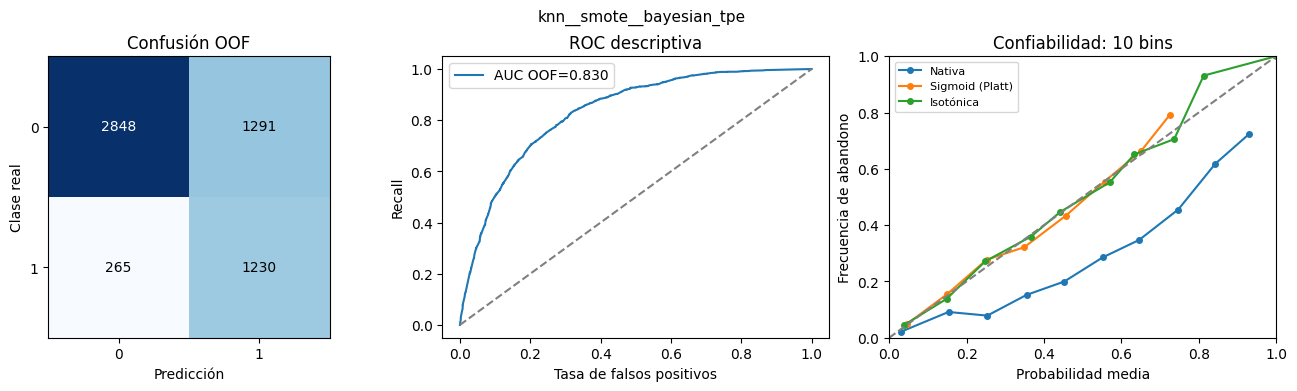

In [10]:
panel_evaluacion('knn__smote__bayesian_tpe')

Lectura del panel. La matriz OOF registra TN=2848, FP=1291, FN=265 y TP=1230; los 265 falsos negativos son abandonos omitidos y las 1291 falsas alertas afectan a permanentes. La ROC representa el orden de scores a distintos umbrales; el AUC medio por fold es 0.8307, sin confundirse con el AUC de predicciones concatenadas. En confiabilidad, la curva nativa queda muy por debajo de la diagonal: el modelo promete más abandono del que ocurre. Brier pasa de 0.1824 a 0.1414 con sigmoid y a 0.1417 con isotónica; ECE baja de 0.1719 a 0.0219 y 0.0267 (medias externas). Aquí Platt gana por poco, algo esperable con un score de pocos valores como la fracción de vecinos. La calibración se ajustó dentro de entrenamiento y no cambia el ranking principal de F1; no se selecciona una nueva variante mirando este panel.

#### Resultados de Gaussian Naive Bayes

Se contrastan los cuatro balanceos y los cuatro optimizadores usando las mismas particiones. La referencia sin balanceo permite distinguir el cambio observado sin añadir otra familia de modelos.

In [11]:
tabla(resultados_familia('naive_bayes'))

Balanceo,Optimizador,F1 media ± DS,Recall media ± DS,Precision media ± DS,Accuracy media ± DS,AUC media ± DS,Brier nativo,ECE nativo
ADASYN,TPE,0.6090 ± 0.0177,0.8167 ± 0.0219,0.4856 ± 0.0180,0.7215 ± 0.0162,0.8310 ± 0.0093,0.237636,0.237411
ADASYN,Genético,0.6093 ± 0.0178,0.8167 ± 0.0219,0.4860 ± 0.0180,0.7219 ± 0.0162,0.8310 ± 0.0093,0.237616,0.237209
ADASYN,Grid,0.6091 ± 0.0178,0.8167 ± 0.0219,0.4858 ± 0.0181,0.7217 ± 0.0163,0.8310 ± 0.0093,0.237630,0.237127
ADASYN,Random,0.6091 ± 0.0178,0.8167 ± 0.0219,0.4858 ± 0.0181,0.7217 ± 0.0163,0.8310 ± 0.0093,0.237622,0.237273
Ponderación,TPE,0.6114 ± 0.0185,0.8067 ± 0.0253,0.4924 ± 0.0185,0.7277 ± 0.0162,0.8301 ± 0.0099,0.236166,0.237333
Ponderación,Genético,0.6116 ± 0.0196,0.8080 ± 0.0256,0.4923 ± 0.0199,0.7275 ± 0.0174,0.8300 ± 0.0097,0.236185,0.235592
Ponderación,Grid,0.6114 ± 0.0185,0.8067 ± 0.0253,0.4924 ± 0.0185,0.7277 ± 0.0162,0.8301 ± 0.0099,0.236123,0.237051
Ponderación,Random,0.6127 ± 0.0193,0.8080 ± 0.0256,0.4936 ± 0.0192,0.7288 ± 0.0166,0.8300 ± 0.0097,0.236460,0.236461
Sin balanceo,TPE,0.6197 ± 0.0169,0.7726 ± 0.0185,0.5177 ± 0.0219,0.7481 ± 0.0164,0.8301 ± 0.0097,0.214448,0.207942
Sin balanceo,Genético,0.6194 ± 0.0174,0.7732 ± 0.0203,0.5170 ± 0.0220,0.7476 ± 0.0165,0.8304 ± 0.0099,0.211640,0.204154


**Interpretación.** El mayor F1 medio observado fue 0.6198 ± 0.0180, con Sin balanceo y Random. Hay 1 configuración(es) empatada(s) en ese máximo a precisión numérica. La mejor configuración sin balanceo obtuvo 0.6198; la diferencia descriptiva es +0.0000. Se compara el máximo de cada grupo, no un efecto causal aislado del balanceo. Recall=0.7739, Precision=0.5172 y AUC=0.8301 muestran aspectos distintos del desempeño. La selección por máximo entre configuraciones debe interpretarse con cautela. Los valores nativos de Brier/ECE se analizan junto con la rama calibrada, sin utilizarlos para seleccionar hiperparámetros.

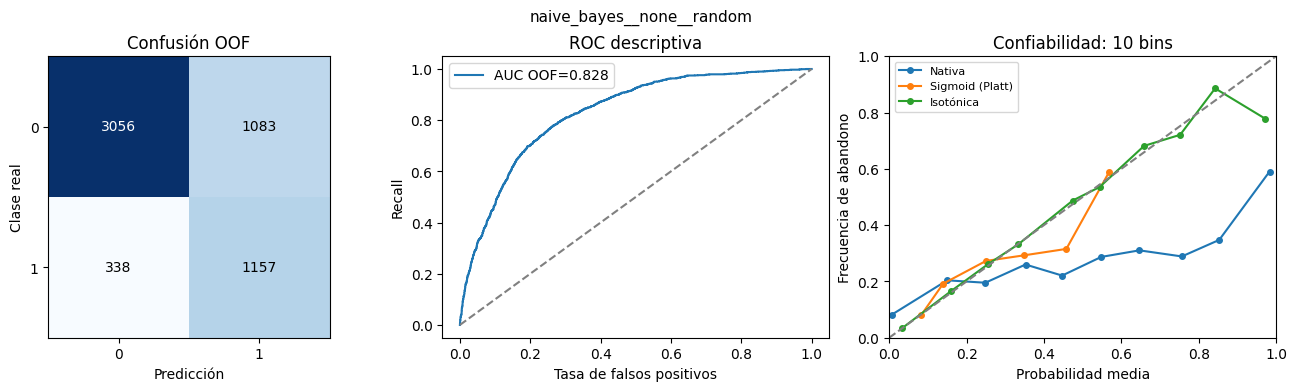

In [12]:
panel_evaluacion('naive_bayes__none__random')

Lectura del panel. La matriz OOF registra TN=3056, FP=1083, FN=338 y TP=1157; los 338 falsos negativos son abandonos omitidos y las 1083 falsas alertas afectan a permanentes. La ROC representa el orden de scores a distintos umbrales; el AUC medio por fold es 0.8301, sin confundirse con el AUC de predicciones concatenadas. En confiabilidad, GaussianNB empuja casi todas las probabilidades hacia 0 o 1, el comportamiento típico cuando el supuesto de independencia no se cumple. Brier pasa de 0.2135 a 0.1471 con sigmoid y a 0.1417 con isotónica; ECE baja de 0.2063 a 0.0278 y 0.0280. Es la familia donde la flexibilidad isotónica rinde más en Brier, porque la distorsión no tiene forma de S. La calibración se ajustó dentro de entrenamiento y no cambia el ranking principal de F1; no se selecciona una nueva variante mirando este panel.

#### Resultados de Regresión Logística

Se contrastan los cuatro balanceos y los cuatro optimizadores usando las mismas particiones. La referencia sin balanceo permite distinguir el cambio observado sin añadir otra familia de modelos.

In [13]:
tabla(resultados_familia('logistic'))

Balanceo,Optimizador,F1 media ± DS,Recall media ± DS,Precision media ± DS,Accuracy media ± DS,AUC media ± DS,Brier nativo,ECE nativo
ADASYN,TPE,0.6223 ± 0.0176,0.8054 ± 0.0181,0.5075 ± 0.0220,0.7403 ± 0.0180,0.8421 ± 0.0092,0.173626,0.181705
ADASYN,Genético,0.6213 ± 0.0144,0.8147 ± 0.0158,0.5027 ± 0.0229,0.7361 ± 0.0187,0.8434 ± 0.0092,0.172609,0.176879
ADASYN,Grid,0.6229 ± 0.0181,0.8000 ± 0.0198,0.5103 ± 0.0220,0.7426 ± 0.0178,0.8405 ± 0.0101,0.175171,0.185483
ADASYN,Random,0.6222 ± 0.0173,0.8140 ± 0.0215,0.5036 ± 0.0179,0.7375 ± 0.0152,0.8430 ± 0.0109,0.172860,0.177177
Ponderación,TPE,0.6308 ± 0.0176,0.7920 ± 0.0163,0.5242 ± 0.0183,0.7538 ± 0.0143,0.8438 ± 0.0108,0.164755,0.152792
Ponderación,Genético,0.6321 ± 0.0172,0.7940 ± 0.0168,0.5252 ± 0.0198,0.7545 ± 0.0150,0.8436 ± 0.0113,0.164693,0.153407
Ponderación,Grid,0.6324 ± 0.0170,0.7920 ± 0.0124,0.5267 ± 0.0223,0.7554 ± 0.0165,0.8439 ± 0.0098,0.164560,0.152510
Ponderación,Random,0.6313 ± 0.0174,0.7933 ± 0.0163,0.5244 ± 0.0189,0.7540 ± 0.0145,0.8433 ± 0.0113,0.164795,0.153688
Sin balanceo,TPE,0.5979 ± 0.0109,0.5492 ± 0.0159,0.6578 ± 0.0362,0.8039 ± 0.0103,0.8458 ± 0.0092,0.135005,0.022722
Sin balanceo,Genético,0.5965 ± 0.0120,0.5478 ± 0.0156,0.6563 ± 0.0376,0.8032 ± 0.0110,0.8458 ± 0.0092,0.135023,0.023667


**Interpretación.** El mayor F1 medio observado fue 0.6340 ± 0.0188, con SMOTE y Grid. Hay 1 configuración(es) empatada(s) en ese máximo a precisión numérica. La mejor configuración sin balanceo obtuvo 0.5979; la diferencia descriptiva es +0.0361. Se compara el máximo de cada grupo, no un efecto causal aislado del balanceo. Recall=0.7806, Precision=0.5343 y AUC=0.8441 muestran aspectos distintos del desempeño. La selección por máximo entre configuraciones debe interpretarse con cautela. Los valores nativos de Brier/ECE se analizan junto con la rama calibrada, sin utilizarlos para seleccionar hiperparámetros.

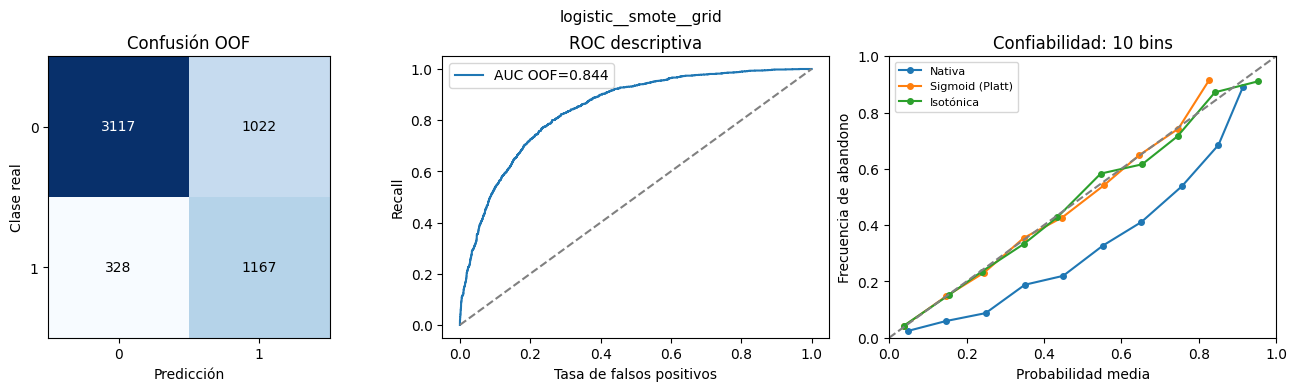

In [14]:
panel_evaluacion('logistic__smote__grid')

Lectura del panel. La matriz OOF registra TN=3117, FP=1022, FN=328 y TP=1167; los 328 falsos negativos son abandonos omitidos y las 1022 falsas alertas afectan a permanentes. La ROC representa el orden de scores a distintos umbrales; el AUC medio por fold es 0.8441, sin confundirse con el AUC de predicciones concatenadas. En confiabilidad, la logística entrenada con SMOTE conserva la forma sigmoide pero desplazada hacia arriba, justo el caso para el que Platt está pensado. Brier pasa de 0.1625 a 0.1356 con sigmoid y a 0.1358 con isotónica; ECE baja de 0.1442 a 0.0240 y 0.0242: las dos ramas prácticamente empatan. La calibración se ajustó dentro de entrenamiento y no cambia el ranking principal de F1; no se selecciona una nueva variante mirando este panel.

#### Resultados de Decision Tree

Se contrastan los cuatro balanceos y los cuatro optimizadores usando las mismas particiones. La referencia sin balanceo permite distinguir el cambio observado sin añadir otra familia de modelos.

In [15]:
tabla(resultados_familia('decision_tree'))

Balanceo,Optimizador,F1 media ± DS,Recall media ± DS,Precision media ± DS,Accuracy media ± DS,AUC media ± DS,Brier nativo,ECE nativo
ADASYN,TPE,0.6013 ± 0.0225,0.8194 ± 0.0456,0.4757 ± 0.0236,0.7116 ± 0.0224,0.8084 ± 0.0115,0.175174,0.134450
ADASYN,Genético,0.6013 ± 0.0225,0.8194 ± 0.0456,0.4757 ± 0.0236,0.7116 ± 0.0224,0.8084 ± 0.0115,0.175174,0.134450
ADASYN,Grid,0.6013 ± 0.0225,0.8194 ± 0.0456,0.4757 ± 0.0236,0.7116 ± 0.0224,0.8084 ± 0.0115,0.175174,0.134450
ADASYN,Random,0.6013 ± 0.0225,0.8194 ± 0.0456,0.4757 ± 0.0236,0.7116 ± 0.0224,0.8084 ± 0.0115,0.175174,0.134450
Ponderación,TPE,0.6055 ± 0.0268,0.7953 ± 0.0462,0.4893 ± 0.0240,0.7251 ± 0.0201,0.8251 ± 0.0121,0.173859,0.145143
Ponderación,Genético,0.6055 ± 0.0268,0.7953 ± 0.0462,0.4893 ± 0.0240,0.7251 ± 0.0201,0.8251 ± 0.0121,0.173859,0.145143
Ponderación,Grid,0.6055 ± 0.0268,0.7953 ± 0.0462,0.4893 ± 0.0240,0.7251 ± 0.0201,0.8251 ± 0.0121,0.173859,0.145143
Ponderación,Random,0.6055 ± 0.0268,0.7953 ± 0.0462,0.4893 ± 0.0240,0.7251 ± 0.0201,0.8251 ± 0.0121,0.173859,0.145143
Sin balanceo,TPE,0.5892 ± 0.0362,0.6181 ± 0.0354,0.5639 ± 0.0449,0.7709 ± 0.0251,0.8022 ± 0.0222,0.150477,0.031750
Sin balanceo,Genético,0.5892 ± 0.0362,0.6181 ± 0.0354,0.5639 ± 0.0449,0.7709 ± 0.0251,0.8022 ± 0.0222,0.150477,0.031750


**Interpretación.** El mayor F1 medio observado fue 0.6119 ± 0.0093, con SMOTE y TPE. Hay 4 configuración(es) empatada(s) en ese máximo a precisión numérica. La mejor configuración sin balanceo obtuvo 0.5892; la diferencia descriptiva es +0.0228. Se compara el máximo de cada grupo, no un efecto causal aislado del balanceo. Recall=0.7304, Precision=0.5270 y AUC=0.8242 muestran aspectos distintos del desempeño. La selección por máximo entre configuraciones debe interpretarse con cautela. Los valores nativos de Brier/ECE se analizan junto con la rama calibrada, sin utilizarlos para seleccionar hiperparámetros.

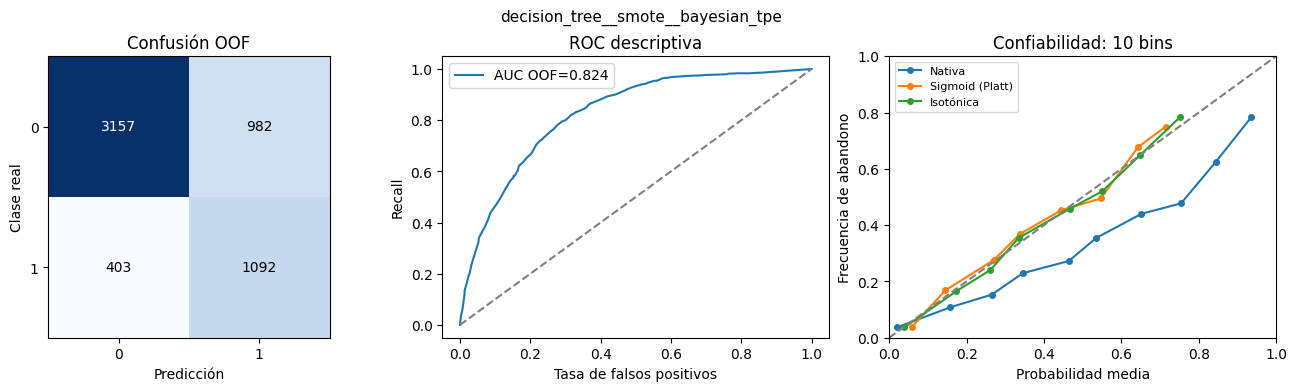

In [16]:
panel_evaluacion('decision_tree__smote__bayesian_tpe')

Lectura del panel. La matriz OOF registra TN=3157, FP=982, FN=403 y TP=1092; los 403 falsos negativos son abandonos omitidos y las 982 falsas alertas afectan a permanentes. La ROC representa el orden de scores a distintos umbrales; el AUC medio por fold es 0.8242, sin confundirse con el AUC de predicciones concatenadas. En confiabilidad, el árbol solo produce tantas probabilidades como hojas, y eso se nota en la curva escalonada. Brier pasa de 0.1672 a 0.1442 con sigmoid y a 0.1439 con isotónica; ECE baja de 0.1276 a 0.0371 y 0.0303. La isotónica se adapta mejor a esos saltos. La calibración se ajustó dentro de entrenamiento y no cambia el ranking principal de F1; no se selecciona una nueva variante mirando este panel.

#### Resultados de Random Forest

Se contrastan los cuatro balanceos y los cuatro optimizadores usando las mismas particiones. La referencia sin balanceo permite distinguir el cambio observado sin añadir otra familia de modelos.

In [17]:
tabla(resultados_familia('random_forest'))

Balanceo,Optimizador,F1 media ± DS,Recall media ± DS,Precision media ± DS,Accuracy media ± DS,AUC media ± DS,Brier nativo,ECE nativo
ADASYN,TPE,0.6226 ± 0.0146,0.7398 ± 0.0367,0.5385 ± 0.0219,0.7620 ± 0.0143,0.8420 ± 0.0071,0.155607,0.120915
ADASYN,Genético,0.6226 ± 0.0146,0.7398 ± 0.0367,0.5385 ± 0.0219,0.7620 ± 0.0143,0.8420 ± 0.0071,0.155607,0.120915
ADASYN,Grid,0.6226 ± 0.0146,0.7398 ± 0.0367,0.5385 ± 0.0219,0.7620 ± 0.0143,0.8420 ± 0.0071,0.155607,0.120915
ADASYN,Random,0.6226 ± 0.0146,0.7398 ± 0.0367,0.5385 ± 0.0219,0.7620 ± 0.0143,0.8420 ± 0.0071,0.155607,0.120915
Ponderación,TPE,0.6338 ± 0.0121,0.7585 ± 0.0148,0.5444 ± 0.0146,0.7673 ± 0.0101,0.8454 ± 0.0086,0.153934,0.120149
Ponderación,Genético,0.6338 ± 0.0121,0.7585 ± 0.0148,0.5444 ± 0.0146,0.7673 ± 0.0101,0.8454 ± 0.0086,0.153934,0.120149
Ponderación,Grid,0.6338 ± 0.0121,0.7585 ± 0.0148,0.5444 ± 0.0146,0.7673 ± 0.0101,0.8454 ± 0.0086,0.153934,0.120149
Ponderación,Random,0.6338 ± 0.0121,0.7585 ± 0.0148,0.5444 ± 0.0146,0.7673 ± 0.0101,0.8454 ± 0.0086,0.153934,0.120149
Sin balanceo,TPE,0.5741 ± 0.0149,0.5057 ± 0.0273,0.6662 ± 0.0324,0.8010 ± 0.0077,0.8390 ± 0.0119,0.137173,0.028636
Sin balanceo,Genético,0.5741 ± 0.0149,0.5057 ± 0.0273,0.6662 ± 0.0324,0.8010 ± 0.0077,0.8390 ± 0.0119,0.137173,0.028636


**Interpretación.** El mayor F1 medio observado fue 0.6384 ± 0.0227, con SMOTE y TPE. Hay 4 configuración(es) empatada(s) en ese máximo a precisión numérica. La mejor configuración sin balanceo obtuvo 0.5741; la diferencia descriptiva es +0.0644. Se compara el máximo de cada grupo, no un efecto causal aislado del balanceo. Recall=0.7351, Precision=0.5646 y AUC=0.8438 muestran aspectos distintos del desempeño. La selección por máximo entre configuraciones debe interpretarse con cautela. Los valores nativos de Brier/ECE se analizan junto con la rama calibrada, sin utilizarlos para seleccionar hiperparámetros.

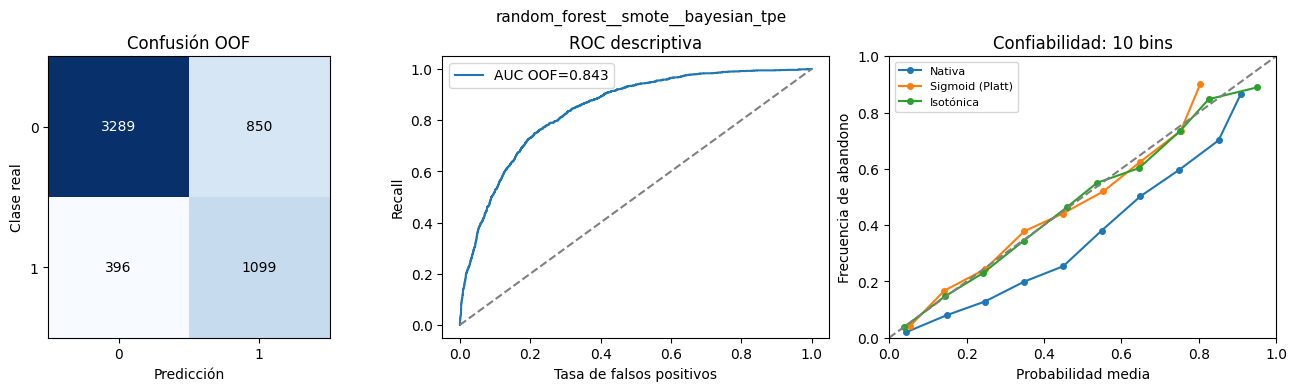

In [18]:
panel_evaluacion('random_forest__smote__bayesian_tpe')

Lectura del panel. La matriz OOF registra TN=3289, FP=850, FN=396 y TP=1099; los 396 falsos negativos son abandonos omitidos y las 850 falsas alertas afectan a permanentes. La ROC representa el orden de scores a distintos umbrales; el AUC medio por fold es 0.8438, sin confundirse con el AUC de predicciones concatenadas. En confiabilidad, Random Forest muestra la curva comprimida hacia el centro que suele dar el promedio de árboles, desplazada por SMOTE. Brier pasa de 0.1515 a 0.1363 con sigmoid y a 0.1361 con isotónica; ECE baja de 0.1106 a 0.0292 y 0.0269. La calibración se ajustó dentro de entrenamiento y no cambia el ranking principal de F1; no se selecciona una nueva variante mirando este panel.

#### Resultados de XGBoost

Se contrastan los cuatro balanceos y los cuatro optimizadores usando las mismas particiones. La referencia sin balanceo permite distinguir el cambio observado sin añadir otra familia de modelos.

In [19]:
tabla(resultados_familia('xgboost'))

Balanceo,Optimizador,F1 media ± DS,Recall media ± DS,Precision media ± DS,Accuracy media ± DS,AUC media ± DS,Brier nativo,ECE nativo
ADASYN,TPE,0.6285 ± 0.0158,0.7538 ± 0.0252,0.5398 ± 0.0268,0.7632 ± 0.0177,0.8440 ± 0.0084,0.152142,0.111942
ADASYN,Genético,0.6316 ± 0.0197,0.7478 ± 0.0529,0.5482 ± 0.0194,0.7689 ± 0.0122,0.8437 ± 0.0092,0.150512,0.102941
ADASYN,Grid,0.6252 ± 0.0093,0.7358 ± 0.0140,0.5437 ± 0.0122,0.7659 ± 0.0079,0.8442 ± 0.0083,0.150024,0.103376
ADASYN,Random,0.6266 ± 0.0177,0.7505 ± 0.0220,0.5388 ± 0.0315,0.7622 ± 0.0196,0.8434 ± 0.0091,0.152013,0.108792
Ponderación,TPE,0.6331 ± 0.0158,0.8194 ± 0.0136,0.5159 ± 0.0179,0.7478 ± 0.0146,0.8465 ± 0.0092,0.163745,0.151799
Ponderación,Genético,0.6269 ± 0.0170,0.7779 ± 0.0370,0.5255 ± 0.0164,0.7543 ± 0.0126,0.8430 ± 0.0105,0.160764,0.128049
Ponderación,Grid,0.6267 ± 0.0180,0.7940 ± 0.0448,0.5181 ± 0.0093,0.7494 ± 0.0077,0.8453 ± 0.0130,0.161467,0.138195
Ponderación,Random,0.6307 ± 0.0179,0.8067 ± 0.0168,0.5178 ± 0.0173,0.7492 ± 0.0141,0.8466 ± 0.0092,0.162373,0.143383
Sin balanceo,TPE,0.5845 ± 0.0216,0.5211 ± 0.0215,0.6680 ± 0.0520,0.8032 ± 0.0151,0.8469 ± 0.0086,0.134445,0.029692
Sin balanceo,Genético,0.5882 ± 0.0176,0.5284 ± 0.0223,0.6658 ± 0.0467,0.8035 ± 0.0131,0.8459 ± 0.0092,0.134915,0.027639


**Interpretación.** El mayor F1 medio observado fue 0.6380 ± 0.0206, con SMOTE y Random. Hay 1 configuración(es) empatada(s) en ese máximo a precisión numérica. La mejor configuración sin balanceo obtuvo 0.5887; la diferencia descriptiva es +0.0493. Se compara el máximo de cada grupo, no un efecto causal aislado del balanceo. Recall=0.7452, Precision=0.5585 y AUC=0.8461 muestran aspectos distintos del desempeño. La selección por máximo entre configuraciones debe interpretarse con cautela. Los valores nativos de Brier/ECE se analizan junto con la rama calibrada, sin utilizarlos para seleccionar hiperparámetros.

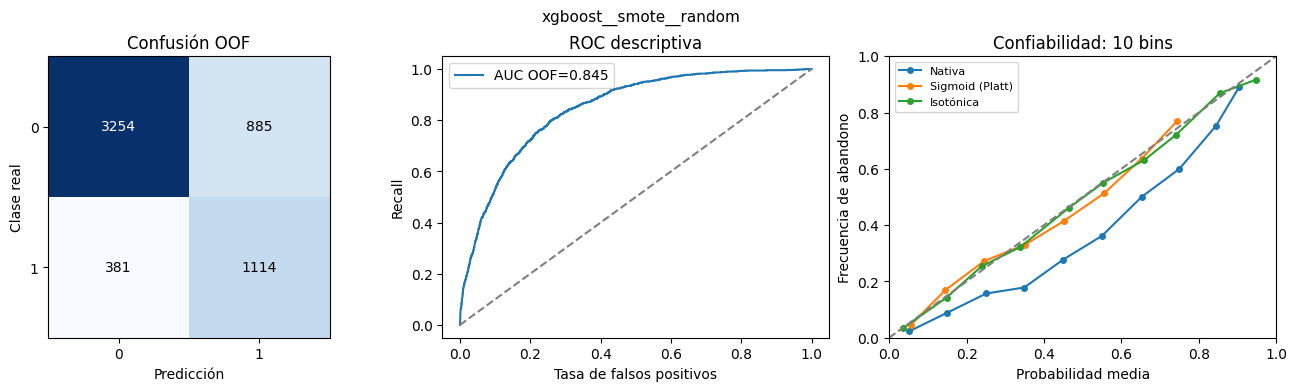

In [20]:
panel_evaluacion('xgboost__smote__random')

Lectura del panel. La matriz OOF registra TN=3254, FP=885, FN=381 y TP=1114; los 381 falsos negativos son abandonos omitidos y las 885 falsas alertas afectan a permanentes. La ROC representa el orden de scores a distintos umbrales; el AUC medio por fold es 0.8461, sin confundirse con el AUC de predicciones concatenadas. En confiabilidad, XGBoost sobreestima el abandono en todo el rango por efecto de SMOTE. Brier pasa de 0.1493 a 0.1357 con sigmoid y a 0.1359 con isotónica; ECE baja de 0.1030 a 0.0303 y 0.0281. La calibración se ajustó dentro de entrenamiento y no cambia el ranking principal de F1; no se selecciona una nueva variante mirando este panel.

#### Resultados de SVM RBF

Se contrastan los cuatro balanceos y los cuatro optimizadores usando las mismas particiones. La referencia sin balanceo permite distinguir el cambio observado sin añadir otra familia de modelos.

In [21]:
tabla(resultados_familia('svm'))

Balanceo,Optimizador,F1 media ± DS,Recall media ± DS,Precision media ± DS,Accuracy media ± DS,AUC media ± DS,Brier nativo,ECE nativo
ADASYN,TPE,0.6181 ± 0.0223,0.7893 ± 0.0441,0.5104 ± 0.0404,0.7401 ± 0.0321,0.8348 ± 0.0073,nan,nan
ADASYN,Genético,0.6194 ± 0.0189,0.8013 ± 0.0220,0.5049 ± 0.0181,0.7386 ± 0.0155,0.8370 ± 0.0093,nan,nan
ADASYN,Grid,0.6147 ± 0.0162,0.8033 ± 0.0196,0.4982 ± 0.0201,0.7325 ± 0.0172,0.8368 ± 0.0086,nan,nan
ADASYN,Random,0.6180 ± 0.0189,0.8187 ± 0.0408,0.4973 ± 0.0250,0.7311 ± 0.0226,0.8387 ± 0.0106,nan,nan
Ponderación,TPE,0.6254 ± 0.0170,0.7893 ± 0.0157,0.5181 ± 0.0203,0.7488 ± 0.0156,0.8403 ± 0.0098,nan,nan
Ponderación,Genético,0.6280 ± 0.0158,0.7860 ± 0.0132,0.5232 ± 0.0198,0.7527 ± 0.0148,0.8366 ± 0.0131,nan,nan
Ponderación,Grid,0.6255 ± 0.0192,0.7839 ± 0.0179,0.5205 ± 0.0198,0.7508 ± 0.0152,0.8385 ± 0.0101,nan,nan
Ponderación,Random,0.6268 ± 0.0164,0.7766 ± 0.0137,0.5258 ± 0.0219,0.7543 ± 0.0163,0.8385 ± 0.0097,nan,nan
Sin balanceo,TPE,0.5776 ± 0.0311,0.5217 ± 0.0289,0.6489 ± 0.0533,0.7973 ± 0.0183,0.8291 ± 0.0239,nan,nan
Sin balanceo,Genético,0.5739 ± 0.0260,0.5117 ± 0.0277,0.6561 ± 0.0546,0.7982 ± 0.0162,0.8236 ± 0.0207,nan,nan


**Interpretación.** El mayor F1 medio observado fue 0.6307 ± 0.0190, con SMOTE y Genético. Hay 1 configuración(es) empatada(s) en ese máximo a precisión numérica. La mejor configuración sin balanceo obtuvo 0.5776; la diferencia descriptiva es +0.0531. Se compara el máximo de cada grupo, no un efecto causal aislado del balanceo. Recall=0.7786, Precision=0.5304 y AUC=0.8392 muestran aspectos distintos del desempeño. La selección por máximo entre configuraciones debe interpretarse con cautela. En SVM, Brier/ECE nativos no aplican: su margen no es una probabilidad; se evalúa su rama sigmoid más adelante.

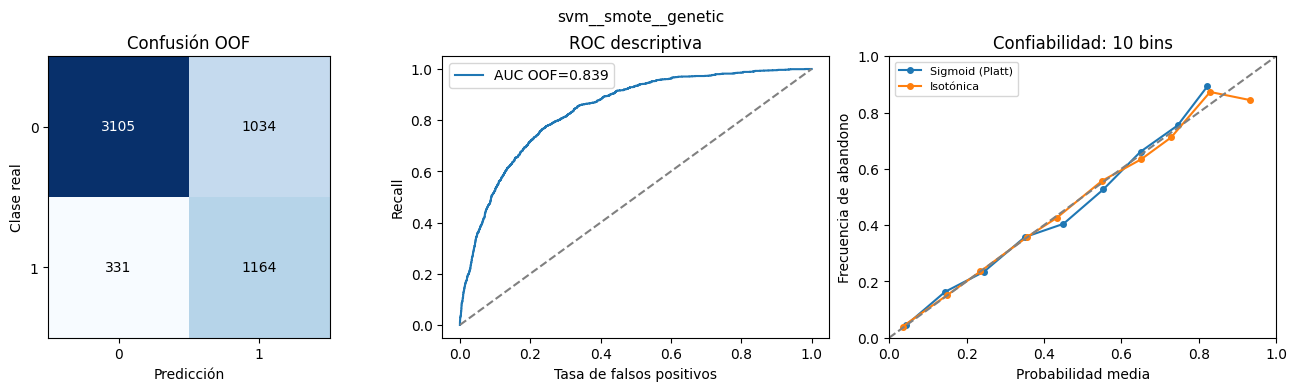

In [22]:
panel_evaluacion('svm__smote__genetic')

Lectura del panel. La matriz OOF registra TN=3105, FP=1034, FN=331 y TP=1164; los 331 falsos negativos son abandonos omitidos y las 1034 falsas alertas afectan a permanentes. La ROC representa el orden de scores a distintos umbrales; el AUC medio por fold es 0.8392, sin confundirse con el AUC de predicciones concatenadas. En confiabilidad, SVM no tiene probabilidad nativa: su margen se convierte en probabilidad solo a través de los recalibradores. La rama sigmoid logra Brier=0.1374 y ECE=0.0224; la isotónica, 0.1377 y 0.0243. Platt fue diseñado justamente para márgenes de SVM y aquí conserva una ligera ventaja. La calibración se ajustó dentro de entrenamiento y no cambia el ranking principal de F1; no se selecciona una nueva variante mirando este panel.

### 1.8 Síntesis de los resultados de calibración

La tabla reúne las siete configuraciones representativas con sus tres versiones de probabilidad. No se elige ninguna configuración nueva por su Brier: la selección sigue siendo la del F1 externo.

In [23]:
CALIBRACION=PRINCIPAL.merge(ISO_UNIDADES[['unit_id','iso_brier','iso_ece','iso_f1_positive']],on='unit_id')\
    .groupby('experiment_id')[['brier','ece','cal_brier','cal_ece','iso_brier','iso_ece','f1_positive','cal_f1_positive','iso_f1_positive']].mean().reset_index()
vista=REPRESENTANTES[['model','experiment_id']].merge(CALIBRACION,on='experiment_id')
tabla(vista[['model','brier','cal_brier','iso_brier','ece','cal_ece','iso_ece']].rename(columns={
    'brier':'Brier nativo','cal_brier':'Brier sigmoid','iso_brier':'Brier isotónica',
    'ece':'ECE nativo','cal_ece':'ECE sigmoid','iso_ece':'ECE isotónica'}))

model,Brier nativo,Brier sigmoid,Brier isotónica,ECE nativo,ECE sigmoid,ECE isotónica
knn,0.182422,0.141382,0.141690,0.171907,0.021850,0.026684
naive_bayes,0.213502,0.147100,0.141675,0.206323,0.027783,0.028031
logistic,0.162460,0.135551,0.135752,0.144164,0.024028,0.024207
decision_tree,0.167224,0.144154,0.143853,0.127564,0.037105,0.030278
random_forest,0.151500,0.136309,0.136131,0.110593,0.029157,0.026941
xgboost,0.149327,0.135692,0.135914,0.103044,0.030251,0.028122
svm,nan,0.137434,0.137718,nan,0.022380,0.024253


**Interpretación.** En los representantes, las dos recalibraciones recortan el ECE a una fracción de su valor nativo (de 0.10–0.21 a 0.02–0.04) y el Brier entre 9 % y 34 %. La diferencia entre ellas es de otro orden de magnitud: en Brier nunca supera 0.006 y casi siempre está en la cuarta cifra decimal. La isotónica saca su ventaja más visible en GaussianNB, cuyas probabilidades extremas no siguen una forma de S, y en el árbol, cuyas probabilidades son escalones; en Random Forest y XGBoost recorta un poco más el ECE, en la logística empata y en KNN y SVM gana Platt. Con unas 1.500 observaciones de calibración por fold, la isotónica no mostró el sobreajuste típico de muestras pequeñas, aunque entrega pocas probabilidades distintas por fold (en promedio, de 14 en el árbol a 41 en la logística) frente al continuo de Platt.

Comparación,Configuraciones,Total
Sigmoid mejora a nativa (Brier y ECE),80,96
Isotónica mejora a nativa (Brier y ECE),84,96
Isotónica con menor Brier que sigmoid,67,112
Isotónica con menor ECE que sigmoid,74,112


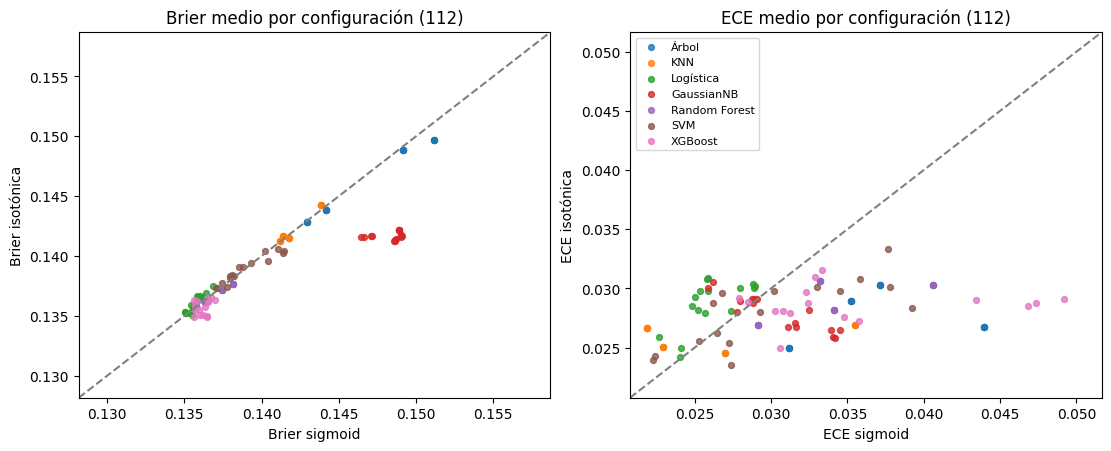

In [24]:
con_nativa=CALIBRACION.dropna(subset=['brier'])
conteo=pd.DataFrame([
    {'Comparación':'Sigmoid mejora a nativa (Brier y ECE)','Configuraciones':int(((con_nativa.cal_brier<con_nativa.brier)&(con_nativa.cal_ece<con_nativa.ece)).sum()),'Total':len(con_nativa)},
    {'Comparación':'Isotónica mejora a nativa (Brier y ECE)','Configuraciones':int(((con_nativa.iso_brier<con_nativa.brier)&(con_nativa.iso_ece<con_nativa.ece)).sum()),'Total':len(con_nativa)},
    {'Comparación':'Isotónica con menor Brier que sigmoid','Configuraciones':int((CALIBRACION.iso_brier<CALIBRACION.cal_brier).sum()),'Total':len(CALIBRACION)},
    {'Comparación':'Isotónica con menor ECE que sigmoid','Configuraciones':int((CALIBRACION.iso_ece<CALIBRACION.cal_ece).sum()),'Total':len(CALIBRACION)}])
tabla(conteo)
fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout='constrained')
for ax,(a,b,titulo) in zip(axes,[('cal_brier','iso_brier','Brier'),('cal_ece','iso_ece','ECE')]):
    for model,g in CALIBRACION.assign(model=CALIBRACION.experiment_id.str.split('__').str[0]).groupby('model'):
        ax.scatter(g[a],g[b],s=18,label=NOMBRES[model],alpha=.8)
    lim=[CALIBRACION[[a,b]].min().min()*.95,CALIBRACION[[a,b]].max().max()*1.05]
    ax.plot(lim,lim,'--',color='gray'); ax.set(xlim=lim,ylim=lim,xlabel=f'{titulo} sigmoid',ylabel=f'{titulo} isotónica',title=f'{titulo} medio por configuración (112)')
axes[1].legend(fontsize=8); plt.show(); plt.close(fig)

**Interpretación.** En el universo completo, la isotónica mejora a la vez Brier y ECE frente a la probabilidad nativa en 84 de las 96 configuraciones que la tienen (sigmoid lo logra en 80). Entre ellas, la isotónica tiene menor ECE que sigmoid en 74 de 112 configuraciones y menor Brier en 67. En la figura casi todos los puntos caen pegados a la diagonal: las dos ramas corrigen el mismo sesgo y la elección entre ellas mueve el Brier en la cuarta cifra decimal. La conclusión práctica es usar isotónica cuando la distorsión no tiene forma de S (GaussianNB, árboles) y Platt cuando el score ya es un margen o una fracción de vecinos (SVM, KNN). Un aviso sobre el F1: calibrar desplaza las probabilidades hacia la prevalencia real y, con el umbral fijo en 0.5, las dos ramas detectan menos abandonos: el F1 de casi todos los representantes baja, hasta 0.10 en el árbol, y solo GaussianNB con sigmoid lo mantiene. La calibración sirve para leer las probabilidades como riesgos; para decidir a quién contactar habría que elegir el umbral con costos explícitos, no reutilizar el 0.5.

### 1.9 Robustez algorítmica e intervalos de confianza

Las tres realizaciones comparten folds, pero varían las semillas de optimización, modelo y remuestreo. Se muestran las medias externas por realización de los representantes elegidos usando solo la realización principal. La dispersión entre ellas describe sensibilidad algorítmica con particiones fijas; no estima variación por obtener otros clientes.

Los IC de F1 ya guardados emplean 2.000 remuestreos estratificados condicionales por fold, con modelos fijos. El remuestreo equivalente de conteos de confusión evita materializar filas repetidas. Se agregan para el estimando de media condicional de los folds. No incorporan reentrenamiento, selección entre 112 configuraciones ni incertidumbre por nuevos folds y no se utilizan como pruebas de superioridad.

In [25]:
def conditional_f1_intervals(units,draws=2000):
    """Bootstrap estratificado condicional de sujetos, con modelos fijos."""
    intervals=[]
    for eid,g in units.groupby('experiment_id'):
        samples=[]
        for r in g.sort_values('outer_fold').itertuples():
            rng=np.random.default_rng(np.random.SeedSequence([42,101,int(r.outer_fold)]))
            pos=int(r.tp+r.fn); neg=int(r.tn+r.fp)
            tp=rng.binomial(pos,r.tp/pos,draws); fp=rng.binomial(neg,r.fp/neg,draws)
            f1=2*tp/(pos+tp+fp); samples.append(f1)
            low,high=np.quantile(f1,[.025,.975])
            intervals.append({'experiment_id':eid,'scope':'fold','fold':r.outer_fold,'low':low,'high':high,'draws':draws})
        low,high=np.quantile(np.mean(samples,axis=0),[.025,.975])
        intervals.append({'experiment_id':eid,'scope':'conditional_mean','fold':-1,'low':low,'high':high,'draws':draws})
    return pd.DataFrame(intervals)

In [26]:
SEMILLAS=UNIDADES.groupby(['experiment_id','replicate']).f1_positive.agg(['mean','std']).reset_index()
IC=leer_tabla('ic_f1_condicional.csv') if not RECALCULAR_COSTOSO else conditional_f1_intervals(PRINCIPAL)
vista=REPRESENTANTES[['model','experiment_id','f1_positive_mean','f1_positive_std']].merge(SEMILLAS.pivot(index='experiment_id',columns='replicate',values='mean').rename(columns={0:'F1 semilla 0',1:'F1 semilla 1',2:'F1 semilla 2'}),on='experiment_id').merge(IC[IC.scope=='conditional_mean'][['experiment_id','low','high']],on='experiment_id')
tabla(vista.drop(columns='experiment_id'))

model,f1_positive_mean,f1_positive_std,F1 semilla 0,F1 semilla 1,F1 semilla 2,low,high
knn,0.612558,0.011775,0.612558,0.614669,0.614094,0.598891,0.626232
naive_bayes,0.619778,0.018036,0.619778,0.620273,0.619286,0.604782,0.634280
logistic,0.633953,0.018815,0.633953,0.629117,0.630971,0.619104,0.648796
decision_tree,0.611928,0.009268,0.611928,0.600635,0.603422,0.595950,0.628098
random_forest,0.638421,0.022715,0.638421,0.635334,0.631245,0.620984,0.654315
xgboost,0.637990,0.020556,0.637990,0.630217,0.635326,0.620321,0.653019
svm,0.630705,0.019006,0.630705,0.629668,0.623302,0.615201,0.646284


**Interpretación.** La DS externa resume cinco folds de una realización; las columnas por semilla resumen variación algorítmica sobre los mismos folds. `low` y `high` delimitan IC condicionales del 95 %. Solapamiento o separación visual no constituye un contraste pareado válido. Los empates entre optimizadores en espacios agotados pueden coexistir con cambios entre realizaciones, debido a modelo o remuestreo.

## 2. Comparación de métodos de optimización

### 2.1 Calidad interna a igual presupuesto y convergencia

Se emparejan búsquedas por modelo, balanceo, realización y fold. A 8, 16 y 24 evaluaciones se compara el mejor F1 interno acumulado y el tiempo con Grid. Son 420 comparaciones por optimizador y presupuesto. Esta lectura responde a eficiencia de búsqueda; no reemplaza las métricas externas ya presentadas.

In [27]:
TRAZAS=leer_tabla('anytime.csv')
keys=['model','balance','replicate','outer_fold','evaluation']
grid=TRAZAS[TRAZAS.optimizer=='grid'][keys+['best_inner_f1','seconds']]
comparacion=TRAZAS.merge(grid,on=keys,suffixes=('','_grid'))
comparacion['gain_f1_vs_grid']=comparacion.best_inner_f1-comparacion.best_inner_f1_grid
comparacion['time_ratio_vs_grid']=comparacion.seconds/comparacion.seconds_grid
EFICIENCIA=comparacion[comparacion.evaluation.isin([8,16,24])].groupby(['optimizer','evaluation']).agg(
    mean_f1_gain=('gain_f1_vs_grid','mean'),median_time_ratio=('time_ratio_vs_grid','median'),
    fraction_higher=('gain_f1_vs_grid',lambda x: float((x>1e-12).mean())),comparisons=('gain_f1_vs_grid','size')).reset_index()
tabla(EFICIENCIA)

optimizer,evaluation,mean_f1_gain,median_time_ratio,fraction_higher,comparisons
bayesian_tpe,8,0.006853,1.077859,0.519048,420
bayesian_tpe,16,0.000925,1.040511,0.511905,420
bayesian_tpe,24,0.000353,0.997345,0.347619,420
genetic,8,0.006322,1.064522,0.478571,420
genetic,16,0.000363,1.043481,0.426190,420
genetic,24,-0.000054,0.999089,0.261905,420
grid,8,0.000000,1.000000,0.000000,420
grid,16,0.000000,1.000000,0.000000,420
grid,24,0.000000,1.000000,0.000000,420
random,8,0.006559,1.061655,0.509524,420


**Interpretación.** A ocho evaluaciones, TPE, Genético y Random aventajan descriptivamente a Grid en F1 interno medio en 0,00685, 0,00632 y 0,00656. A 24, las diferencias son 0,00035, −0,00005 y −0,00033, con razones medianas de tiempo próximas a uno. No se observa una ventaja universal de calidad o velocidad. El orden de Grid, los rangos continuos y el agotamiento de dominios finitos condicionan la comparación; estos deltas internos no son ganancias de generalización.

In [28]:
def grafico_anytime(por_tiempo=False):
    """Resume el mejor F1 interno por evaluación y luego por familia."""
    series=TRAZAS.groupby(['model','balance','optimizer','evaluation']).agg(f1=('best_inner_f1','mean'),seconds=('seconds','mean')).reset_index()
    fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained')
    for ax,(model,g) in zip(axes.flat,series.groupby('model')):
        for opt,datos in g.groupby('optimizer'):
            curve=datos.groupby('evaluation')[['f1','seconds']].mean()
            ax.plot(curve.seconds if por_tiempo else curve.index,curve.f1,label=opt)
        ax.set(title=model,xlabel='Tiempo acumulado (s)' if por_tiempo else 'Evaluaciones únicas',ylabel='Mejor F1 interno')
    axes.flat[-1].axis('off'); axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(),loc='center')
    plt.show(); plt.close(fig)

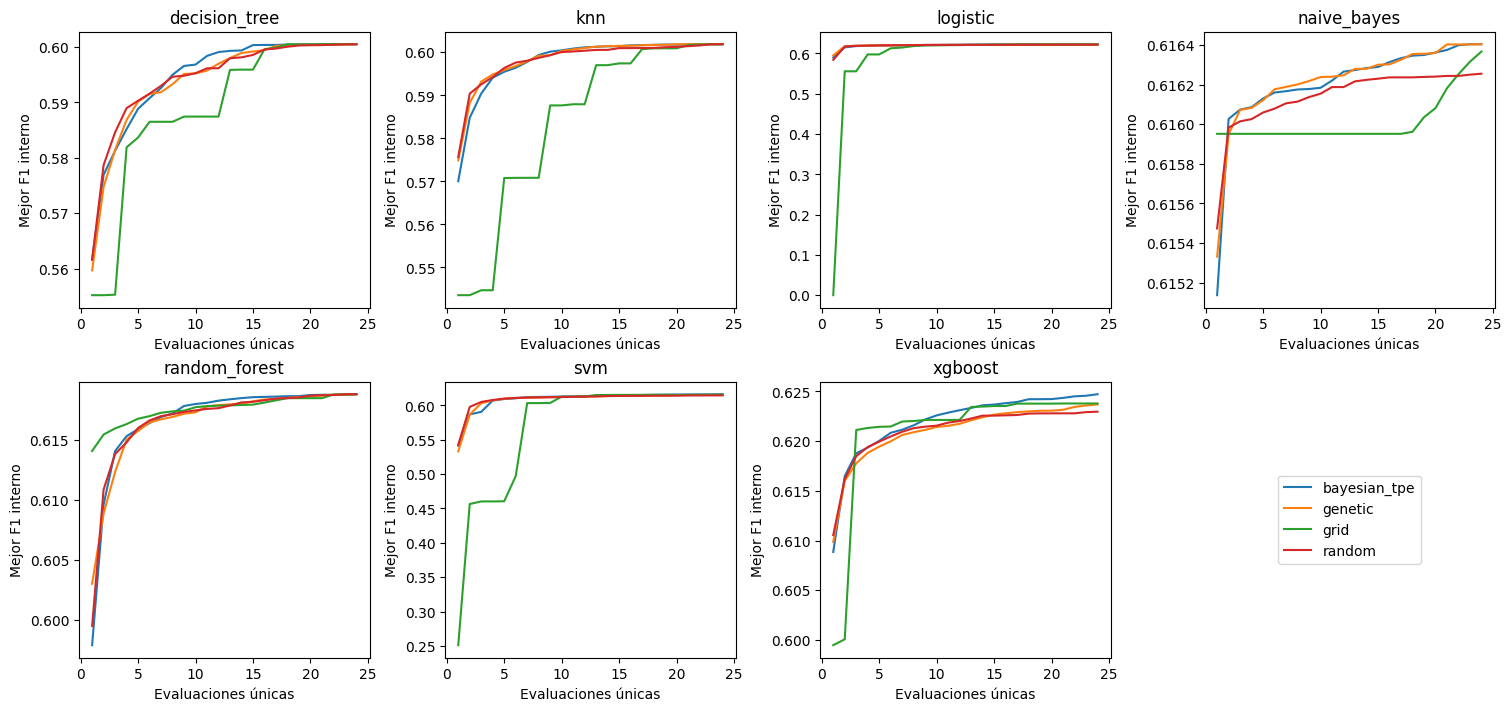

In [29]:
grafico_anytime()

**Interpretación.** Cada trayectoria muestra el mejor F1 interno medio acumulado por familia y evaluaciones únicas. Las subidas indican que se encontró un candidato interno mejor; una meseta significa ausencia de mejora dentro del presupuesto visitado. En dominios finitos agotados, el mismo resultado final no distingue eficiencia temprana ni prueba equivalencia de los algoritmos en otros espacios.

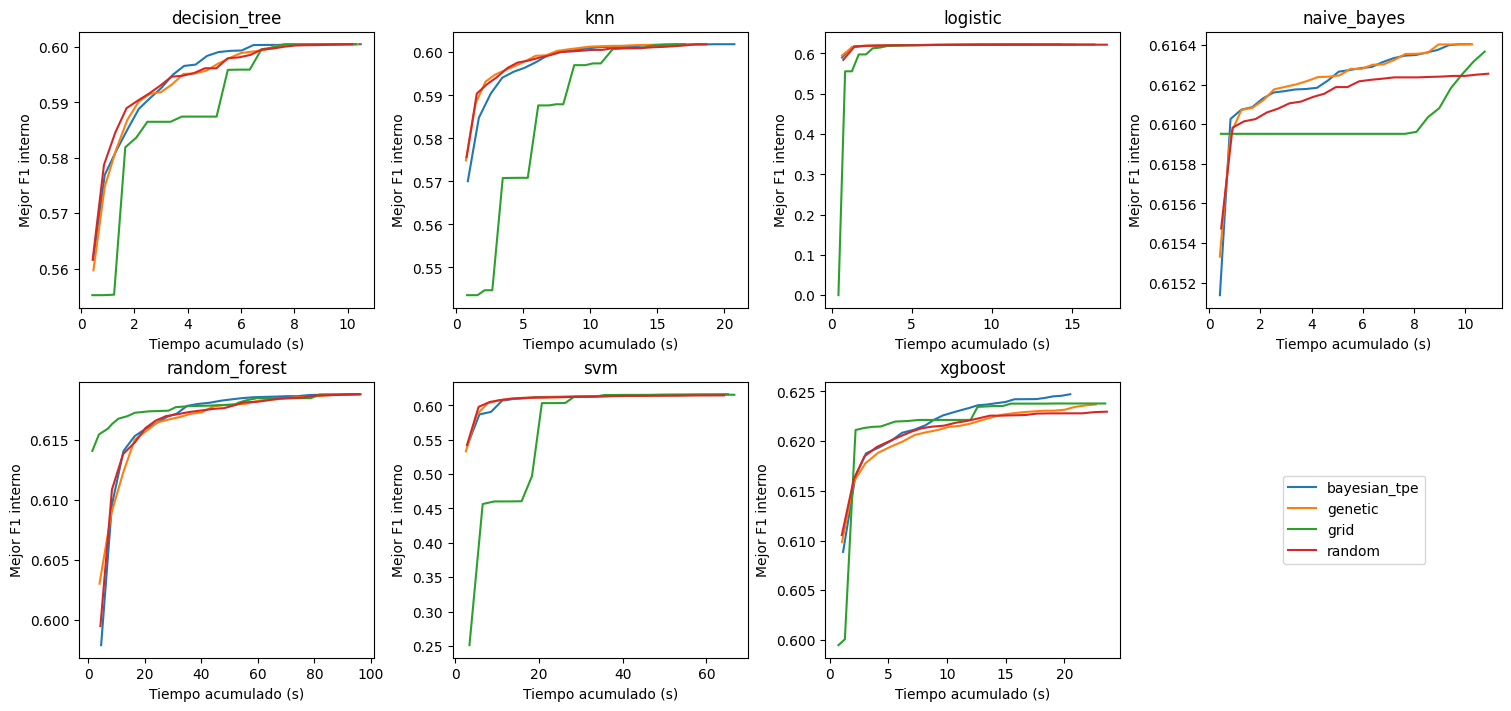

In [30]:
grafico_anytime(por_tiempo=True)

**Interpretación.** El eje temporal permite observar el coste de alcanzar los valores internos, que varía entre familias. Las trayectorias combinan búsquedas emparejadas pero no forman un experimento con presupuestos temporales iguales. La carga del equipo y los hiperparámetros influyen en los tiempos; no se atribuye causalmente a un optimizador cualquier separación visual.

#### Diversidad del algoritmo genético

Se registró la fracción de genotipos únicos y la distancia normalizada entre individuos. En genes continuos se usa distancia en su representación normalizada y en categorías discrepancia entre índices. Estas medidas detectan pérdida de diversidad sin evaluar otra vez los modelos.

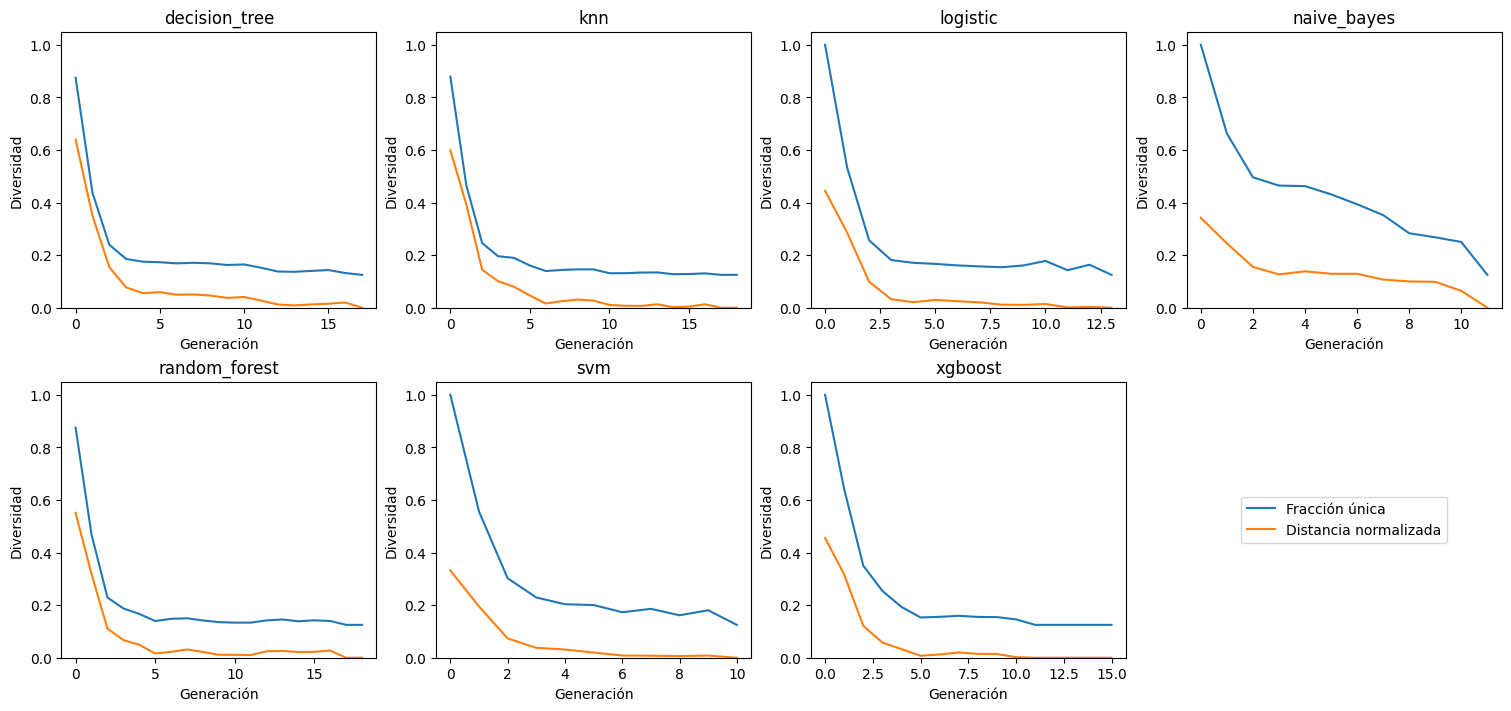

In [31]:
DIVERSIDAD=leer_tabla('diversidad.csv')
DIVERSIDAD['model']=DIVERSIDAD.experiment_id.str.split('__').str[0]
div=DIVERSIDAD.groupby(['model','generation']).agg(unique_fraction=('unique_fraction','mean'),
    mean_distance=('mean_normalized_distance','mean'),searches=('experiment_id','size')).reset_index()
fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained')
for ax,(model,g) in zip(axes.flat,div.groupby('model')):
    ax.plot(g.generation,g.unique_fraction,label='Fracción única')
    ax.plot(g.generation,g.mean_distance,label='Distancia normalizada')
    ax.set(title=model,xlabel='Generación',ylabel='Diversidad',ylim=(0,1.05))
axes.flat[-1].axis('off'); axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(),loc='center')
plt.show(); plt.close(fig)

**Interpretación.** La fracción única y la distancia describen aspectos diferentes: individuos distintos pueden estar cerca en el espacio genético. Elitismo conserva el mejor fitness; mutación y el inmigrante de rescate permiten introducir novedad. Las medias por generación incluyen solo búsquedas que llegaron a esa generación, de modo que no se interpretan como una única población longitudinal ni como evidencia de convergencia global.

### 2.2 Presupuesto y coste empírico

Las 40.320 evaluaciones de candidatos requirieron 120.960 ajustes internos. Se añadieron 1.680 reajustes externos y 6.720 ajustes de la rama calibrada: 129.360 ajustes lógicos oficiales. Los 219 ajustes posteriores de modelos finales y los benchmarks auxiliares se contabilizan aparte; no amplían las 112 configuraciones ni sus 1.680 resultados externos.

Los tiempos de búsqueda, reajuste y predicción se registraron por separado. La suma de tiempos de búsqueda no es necesariamente el tiempo de calendario de la sesión completa: excluye pausas y parte de gestión de archivos. RSS es memoria muestreada del proceso y sus hijos, no memoria incremental exclusiva de cada algoritmo.

In [32]:
COSTE=UNIDADES.groupby(['model','optimizer']).agg(search_mean=('search_seconds','mean'),search_std=('search_seconds','std'),
    refit_mean=('refit_seconds','mean'),inference_mean=('predict_seconds','mean'),rss_mean_mib=('rss_peak_mib','mean'),
    evaluations=('evaluations','sum'),proposals=('proposals','sum')).reset_index()
COSTE['seconds_per_evaluation']=COSTE.search_mean/24
tabla(COSTE)

model,optimizer,search_mean,search_std,refit_mean,inference_mean,rss_mean_mib,evaluations,proposals,seconds_per_evaluation
decision_tree,bayesian_tpe,10.509632,0.851135,0.099844,0.034052,771.712109,1440,5845,0.437901
decision_tree,genetic,10.392301,0.684198,0.099292,0.034351,790.476172,1440,8174,0.433013
decision_tree,grid,10.314076,0.825864,0.101076,0.034353,763.108333,1440,1440,0.429753
decision_tree,random,10.172951,0.738376,0.099432,0.034005,737.460807,1440,1440,0.423873
knn,bayesian_tpe,20.762010,12.517672,0.111063,0.230639,575.600260,1440,5578,0.865084
knn,genetic,18.221412,6.700885,0.098509,0.199774,555.839388,1440,8222,0.759226
knn,grid,17.072029,3.599684,0.091836,0.187231,568.018164,1440,1440,0.711335
knn,random,18.668043,9.184826,0.104894,0.203235,594.634961,1440,1440,0.777835
logistic,bayesian_tpe,14.287655,3.139603,0.154698,0.034872,667.001758,1440,1440,0.595319
logistic,genetic,15.187012,2.474469,0.171819,0.035428,642.661979,1440,5124,0.632792


**Interpretación.** `search_mean` y `search_std` describen tiempos por búsqueda; `seconds_per_evaluation` distribuye el tiempo medio entre 24 evaluaciones únicas. `evaluations` cuenta ajustes de candidatos, mientras `proposals` incluye intentos repetidos, por lo que no son sinónimos. Las diferencias reflejan familia, capacidad y coste de propuestas; un mayor tiempo no implica mejor clasificación. El tiempo de inferencia corresponde al bloque externo evaluado, no a una sola consulta.

### 2.3 Complejidad asintótica y contraste con mediciones

En las expresiones siguientes, $n$ es el tamaño efectivo después de balancear, $p$ las columnas transformadas, $T$ árboles, $h$ profundidad, $B$ bins, $L$ hojas, $m$ variables candidatas por nodo, $I$ iteraciones y $n_{sv}$ vectores soporte. Las cotas describen operaciones bajo supuestos explícitos; no son tiempos garantizados.

El Pipeline añade transformaciones de orden $O(np)$ y el remuestreo añade búsqueda de vecinos y generación sintética. La validación multiplica estos costes por candidatos y folds. La comparación empírica usa los mismos procedimientos reales, sin inferir exponentes a partir de un solo tamaño del dataset.

In [33]:
# Las cotas son expresiones teóricas, no estimaciones ajustadas a los tiempos.
COMPLEJIDAD=pd.DataFrame([{'model': 'knn', 'training_O': 'O(np) almacenamiento/validación', 'prediction_O': 'O(np + n log k) por consulta con selección heap conservadora', 'memory_O': 'O(np)', 'assumptions': 'brute; no se usaron índices ni vecinos aproximados'}, {'model': 'naive_bayes', 'training_O': 'O(np)', 'prediction_O': 'O(p) por consulta y dos clases', 'memory_O': 'O(p), además de los datos', 'assumptions': 'Estadísticas por clase; partial_fit no fue necesario'}, {'model': 'logistic', 'training_O': 'O(I np), aproximación por barridos; liblinear depende de problema primal/dual y tolerancia', 'prediction_O': 'O(p)', 'memory_O': 'O(np) con matriz densa', 'assumptions': 'I efectivo depende de condicionamiento; no se atribuye la complejidad de SAGA'}, {'model': 'decision_tree', 'training_O': 'O(p n log n) típico balanceado; O(p n²) cota degenerada', 'prediction_O': 'O(h)', 'memory_O': 'O(nodos)', 'assumptions': 'h: profundidad; el caso balanceado no es garantía universal'}, {'model': 'random_forest', 'training_O': 'O(T m n log n) típico; m variables candidatas', 'prediction_O': 'O(T h)', 'memory_O': 'O(T nodos)', 'assumptions': 'T árboles; suma de costes, no mejora asintótica por paralelizar'}, {'model': 'xgboost', 'training_O': 'O(T [n p h + p B L]) esquema de histogramas, más discretización inicial', 'prediction_O': 'O(T h)', 'memory_O': 'O(np + p B L + T L)', 'assumptions': 'B bins, L hojas; esquema de operaciones, depende de reutilización de histogramas'}, {'model': 'svm', 'training_O': 'Entre O(n²p) y O(n³p) como referencia del solver kernel, dependiente de datos/tolerancia', 'prediction_O': 'O(n_sv p)', 'memory_O': 'Caché kernel acotada + O(n_sv p)', 'assumptions': 'n_sv vectores soporte; no se sustituyó RBF por un clasificador lineal'}])
tabla(COMPLEJIDAD)

model,training_O,prediction_O,memory_O,assumptions
knn,O(np) almacenamiento/validación,O(np + n log k) por consulta con selección heap conservadora,O(np),brute; no se usaron índices ni vecinos aproximados
naive_bayes,O(np),O(p) por consulta y dos clases,"O(p), además de los datos",Estadísticas por clase; partial_fit no fue necesario
logistic,"O(I np), aproximación por barridos; liblinear depende de problema primal/dual y tolerancia",O(p),O(np) con matriz densa,I efectivo depende de condicionamiento; no se atribuye la complejidad de SAGA
decision_tree,O(p n log n) típico balanceado; O(p n²) cota degenerada,O(h),O(nodos),h: profundidad; el caso balanceado no es garantía universal
random_forest,O(T m n log n) típico; m variables candidatas,O(T h),O(T nodos),"T árboles; suma de costes, no mejora asintótica por paralelizar"
xgboost,"O(T [n p h + p B L]) esquema de histogramas, más discretización inicial",O(T h),O(np + p B L + T L),"B bins, L hojas; esquema de operaciones, depende de reutilización de histogramas"
svm,"Entre O(n²p) y O(n³p) como referencia del solver kernel, dependiente de datos/tolerancia",O(n_sv p),Caché kernel acotada + O(n_sv p),n_sv vectores soporte; no se sustituyó RBF por un clasificador lineal


**Interpretación.** KNN desplaza buena parte del costo a la consulta; GaussianNB y Logística tienen inferencia proporcional a p; los árboles dependen de su profundidad y los ensambles acumulan el costo de cada árbol. SVM RBF depende además del número de vectores soporte y de la convergencia del solver. Paralelizar reduce el tiempo de pared, pero no cambia estas cotas de trabajo. Las 112 configuraciones usaron las implementaciones exactas; las alternativas que cambian esas cotas (índices y vecinos aproximados en KNN, versiones lineales o aproximadas de SVM, método exacto frente a histogramas en XGBoost) se miden en la sección 2.6.

In [34]:
EMPIRICO=UNIDADES.groupby('model').agg(refit_seconds=('refit_seconds','mean'),predict_seconds=('predict_seconds','mean'),
    rss_mib=('rss_peak_mib','mean'),n_effective=('n_effective','mean'),p=('p','mean')).reset_index()
tabla(EMPIRICO)

model,refit_seconds,predict_seconds,rss_mib,n_effective,p
decision_tree,0.099911,0.034190,765.689355,5552.350000,24.000000
knn,0.101576,0.205220,573.523193,5552.350000,24.000000
logistic,0.168252,0.036033,646.079167,5552.350000,24.000000
naive_bayes,0.095977,0.038516,659.402474,5552.350000,24.000000
random_forest,1.031306,0.068359,514.554606,5552.350000,24.000000
svm,0.778343,0.498238,640.936230,5552.350000,24.000000
xgboost,0.231901,0.038426,749.828516,5552.350000,24.000000


**Interpretación.** Los reajustes medios de Random Forest (≈1,031 s) y SVM (≈0,778 s) superan los de GaussianNB (≈0,096 s), mientras SVM y KNN tienen el mayor costo de predicción por bloque (≈0,498 y ≈0,205 s). Es coherente con sus operaciones, pero esta tabla por sí sola no verifica una ley de escalamiento, porque mezcla hiperparámetros y tamaños tras balancear. Para eso, la sección 2.6 varía n y p de forma controlada y estima el exponente empírico de cada modelo.

### 2.4 Paralelización, profiling y mejora de la ejecución

El equipo utilizó CPU Intel Core Ultra 5 125H, 14 núcleos y 18 hilos lógicos, con aproximadamente 8 GB de RAM y sin GPU NVIDIA CUDA disponible. Se limitó el paralelismo a un nivel: hasta dos folds internos, estimadores e hilos numéricos acotados, y fallback serial si había menos de 1,5 GiB libres. Esto evita sobreasignación y presión de memoria; no se atribuye una aceleración GPU no medida.

El benchmark ya ejecutado repitió tres veces por familia un candidato fijado por selección interna, comparando solicitud de uno y dos trabajadores. Se exigió igualdad de F1 interno. El modo de dos trabajadores solicitados no garantiza dos trabajadores efectivos.

In [35]:
BENCH=leer_tabla('benchmark_ejecucion.csv')
BENCH_RESUMEN=BENCH.groupby(['model','requested_jobs']).agg(effective_jobs=('effective_jobs','max'),
    total_seconds=('total_seconds','mean'),total_std=('total_seconds','std'),training_seconds=('training_seconds_sum','mean'),
    inference_seconds=('inference_seconds_sum','mean'),rss_mib=('rss_peak_mib','mean'),f1_inner=('f1_inner','mean')).reset_index()
tabla(BENCH_RESUMEN)

model,requested_jobs,effective_jobs,total_seconds,total_std,training_seconds,inference_seconds,rss_mib,f1_inner
decision_tree,1,1,0.549846,0.019859,0.307447,0.153456,230.399740,0.591092
decision_tree,2,1,0.567312,0.009508,0.314901,0.153849,230.408854,0.591092
knn,1,1,0.891171,0.040271,0.265589,0.543940,229.917969,0.603012
knn,2,1,0.892162,0.061876,0.252053,0.540504,230.096354,0.603012
logistic,1,1,0.579627,0.030472,0.336491,0.147427,230.076823,0.600172
logistic,2,1,0.580377,0.019643,0.337192,0.152586,230.076823,0.600172
naive_bayes,1,1,0.550794,0.002142,0.298136,0.149958,229.800781,0.622807
naive_bayes,2,1,0.565233,0.062900,0.298886,0.165296,229.847656,0.622807
random_forest,1,1,2.870769,0.137470,2.551295,0.232057,230.549479,0.573173
random_forest,2,1,2.789937,0.040134,2.464335,0.222060,230.884115,0.573173


**Interpretación.** Durante el entrenamiento de las 112 configuraciones, la política de memoria activó un solo trabajador incluso cuando se pidieron dos. Los F1 internos son iguales, pero estos tiempos no demuestran aceleración por paralelismo. Esa medición quedó pendiente y se hizo después, sin la restricción de memoria, en la sección 2.6: allí sí se compara uno, dos, cuatro y ocho trabajadores, con los backends `loky` y `threading`.

In [36]:
def tabla_perfil(texto, filas=15):
    """Convierte la salida de pstats en una tabla: rutas locales recortadas y una fila por función."""
    resumen = re.search(r'(\d+) function calls(?: \((\d+) primitive calls\))? in ([\d.]+) seconds', texto)
    patron = re.compile(r'^\s*(\S+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+(.+)$')
    registros = []
    for linea in texto.splitlines():
        m = patron.match(linea)
        if m and m.group(1) != 'ncalls':
            funcion = m.group(6).replace(chr(92), '/')
            funcion = re.sub(r'^.*?site-packages/', '', funcion)
            registros.append([m.group(1), *map(float, m.group(2, 3, 4, 5)), funcion])
    frame = pd.DataFrame(registros[:filas], columns=['ncalls', 'tottime', 'percall (tottime)', 'cumtime',
                                                    'percall (cumtime)', 'filename:lineno(function)'])
    miles = lambda n: f'{int(n):,}'.replace(',', '.')
    titulo = (f'{miles(resumen.group(1))} llamadas a funciones ({miles(resumen.group(2) or resumen.group(1))} primitivas) '
              f'en {float(resumen.group(3)):.3f} s · ordenado por tiempo acumulado · primeras {len(frame)} funciones')
    estilo = (frame.style.hide(axis='index').format(precision=3).set_caption(titulo)
              .set_table_styles([
                  {'selector': 'caption', 'props': 'caption-side: top; font-size: 12px; padding: 6px 0; text-align: left;'},
                  {'selector': 'th', 'props': 'background-color: #1f4e79; color: white; font-weight: bold; '
                                              'padding: 8px 12px; border: 1px solid #d0d7de; text-align: left;'},
                  {'selector': 'td', 'props': 'padding: 6px 12px; border: 1px solid #d0d7de; font-size: 12px;'},
                  {'selector': 'tbody tr:nth-child(even)', 'props': 'background-color: #f2f6fa;'},
                  {'selector': 'tbody tr:nth-child(odd)', 'props': 'background-color: #ffffff;'}])
              .set_properties(subset=['filename:lineno(function)'], **{'font-family': 'monospace', 'white-space': 'nowrap'})
              .set_table_attributes('style="border-collapse: collapse; color: #1b1f23;"'))
    display(estilo)

# Se conserva la medición histórica: volver a perfilar requeriría otro ajuste.
tabla_perfil((ANALISIS/'perfil_logistica.txt').read_text(encoding='utf-8'))

ncalls,tottime,percall (tottime),cumtime,percall (cumtime),filename:lineno(function)
5/1,0.000,0.000,0.062,0.062,sklearn/base.py:1372(wrapper)
1,0.000,0.000,0.061,0.061,imblearn/pipeline.py:455(fit)
1,0.000,0.000,0.041,0.041,imblearn/pipeline.py:398(_fit)
3,0.000,0.000,0.041,0.014,joblib/memory.py:325(__call__)
2,0.000,0.000,0.041,0.020,imblearn/pipeline.py:1370(_fit_transform_one)
8/2,0.000,0.000,0.041,0.020,sklearn/utils/_set_output.py:317(wrapped)
3,0.000,0.000,0.037,0.012,sklearn/base.py:863(fit_transform)
1,0.000,0.000,0.023,0.023,sklearn/compose/_column_transformer.py:950(fit_transform)
1,0.000,0.000,0.022,0.022,sklearn/compose/_column_transformer.py:838(_call_func_on_transformers)
1,0.000,0.000,0.020,0.020,A08-adaptadores:72(fit)


**Interpretación.** El caso perfilado de Logística registró 0,063 s, con aproximadamente 0,041 s acumulados en preparación interna del Pipeline y 0,020 s en el adaptador de ajuste. Los tiempos acumulados incluyen llamadas anidadas y no deben sumarse como categorías independientes. Es un caso auxiliar, no una estimación del coste total de los 112 experimentos.

La lentitud creciente de la corrida se diagnosticó aparte como relectura y comprobación reiterada de todos los artefactos ya completados. Una caché administrativa verificó integralmente al iniciar y cerrar cada proceso y comprobó sellos entre bloques. En una prueba emparejada de doce unidades, la consulta pasó de 0,230 s a 0,029 s (8,08×) con resultados idénticos. Ese factor solo corresponde al registro, no al entrenamiento completo. Se mantuvieron presupuestos, semillas, checkpoints y lógica de evaluación; no se compartieron ajustes entre optimizadores.

### 2.5 Optimización multifidelidad: Successive Halving

Los cuatro optimizadores de la sección 1.6 gastan lo mismo en cada candidato, sea prometedor o no. La idea de la multifidelidad es otra: evaluar muchos candidatos de forma barata, descartar pronto los peores y reservar el presupuesto completo para los pocos que sobreviven. Successive Halving lo hace por rondas. Con factor de reducción $\eta=3$ y 27 candidatos iniciales:

| Ronda | Candidatos | Recurso por candidato |
|---|---|---|
| 1 | 27 | $r_{\max}/27$ |
| 2 | 9 | $r_{\max}/9$ |
| 3 | 3 | $r_{\max}/3$ |
| 4 | 1 | $r_{\max}$ |

En cada ronda pasa el tercio con mejor F1 interno. El costo total equivale a 4 ajustes completos por fold interno, frente a 24 de una búsqueda aleatoria normal: una reducción teórica de 6×.

**¿Qué se recorta en cada familia?** La fidelidad tiene que ser barata de reducir y, a la vez, ordenar a los candidatos de forma parecida a como lo haría el presupuesto completo.

- *Random Forest y XGBoost*: el número de árboles, de 12 a 324. Un bosque con pocos árboles es una versión más ruidosa del mismo modelo, y en boosting los primeros árboles ya capturan la mayor parte de la estructura, así que ambos son proxies naturales.
- *SVM*: el tamaño de la muestra de entrenamiento, de 111 a unas 3.000 filas. Es el recurso que más pesa en SVM, cuyo entrenamiento crece entre cuadrática y cúbicamente con $n$.

El factor 3 es el valor que suele recomendarse para Hyperband: con 2 se necesitan muchas rondas y se descarta poco en cada una; con valores mayores, una sola evaluación muy ruidosa a baja fidelidad puede eliminar a un buen candidato.

**Diseño de la comparación.** Para Random Forest, XGBoost y SVM con SMOTE se ejecutaron dos búsquedas en cada uno de los cinco folds externos de la realización principal: Successive Halving (`HalvingRandomSearchCV`) y una búsqueda aleatoria a fidelidad completa con 24 candidatos, el mismo presupuesto de la sección 1. Ambas usan el mismo Pipeline de la sección 1 (mismas semillas de modelo y de SMOTE), los mismos tres folds internos —reconstruidos y verificados contra su huella SHA-256— y el mismo objetivo, F1 de la clase abandono. También comparten la semilla del muestreo, de modo que los 24 candidatos de la búsqueda completa están entre los 27 que Successive Halving examina en su primera ronda: la comparación mide qué tan bien elige SH con información parcial dentro de prácticamente el mismo conjunto de candidatos. Los espacios son continuos o más amplios que los de la sección 1.5 porque, con el número de árboles como recurso, el espacio de Random Forest solo tenía 8 combinaciones restantes; por eso la referencia directa es la búsqueda completa de esta sección.

In [37]:
from complementos import multifidelidad as mf

MULTIFIDELIDAD = mf.ejecutar() if RECALCULAR_COSTOSO else pd.read_csv(COMPLEMENTARIOS/'multifidelidad/multifidelidad_por_fold.csv')
assert MULTIFIDELIDAD.groupby(['model','method']).size().eq(5).all()
mostrar_codigo(mf.evaluar_fold)

def evaluar_fold(model, fold):
    """Ejecuta SH y Random completo en un fold externo y evalúa ambos en el fold reservado."""
    X, y = datos_desarrollo()
    split = json.loads((OFICIAL / 'splits.json').read_text(encoding='utf-8'))[fold]
    pipe, carpeta = pipeline_oficial(model, fold)
    plan = plan_interno(split, X, y, carpeta)
    X_fit, y_fit = X.iloc[split['fit_pos']], y.iloc[split['fit_pos']]
    X_eval, y_eval = X.iloc[split['eval_pos']], y.iloc[split['eval_pos']]
    spec = ESPACIOS[model]
    maximo = spec['maximo'] or min(len(a) for a, _ in plan)
    semilla = int(np.random.SeedSequence([SEMILLA_GLOBAL, 7, fold, list(ESPACIOS).index(model)]).generate_state(1)[0])
    filas = []
    for metodo in ['successive_halving', 'random_completo']:
        if metodo == 'successive_halving':
            busqueda = HalvingRandomSearchCV(pipe, spec['espacio'], n_candidates=CANDIDATOS_SH, factor=FACTOR,
                                             resource=spec['recurso'], min_resources=spec['minimo'],
                                             max_resources=maximo, aggressive_elimination=False, cv=plan,
                                             scoring='f1', refit=True, random_state=semilla, n_jobs=1,
                                             error_score='raise')
        else:
            base = clone(pipe)
            if spec['recurso'] != 'n_samples':
                base.set_params(**{spec['recurso']: maximo})
            busqueda = RandomizedSearchCV(base, spec['espacio'], n_iter=CANDIDATOS_COMPLETOS, cv=plan,
                                          scoring='f1', refit=True, random_state=semilla, n_jobs=1,
                                          error_score='raise')
        inicio = time.perf_counter()
        busqueda.fit(X_fit, y_fit)
        segundos = time.perf_counter() - inicio
        score = busqueda.best_estimator_.decision_function(X_eval) if model == 'svm' else \
            busqueda.best_estimator_.predict_proba(X_eval)[:, 1]
        etiquetas = busqueda.best_estimator_.predict(X_eval)
        resultados = busqueda.cv_results_
        rangos = None
        if metodo == 'successive_halving':
            # Concordancia entre rondas: candidatos evaluados en la ronda k y en la k+1.
            claves = [json.dumps({k: v for k, v in p.items() if k != spec['recurso']}, sort_keys=True, default=str)
                      for p in resultados['params']]
            tabla = pd.DataFrame({'iter': resultados['iter'], 'params': claves,
                                  'score': resultados['mean_test_score']})
            pares = []
            for k in range(tabla.iter.max()):
                a = tabla[tabla.iter == k].set_index('params').score
                b = tabla[tabla.iter == k + 1].set_index('params').score
                comun = a.index.intersection(b.index)
                if len(comun) >= 3:
                    pares.append(spearmanr(a[comun], b[comun]).statistic)
            rangos = float(np.nanmean(pares)) if pares else np.nan
        ajustes = len(resultados['params']) * len(plan)
        filas.append({'model': model, 'outer_fold': fold, 'method': metodo,
                      'search_seconds': segundos, 'candidates': len(resultados['params']),
                      'inner_fits': ajustes,
                      'full_fidelity_fit_equivalents': costo_relativo(resultados, spec['recurso'], maximo) * len(plan),
                      'best_inner_f1': float(busqueda.best_score_),
                      'outer_f1': f1_score(y_eval, etiquetas), 'outer_auc': roc_auc_score(y_eval, score),
                      'rounds': int(max(resultados.get('iter', [0])) + 1),
                      'resource_name': spec['recurso'], 'max_resource': maximo,
                      'final_resource': int(busqueda.best_params_.get(spec['recurso'], maximo))
                      if spec['recurso'] != 'n_samples' else int(maximo),
                      'rung_spearman': rangos,
                      'best_params': json.dumps(busqued

In [38]:
MF_RESUMEN=MULTIFIDELIDAD.groupby(['model','method']).agg(
    segundos=('search_seconds','mean'),segundos_ds=('search_seconds','std'),ajustes=('inner_fits','mean'),
    ajustes_equivalentes=('full_fidelity_fit_equivalents','mean'),f1_interno=('best_inner_f1','mean'),
    f1_externo=('outer_f1','mean'),f1_externo_ds=('outer_f1','std'),auc_externo=('outer_auc','mean'),
    spearman_rondas=('rung_spearman','mean')).reset_index()
OFICIAL_RANDOM=RESUMEN[(RESUMEN.balance=='smote')&(RESUMEN.optimizer=='random')].set_index('model').f1_positive_mean
MF_RESUMEN['f1_random_seccion_1']=MF_RESUMEN.model.map(OFICIAL_RANDOM)
tabla(MF_RESUMEN)

model,method,segundos,segundos_ds,ajustes,ajustes_equivalentes,f1_interno,f1_externo,f1_externo_ds,auc_externo,spearman_rondas,f1_random_seccion_1
random_forest,random_completo,406.419373,12.818927,72.000000,72.000000,0.637004,0.635967,0.021881,0.845803,nan,0.638421
random_forest,successive_halving,110.530251,19.086976,120.000000,12.000000,0.634012,0.637897,0.021533,0.844196,0.241667,0.638421
svm,random_completo,119.356052,16.625156,72.000000,72.000000,0.631861,0.627028,0.018555,0.838292,nan,0.627841
svm,successive_halving,16.916212,3.143344,120.000000,11.971240,0.636222,0.627121,0.020137,0.840703,0.202037,0.627841
xgboost,random_completo,55.329767,4.666698,72.000000,72.000000,0.633305,0.639155,0.015364,0.845498,nan,0.637990
xgboost,successive_halving,34.669964,2.084942,120.000000,12.000000,0.626199,0.627834,0.023135,0.844761,0.026667,0.637990


**Interpretación.** Successive Halving hizo más ajustes que la búsqueda completa (120 frente a 72 por fold) pero casi todos fueron baratos: medidos en ajustes de fidelidad completa, consumió 12 frente a 72, la reducción de 6× que predice el diseño. En tiempo de pared la ganancia fue de 3.7× en Random Forest y de 7.1× en SVM, pero solo de 1.6× en XGBoost. La diferencia se explica por los costos fijos de cada ajuste: preprocesar, aplicar SMOTE y crear el modelo cuesta lo mismo con 12 árboles que con 324. En XGBoost con `hist` cada árbol es tan barato que esos costos fijos dominan y recortar árboles ahorra poco. En SVM ocurre lo contrario: reducir la muestra ataca directamente el término $O(n^2)$, y el ahorro supera incluso al teórico. En calidad, el F1 externo de SH quedó prácticamente igual al de la búsqueda completa en Random Forest (0.638 frente a 0.636) y SVM (0.627 en ambos), y por debajo en XGBoost (0.628 frente a 0.639). La columna `f1_random_seccion_1` recuerda el F1 que obtuvo Random con SMOTE en la sección 1, con su propio espacio de búsqueda, como orden de magnitud y no como comparación pareada.

model,aceleracion_media,reduccion_computo,delta_f1_medio,delta_f1_ds,folds_sh_mejor
random_forest,3.761947,6.000000,0.001931,0.003388,2
svm,7.220431,6.014414,0.000093,0.002284,2
xgboost,1.604255,6.000000,-0.011321,0.015072,1


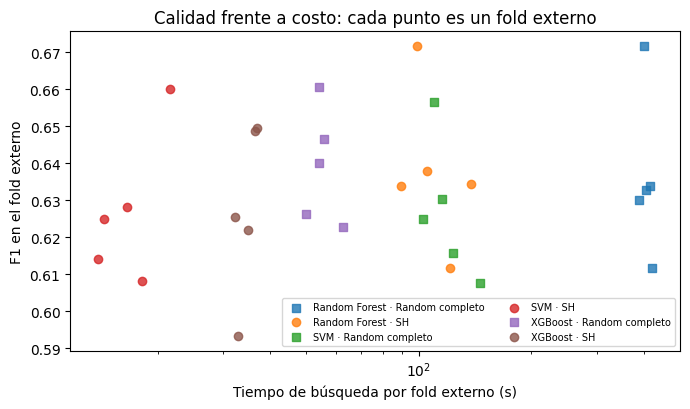

In [39]:
pares=MULTIFIDELIDAD.pivot_table(index=['model','outer_fold'],columns='method',values=['search_seconds','outer_f1','full_fidelity_fit_equivalents'])
MF_PARES=pd.DataFrame({
    'aceleración_tiempo':pares['search_seconds','random_completo']/pares['search_seconds','successive_halving'],
    'reducción_cómputo':pares['full_fidelity_fit_equivalents','random_completo']/pares['full_fidelity_fit_equivalents','successive_halving'],
    'delta_f1_externo':pares['outer_f1','successive_halving']-pares['outer_f1','random_completo']}).reset_index()
tabla(MF_PARES.groupby('model').agg(aceleracion_media=('aceleración_tiempo','mean'),reduccion_computo=('reducción_cómputo','mean'),
      delta_f1_medio=('delta_f1_externo','mean'),delta_f1_ds=('delta_f1_externo','std'),
      folds_sh_mejor=('delta_f1_externo',lambda d:int((d>0).sum()))).reset_index())
fig,ax=plt.subplots(figsize=(7,4.2))
for (model,method),g in MULTIFIDELIDAD.groupby(['model','method']):
    ax.scatter(g.search_seconds,g.outer_f1,marker='o' if method=='successive_halving' else 's',
               label=f"{NOMBRES[model]} · {'SH' if method=='successive_halving' else 'Random completo'}",alpha=.8)
ax.set(xlabel='Tiempo de búsqueda por fold externo (s)',ylabel='F1 en el fold externo',xscale='log',title='Calidad frente a costo: cada punto es un fold externo')
ax.legend(fontsize=7,ncol=2); plt.tight_layout(); plt.show(); plt.close(fig)

**Interpretación.** Cada punto de la figura es un fold externo. En Random Forest y SVM los círculos (SH) quedan a la izquierda de los cuadrados (búsqueda completa) sin bajar: misma calidad con una fracción del tiempo. En dos folds de Random Forest y uno de SVM ambos métodos eligieron exactamente el mismo candidato, lo que muestra que la eliminación temprana no se equivocó de ganador. XGBoost es el caso en que la multifidelidad no conviene: la ganancia de tiempo es pequeña y en cuatro de cinco folds SH eligió un candidato peor, con una pérdida media de 0.011 en F1.

La correlación de Spearman entre el F1 de los candidatos en una ronda y en la siguiente ayuda a entender por qué. Es baja en las tres familias (0.24 en Random Forest, 0.20 en SVM y 0.03 en XGBoost): a baja fidelidad el orden de los candidatos se parece poco al final. Que aun así SH funcione en Random Forest y SVM indica que la mayoría de los candidatos del espacio rinde parecido y lo importante es no quedarse con uno malo; en XGBoost, en cambio, la tasa de aprendizaje interactúa con el número de árboles (un modelo con tasa baja parece malo con 12 árboles y bueno con 324) y la fidelidad baja engaña justo en la dirección equivocada. Por eso la recomendación práctica es usar SH donde el recurso recortado sea el que domina el costo y no altere el orden de los candidatos (filas en SVM, árboles en Random Forest). En XGBoost el número de árboles se comporta más como un hiperparámetro ligado a la tasa de aprendizaje que como un simple presupuesto, y conviene buscarlo junto con ella.

### 2.6 Optimizaciones computacionales aplicadas y aceleración medida

La sección 2.3 dio las cotas teóricas; aquí se mide qué pasa al cambiar la implementación. Para cada familia se toma su configuración representativa y, en cada fold externo, los hiperparámetros que eligió su búsqueda en la validación anidada. El entrenamiento externo pasa por el mismo Pipeline de la sección 1 (reglas, escalado, codificación y SMOTE cuando corresponde) y sobre esos datos se entrena la versión **estándar**, que es exactamente la que se usó en las 112 configuraciones, y una o varias versiones **optimizadas**:

| Familia | Estándar | Alternativas medidas |
|---|---|---|
| KNN | búsqueda exhaustiva `brute` | KD-Tree, Ball Tree, vecinos aproximados con FAISS (grafo HNSW), `brute` con 4 hilos |
| GaussianNB | `fit` en memoria | `partial_fit` en 10 bloques (aprendizaje incremental) |
| Logística | `liblinear` | `saga` |
| Random Forest | `n_jobs=1` | 2, 4 y 8 hilos |
| XGBoost | `hist`, T fijo | método `exact`; early stopping con validación independiente frente a T=1000 sin parar |
| SVM | `SVC` RBF exacto | `LinearSVC`, SGD con pérdida hinge, aproximación de Nyström (300 componentes) + `LinearSVC` |

Para early stopping, el 20 % del entrenamiento externo se separa *antes* de SMOTE y funciona como validación: el modelo deja de añadir árboles cuando la log-loss en esa validación no mejora en 30 rondas. El fold externo nunca participa. Cada variante se entrena y predice cinco veces por fold y se reporta la mediana, para que una interrupción del sistema operativo no pase por aceleración. La memoria es el pico de RSS del proceso durante el ajuste (incluye lo que reservan las librerías en C), por encima del nivel previo; con modelos tan pequeños es una medida ruidosa y se lee solo en orden de magnitud. La inferencia es el tiempo de `predict` sobre el fold externo completo, unas 1.127 filas.

In [40]:
from complementos import optimizacion_computacional as oc

CARPETA_OC=COMPLEMENTARIOS/'optimizacion_computacional'
COMPARACIONES=pd.read_csv(CARPETA_OC/'comparaciones_por_fold.csv')
ESCALAMIENTO=pd.read_csv(CARPETA_OC/'escalamiento.csv')
PARALELO=pd.read_csv(CARPETA_OC/'paralelismo_cv.csv')
GPU=json.loads((CARPETA_OC/'gpu.json').read_text(encoding='utf-8'))
mostrar_codigo(oc.Medidor, oc.correr)

class Medidor:
    """Mide tiempo de pared y pico de RSS (memoria del proceso, incluye código C) de un bloque."""

    def __init__(self, intervalo=0.002):
        self.intervalo = intervalo

    def __enter__(self):
        self.proceso = psutil.Process()
        self.base = self.pico = self.proceso.memory_info().rss
        self.activo = True
        self.hilo = threading.Thread(target=self._muestrear, daemon=True)
        self.hilo.start()
        self.inicio = time.perf_counter()
        return self

    def _muestrear(self):
        while self.activo:
            self.pico = max(self.pico, self.proceso.memory_info().rss)
            time.sleep(self.intervalo)

    def __exit__(self, *exc):
        self.segundos = time.perf_counter() - self.inicio
        self.activo = False
        self.hilo.join()
        self.pico = max(self.pico, self.proceso.memory_info().rss)
        self.mib = (self.pico - self.base) / 2 ** 20


def correr(nombre, variante, fabrica, Z, yz, Ze, ye, fold, referencia=None, repeticiones=5):
    """Entrena y predice una variante; devuelve tiempos, memoria, métricas y acuerdo con la estándar.

    Los tiempos y la memoria son la mediana de ``repeticiones`` ajustes y predicciones
    independientes; la inferencia mide solo ``predict`` sobre el fold externo completo.
    """
    medidas = []
    for _ in range(repeticiones):
        modelo = fabrica()
        with Medidor() as entrenamiento:
            modelo.fit(Z, yz)
        with Medidor() as inferencia:
            etiquetas = modelo.predict(Ze)
        medidas.append((entrenamiento.segundos, inferencia.segundos, entrenamiento.mib, inferencia.mib))
    medidas = np.median(np.array(medidas), axis=0)
    score = puntuar(modelo, Ze)
    fila = {'model': nombre, 'variant': variante, 'outer_fold': fold,
            'train_seconds': medidas[0], 'predict_seconds': medidas[1],
            'train_rss_mib': medidas[2], 'predict_rss_mib': medidas[3], 'repetitions': repeticiones,
            'f1': f1_score(ye, etiquetas), 'auc': roc_auc_score(ye, score),
            'agreement_with_standard': float(np.mean(etiquetas == referencia)) if referencia is not None else 1.0}
    if hasattr(modelo, 'best_iteration'):
        fila['trees_used'] = int(modelo.best_iteration) + 1
    return fila, etiquetas

In [41]:
orden=list(dict.fromkeys(COMPARACIONES.variant))
OC_RESUMEN=COMPARACIONES.groupby(['model','variant'],sort=False).agg(
    entrenamiento_s=('train_seconds','mean'),inferencia_s=('predict_seconds','mean'),
    memoria_entrenamiento_mib=('train_rss_mib','mean'),f1=('f1','mean'),auc=('auc','mean'),
    acuerdo_con_estandar=('agreement_with_standard','mean')).reset_index()
estandar=OC_RESUMEN.groupby('model').first()
OC_RESUMEN['aceleración_entrenamiento']=OC_RESUMEN.model.map(estandar.entrenamiento_s)/OC_RESUMEN.entrenamiento_s
OC_RESUMEN['aceleración_inferencia']=OC_RESUMEN.model.map(estandar.inferencia_s)/OC_RESUMEN.inferencia_s
OC_RESUMEN['delta_f1']=OC_RESUMEN.f1-OC_RESUMEN.model.map(estandar.f1)
tabla(OC_RESUMEN)

model,variant,entrenamiento_s,inferencia_s,memoria_entrenamiento_mib,f1,auc,acuerdo_con_estandar,aceleración_entrenamiento,aceleración_inferencia,delta_f1
knn,brute (estándar),0.001276,0.146921,0.018750,0.612558,0.830711,1.000000,1.000000,1.000000,0.000000
knn,kd_tree,0.026437,0.171973,0.008594,0.612558,0.830723,1.000000,0.048285,0.854327,0.000000
knn,ball_tree,0.013240,0.165097,0.007031,0.612558,0.830755,1.000000,0.096409,0.889905,0.000000
knn,FAISS HNSW (aprox.),0.454603,0.107987,1.685938,0.611828,0.830514,0.998402,0.002808,1.360544,-0.000731
knn,"brute, n_jobs=4",0.001068,0.162470,0.057031,0.612558,0.830711,1.000000,1.195516,0.904296,0.000000
naive_bayes,fit (estándar),0.002379,0.000664,0.007812,0.619778,0.830094,1.000000,1.000000,1.000000,0.000000
naive_bayes,partial_fit (10 bloques),0.009141,0.000581,0.007812,0.619778,0.830079,1.000000,0.260230,1.142631,0.000000
logistic,liblinear (estándar),0.029391,0.000397,1.994531,0.633953,0.844075,1.000000,1.000000,1.000000,0.000000
logistic,saga,0.064748,0.000424,0.006250,0.633605,0.844041,0.999645,0.453929,0.935099,-0.000348
random_forest,n_jobs=1 (estándar),0.907939,0.024530,0.036719,0.638421,0.843835,1.000000,1.000000,1.000000,0.000000


**Interpretación.** Los tiempos son medias de cinco folds de la mediana de cinco repeticiones; `aceleración` es estándar dividido por variante, de modo que valores mayores que 1 significan más rápido.

- **SVM** es donde la optimización paga de verdad. `LinearSVC` entrena 36 veces más rápido y predice unas 900 veces más rápido que el SVC RBF, con un F1 apenas 0.0016 menor y un AUC incluso algo mayor (0.845 frente a 0.839). Nyström conserva el F1 (−0.0008) y acelera 23 veces la inferencia, aunque su entrenamiento ahorra poco. SGD es igual de rápido que `LinearSVC` pero pierde 0.039 de F1: con 50 épocas no termina de converger. Que un modelo lineal iguale al RBF dice algo de los datos: después del one-hot, la frontera entre clientes que se van y los que se quedan es casi lineal, y la flexibilidad del kernel no compra nada.
- **KNN** apenas cambia. Con 24 columnas, KD-Tree y Ball Tree ya no podan bien el espacio y predicen un 12–17 % *más lento* que la búsqueda exhaustiva, con predicciones idénticas. FAISS sí acelera la consulta (1.36×) y coincide con la búsqueda exacta en el 99.8 % de los clientes, pero construir el grafo cuesta 0.45 s, así que solo compensa si se predice muchas veces con el mismo índice.
- **XGBoost**: `hist` es 2.8 veces más rápido que `exact` y además da un F1 algo mayor. Early stopping es 3.4 veces más rápido que entrenar 1.000 árboles a ciegas y obtiene mejor F1 (0.625 frente a 0.602), pero no supera a la configuración de 100 árboles de la sección 1, que ya fue elegida por la búsqueda: pierde 0.013 de F1 porque se entrena con el 80 % de los datos y se detiene según log-loss, no según F1.
- **Random Forest** con 4 hilos entrena 2 veces más rápido sin cambiar una sola predicción; pasar a 8 hilos casi no agrega nada (2.1×). En la inferencia los hilos *empeoran* el tiempo (0.5×): predecir 1.127 filas tarda 25 ms y repartirlo entre hilos cuesta más que hacerlo.
- **GaussianNB y logística** ya son tan baratas (milisegundos) que sus alternativas no tienen margen. `partial_fit` llega al mismo modelo (mismas predicciones de clase, diferencias numéricas en la quinta cifra del AUC) y su ventaja no es la velocidad sino poder entrenar sin tener todos los datos en memoria; `saga` converge al mismo resultado, pero es más lento que `liblinear` con estas dimensiones.

#### Escalamiento empírico frente a la complejidad teórica

Con un solo tamaño de datos no se puede comprobar un orden de complejidad. Para eso se entrenó cada modelo con $n \in \{800, 1600, 3200, 6400\}$ filas (submuestras del entrenamiento externo ya balanceado) y, por separado, con $p \in \{24, 48, 96, 192\}$ columnas, añadiendo ruido gaussiano a las 24 reales sobre $n = 3200$. En escala log-log, la pendiente de la recta es el exponente empírico: si el tiempo crece como $n^k$, la pendiente estima $k$. Cada punto es la mediana de tres repeticiones; en KNN se mide la predicción de 1.000 consultas, que es donde está su costo.

model,exponente_n,exponente_p,teórico_n
knn brute (predicción),0.395116,0.961643,1 (por consulta)
knn kd_tree (predicción),-0.783404,1.005313,≈log n en baja dimensión
logistic liblinear,1.005063,1.124015,≈1 por iteración
naive_bayes,0.506673,0.979811,1
random_forest (100 árboles),0.175006,1.269145,≈1 (n log n)
svm LinearSVC,1.177636,1.279350,≈1
svm rbf,2.001003,0.750658,2 a 3
xgboost exact,0.990295,1.508920,"≈1 (n log n, ordenamiento)"
xgboost hist,0.192502,1.269741,≈1


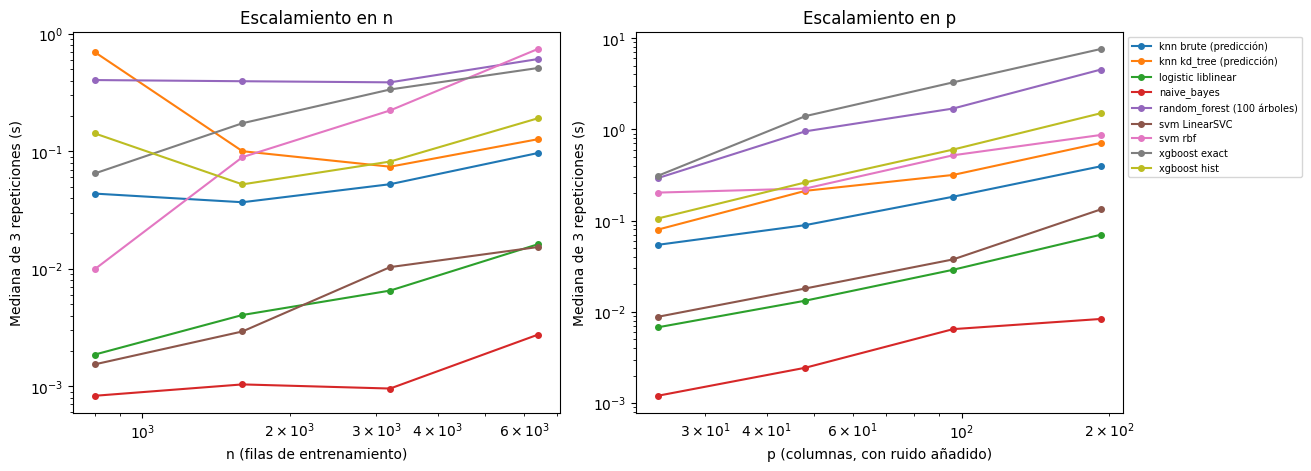

In [42]:
def exponente(g):
    """Pendiente de log(tiempo) frente a log(tamaño): exponente empírico de escalamiento."""
    return np.polyfit(np.log(g.value),np.log(g.median_seconds),1)[0]

EXPONENTES=ESCALAMIENTO.groupby(['model','axis']).apply(exponente,include_groups=False).unstack().rename(columns={'n':'exponente_n','p':'exponente_p'}).reset_index()
EXPONENTES['teórico_n']=EXPONENTES.model.map({'knn brute (predicción)':'1 (por consulta)','knn kd_tree (predicción)':'≈log n en baja dimensión',
    'naive_bayes':'1','logistic liblinear':'≈1 por iteración','random_forest (100 árboles)':'≈1 (n log n)',
    'xgboost hist':'≈1','xgboost exact':'≈1 (n log n, ordenamiento)','svm rbf':'2 a 3','svm LinearSVC':'≈1'})
tabla(EXPONENTES,decimales=2)
fig,axes=plt.subplots(1,2,figsize=(13,4.6),layout='constrained')
for ax,eje in zip(axes,['n','p']):
    for model,g in ESCALAMIENTO[ESCALAMIENTO.axis==eje].groupby('model'):
        ax.plot(g.value,g.median_seconds,'o-',label=model,markersize=4)
    ax.set(xscale='log',yscale='log',xlabel='n (filas de entrenamiento)' if eje=='n' else 'p (columnas, con ruido añadido)',
           ylabel='Mediana de 3 repeticiones (s)',title=f'Escalamiento en {eje}')
axes[1].legend(fontsize=7,loc='upper left',bbox_to_anchor=(1,1)); plt.show(); plt.close(fig)

**Interpretación.** Los dos casos más informativos coinciden con la teoría. SVM RBF tiene exponente 2.0 en $n$: duplicar los datos cuadruplica el tiempo, lo esperado para un solver que trabaja sobre la matriz de kernel y la razón de que en la sección 2.5 recortar filas fuera tan eficaz. XGBoost `exact` (0.99) y la logística (1.01) crecen linealmente, como predice su costo por barrido de los datos.

Los exponentes menores que 1 no contradicen la teoría, la esconden: GaussianNB, Random Forest, XGBoost `hist` y KNN tardan milisegundos con estos tamaños y su tiempo lo dominan costos fijos (validar entradas, crear estructuras, lanzar hilos) que no dependen de $n$. Con 6.400 filas el término lineal todavía no se ve. El exponente negativo de KD-Tree se debe a su primera medición ($n=800$), mucho más lenta que las demás por costos de arranque; sin ese punto la curva es casi plana, lo esperable para una búsqueda que, con 24 dimensiones, ya no poda bien. En $p$, casi todos los modelos crecen de forma aproximadamente lineal (exponentes entre 0.96 y 1.5), como indican sus cotas $O(np)$. El RBF crece menos (0.75) porque su costo lo dominan las iteraciones del solver sobre $n$ y no el producto escalar en $p$. El crecimiento lineal en $p$ de KD-Tree confirma que con más dimensiones el índice deja de podar y la búsqueda se vuelve, en la práctica, exhaustiva.

#### Paralelización entre folds y backends de joblib

El paralelismo que más importa en este proyecto no es dentro de un modelo sino entre ajustes: cada búsqueda repite el mismo Pipeline sobre tres folds internos, y cada configuración sobre cinco externos. Para medirlo se ejecutó la validación cruzada completa de Random Forest–SMOTE (5 folds, Pipeline completo) con 1, 2 y 4 trabajadores, usando `loky` (procesos separados) y `threading` (hilos del mismo proceso). En la sección 2.4 esto no se pudo medir porque la política de memoria forzó un solo trabajador; aquí se ejecutó sin esa restricción.

backend,n_jobs,median_seconds,min_seconds,speedup,efficiency,f1_mean,same_f1_as_serial
loky,1,3.781562,3.443308,1.000000,1.000000,0.635083,True
loky,2,2.727249,2.535623,1.386585,0.693292,0.635083,True
loky,4,2.104894,2.033409,1.796557,0.449139,0.635083,True
threading,2,2.347572,2.274531,1.610840,0.805420,0.635083,True
threading,4,2.052141,1.889905,1.842740,0.460685,0.635083,True


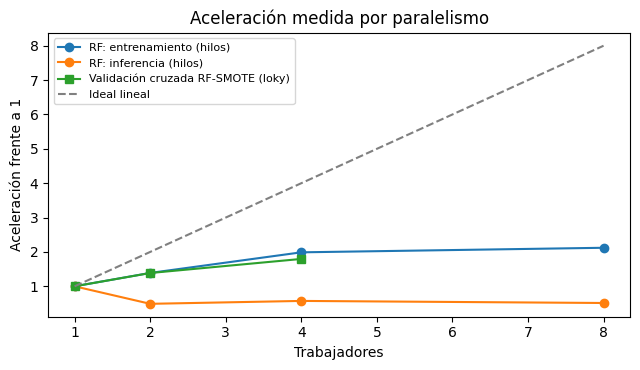

In [43]:
tabla(PARALELO[['backend','n_jobs','median_seconds','min_seconds','speedup','efficiency','f1_mean','same_f1_as_serial']])
rf=OC_RESUMEN[OC_RESUMEN.model=='random_forest']
fig,ax=plt.subplots(figsize=(6.5,3.8))
jobs=[1,2,4,8]
ax.plot(jobs,rf.aceleración_entrenamiento,'o-',label='RF: entrenamiento (hilos)')
ax.plot(jobs,rf.aceleración_inferencia,'o-',label='RF: inferencia (hilos)')
loky=PARALELO[PARALELO.backend=='loky']; ax.plot(loky.n_jobs,loky.speedup,'s-',label='Validación cruzada RF-SMOTE (loky)')
ax.plot(jobs,jobs,'--',color='gray',label='Ideal lineal')
ax.set(xlabel='Trabajadores',ylabel='Aceleración frente a 1',title='Aceleración medida por paralelismo'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show(); plt.close(fig)

**Interpretación.** Con cuatro trabajadores la validación cruzada termina 1.8 veces más rápido y los F1 son idénticos a los de la ejecución serial, así que paralelizar no cambia los resultados. La eficiencia cae del 69 % con dos procesos al 45 % con cuatro: cada fold dura menos de un segundo, y crear procesos, copiar los datos y recoger resultados se come buena parte de la ganancia. `threading` rinde un poco mejor que `loky` con dos trabajadores (1.61× frente a 1.39×) porque no copia los datos, y funciona aquí porque el trabajo pesado de scikit-learn ocurre en código C que libera el GIL. Con cuatro trabajadores ambos se igualan. La figura junta las tres mediciones: la curva de entrenamiento de Random Forest se aplana a partir de 4 hilos y su inferencia queda por debajo de 1. En este equipo, con 14 núcleos y 8 GB de RAM, el límite práctico lo puso la memoria y no el número de núcleos, y por eso las 112 configuraciones se entrenaron con un solo nivel de paralelismo.

**GPU.** XGBoost con `device='cuda'` no pudo usar GPU: el equipo no tiene tarjeta NVIDIA y la versión instalada de XGBoost no está compilada con CUDA, así que la librería avisa y vuelve a CPU. No se reporta un factor de aceleración por GPU porque no hay forma honesta de medirlo en este hardware.

#### Perfilamiento: ¿dónde se va el tiempo?

Antes de optimizar conviene saber qué domina. `cProfile` registró el ajuste completo del Pipeline de SVM–SMOTE (reglas, escalado, codificación, SMOTE y SVC) y la predicción del Pipeline de KNN–SMOTE, los dos modelos más costosos en entrenamiento e inferencia, respectivamente.

In [44]:
for nombre, titulo in [('svm__smote__genetic_fit', 'Ajuste completo del Pipeline SVM–SMOTE'),
                       ('knn__smote__bayesian_tpe_predict', 'Predicción del Pipeline KNN–SMOTE')]:
    display(Markdown(f'**{titulo}**'))
    tabla_perfil((CARPETA_OC/f'perfil_{nombre}.txt').read_text(encoding='utf-8'))
print('GPU:',GPU['estado'],'|',' / '.join(a.split('WARNING: ')[-1].split(': ',1)[-1] for a in GPU['avisos']))

**Ajuste completo del Pipeline SVM–SMOTE**

ncalls,tottime,percall (tottime),cumtime,percall (cumtime),filename:lineno(function)
7/1,0.000,0.000,1.201,1.201,sklearn/base.py:1372(wrapper)
1,0.000,0.000,1.201,1.201,imblearn/pipeline.py:455(fit)
1,0.000,0.000,1.139,1.139,A08-adaptadores:72(fit)
1,0.157,0.157,1.137,1.137,sklearn/svm/_base.py:153(fit)
1,0.978,0.978,0.978,0.978,sklearn/svm/_base.py:312(_dense_fit)
1,0.000,0.000,0.062,0.062,imblearn/pipeline.py:398(_fit)
3,0.000,0.000,0.061,0.020,joblib/memory.py:325(__call__)
2,0.000,0.000,0.052,0.026,imblearn/pipeline.py:1370(_fit_transform_one)
6/2,0.000,0.000,0.052,0.026,sklearn/utils/_set_output.py:317(wrapped)
3,0.000,0.000,0.049,0.016,sklearn/base.py:863(fit_transform)


**Predicción del Pipeline KNN–SMOTE**

ncalls,tottime,percall (tottime),cumtime,percall (cumtime),filename:lineno(function)
1,0.000,0.000,0.164,0.164,imblearn/pipeline.py:605(predict)
1,0.000,0.000,0.141,0.141,A08-adaptadores:96(predict)
1,0.000,0.000,0.140,0.140,A08-adaptadores:53(predict)
1,0.001,0.001,0.140,0.140,A08-adaptadores:34(predict_proba)
1,0.000,0.000,0.138,0.138,sklearn/neighbors/_base.py:763(kneighbors)
1,0.138,0.138,0.138,0.138,sklearn/metrics/_pairwise_distances_reduction/_dispatcher.py:188(compute)
3/1,0.000,0.000,0.015,0.015,sklearn/utils/_set_output.py:317(wrapped)
1,0.000,0.000,0.015,0.015,sklearn/compose/_column_transformer.py:1033(transform)
1,0.000,0.000,0.015,0.015,sklearn/compose/_column_transformer.py:838(_call_func_on_transformers)
1,0.000,0.000,0.013,0.013,sklearn/utils/parallel.py:54(__call__)


GPU: sin error | No visible GPU is found, setting device to CPU. / XGBoost is not compiled with CUDA support.


**Interpretación.** En SVM, el 81 % del ajuste (0.98 de 1.20 s) ocurre dentro de `_dense_fit`, el solver de libsvm; preprocesar y aplicar SMOTE suma 0.06 s. En KNN, el 84 % de la predicción (0.138 de 0.164 s) es el cálculo de distancias por pares. Los dos perfiles dicen lo mismo: el cuello de botella es el núcleo del algoritmo y no el Pipeline, así que optimizar el preprocesamiento no tendría efecto visible. Eso explica también qué alternativas funcionaron: `LinearSVC` sustituye justo el solver que domina el costo de SVM, mientras que en KNN ni los índices ni los hilos reducen de forma apreciable el cálculo de distancias con 24 dimensiones y 1.127 consultas.

#### Tabla comparativa: modelo estándar frente a optimizado

La tabla reúne, para cada familia, la complejidad teórica de cada variante, los tiempos de entrenamiento e inferencia, la memoria y el cambio en F1 respecto de la versión usada en las 112 configuraciones.

In [45]:
COMPLEJIDAD_VARIANTES={
    ('knn','brute (estándar)'):'Consulta O(n·p)', ('knn','kd_tree'):'Consulta O(log n) en baja p; se degrada a O(n·p) si p es alta',
    ('knn','ball_tree'):'Consulta O(log n) idealmente; poda por bolas', ('knn','FAISS HNSW (aprox.)'):'Consulta ≈O(log n), aproximada',
    ('knn','brute, n_jobs=4'):'O(n·p)/4 en tiempo de pared',
    ('naive_bayes','fit (estándar)'):'O(n·p), todo en memoria', ('naive_bayes','partial_fit (10 bloques)'):'O(n·p), memoria O(bloque·p)',
    ('logistic','liblinear (estándar)'):'O(I·n·p), coordenadas', ('logistic','saga'):'O(n·p) por época, estocástico',
    ('random_forest','n_jobs=1 (estándar)'):'O(T·m·n log n)', ('random_forest','n_jobs=2'):'O(T·m·n log n)/2',
    ('random_forest','n_jobs=4'):'O(T·m·n log n)/4', ('random_forest','n_jobs=8'):'O(T·m·n log n)/8',
    ('xgboost','hist (estándar)'):'O(T·n·p) con B bins', ('xgboost','exact'):'O(T·p·n log n) con ordenamiento',
    ('xgboost','hist, T=1000 sin early stopping'):'O(T·n·p) con T=1000',
    ('xgboost','hist + early stopping'):'O(T*·n·p), T* ≤ T elegido en validación',
    ('svm','SVC RBF (estándar)'):'O(n²·p) a O(n³·p)', ('svm','LinearSVC'):'O(n·p) por iteración',
    ('svm','SGD (hinge)'):'O(n·p) por época', ('svm','Nyström(300) + LinearSVC'):'O(n·m·p + n·m²), m=300'}
FINAL=OC_RESUMEN.copy()
FINAL.insert(2,'complejidad',[COMPLEJIDAD_VARIANTES[(m,v)] for m,v in zip(FINAL.model,FINAL.variant)])
tabla(FINAL[['model','variant','complejidad','entrenamiento_s','inferencia_s','memoria_entrenamiento_mib','aceleración_entrenamiento','aceleración_inferencia','delta_f1']],decimales=3)

model,variant,complejidad,entrenamiento_s,inferencia_s,memoria_entrenamiento_mib,aceleración_entrenamiento,aceleración_inferencia,delta_f1
knn,brute (estándar),Consulta O(n·p),0.001276,0.146921,0.018750,1.000000,1.000000,0.000000
knn,kd_tree,Consulta O(log n) en baja p; se degrada a O(n·p) si p es alta,0.026437,0.171973,0.008594,0.048285,0.854327,0.000000
knn,ball_tree,Consulta O(log n) idealmente; poda por bolas,0.013240,0.165097,0.007031,0.096409,0.889905,0.000000
knn,FAISS HNSW (aprox.),"Consulta ≈O(log n), aproximada",0.454603,0.107987,1.685938,0.002808,1.360544,-0.000731
knn,"brute, n_jobs=4",O(n·p)/4 en tiempo de pared,0.001068,0.162470,0.057031,1.195516,0.904296,0.000000
naive_bayes,fit (estándar),"O(n·p), todo en memoria",0.002379,0.000664,0.007812,1.000000,1.000000,0.000000
naive_bayes,partial_fit (10 bloques),"O(n·p), memoria O(bloque·p)",0.009141,0.000581,0.007812,0.260230,1.142631,0.000000
logistic,liblinear (estándar),"O(I·n·p), coordenadas",0.029391,0.000397,1.994531,1.000000,1.000000,0.000000
logistic,saga,"O(n·p) por época, estocástico",0.064748,0.000424,0.006250,0.453929,0.935099,-0.000348
random_forest,n_jobs=1 (estándar),O(T·m·n log n),0.907939,0.024530,0.036719,1.000000,1.000000,0.000000


**Interpretación.** El balance favorece claramente a tres cambios: `LinearSVC` (o Nyström si se quiere conservar algo de no linealidad) en lugar del SVC RBF, `hist` en lugar de `exact` en XGBoost y paralelizar los ajustes de Random Forest y la validación cruzada. Los tres reducen el tiempo sin pérdida de F1 mayor que 0.002. Los índices de KNN, `saga` y `partial_fit` no aceleran nada con un conjunto de este tamaño, aunque `partial_fit` sería la opción natural si los datos no cupieran en memoria. Early stopping ahorra frente a entrenar árboles de más, pero no frente a una búsqueda que ya eligió bien su número de árboles. Ninguna de estas variantes reemplaza a posteriori los resultados de la sección 1: miden cuánto se habría ganado y quedan como recomendación para el modelo propuesto.

## 3. Resultados finales, comparación estadística e interpretabilidad

### 3.1 Comparación jerárquica con alcance exploratorio

Se conserva la secuencia Friedman → Nemenyi → Diagrama de Diferencia Crítica → comparaciones dirigidas de AUC → tamaños del efecto. La matriz de entrada tiene cinco filas (folds externos de la realización 0) y 112 columnas (configuraciones), evaluadas sobre las mismas particiones.

Los entrenamientos de folds externos se solapan y proceden de un solo dataset. Por tanto, no son bloques de datasets independientes. Las realizaciones algorítmicas tampoco añaden independencia. Friedman, Nemenyi y CD se interpretan exclusivamente de forma exploratoria, con limitaciones adicionales de aproximación asintótica al disponer de cinco bloques. Se mantiene el procedimiento requerido sin convertir sus p-valores en confirmación de superioridad.

Friedman utiliza rangos por fold y promedia empates. Se reporta W de Kendall como concordancia descriptiva del orden relativo, no como ganancia de F1 ni efecto de una intervención.

Un p-valor pequeño solo dice que una diferencia es difícil de atribuir al azar, no que importe. Por eso cada comparación de esta sección va acompañada de un tamaño del efecto: el **δ de Cliff**, que cuenta en qué fracción de los pares un valor de A supera a uno de B menos la fracción en que ocurre lo contrario ($\delta\in[-1,1]$), y que es coherente con el uso de rangos de Friedman y Nemenyi. Se interpreta con los umbrales de Romano et al. (2006): despreciable si $|\delta|<0.147$, pequeño hasta 0.33, mediano hasta 0.474 y grande por encima. Como los folds son los mismos para todas las configuraciones, se reporta también un efecto pareado: la $d_z$ de Cohen (media de las diferencias por fold dividida por su desviación) y la correlación biserial de rangos de Wilcoxon. Se informan todos los efectos, también los que no favorecen a ningún modelo.

In [46]:
ESTADISTICA=ANALISIS/'estadistica'
MATRIZ=PRINCIPAL.pivot(index='outer_fold',columns='experiment_id',values='f1_positive').sort_index(axis=1)
RANGOS=MATRIZ.rank(axis=1,ascending=False,method='average')
RANGOS_MEDIOS=RANGOS.mean().sort_values(kind='stable')
stat,p=friedmanchisquare(*(MATRIZ[col].to_numpy() for col in MATRIZ))
n,k=MATRIZ.shape
friedman={'statistic':float(stat),'df':k-1,'p_exploratory':float(p),'blocks':n,'treatments':k,'kendall_W':float(stat/(n*(k-1)))}
original=json.loads((ESTADISTICA/'friedman.json').read_text(encoding='utf-8'))
np.testing.assert_allclose(stat,original['statistic'],rtol=1e-12)
tabla(pd.DataFrame([friedman]),decimales=8)

statistic,df,p_exploratory,blocks,treatments,kendall_W
422.285824,111,7.717e-38,5,112,0.760875


**Interpretación.** Friedman produjo χ²=422,2858, gl=111 y p exploratorio=7,72×10⁻³⁸; W=0,7609 indica concordancia del orden bajo este resumen. El valor nominal activa el post-hoc dentro de la secuencia exploratoria. La dependencia entre folds impide tratarlo como rechazo confirmatorio obtenido de 112 métodos sobre datasets independientes.

In [47]:
tabla(RANGOS_MEDIOS.rename('mean_rank').rename_axis('experiment_id').reset_index().head(12))

experiment_id,mean_rank
xgboost__smote__random,15.000000
logistic__smote__grid,15.600000
random_forest__balanced__bayesian_tpe,16.100000
random_forest__balanced__genetic,16.100000
random_forest__balanced__grid,16.100000
random_forest__balanced__random,16.100000
random_forest__smote__bayesian_tpe,16.100000
random_forest__smote__genetic,16.100000
random_forest__smote__grid,16.100000
random_forest__smote__random,16.100000


**Interpretación.** XGBoost–SMOTE–Random tiene el menor rango medio (15,0), seguido de Logística–SMOTE–Grid (15,6). Random Forest–SMOTE alcanza el mayor F1 medio, pero su rango medio es 16,1. No hay contradicción: promediar magnitudes y promediar posiciones responde a resúmenes diferentes. Esta tabla conserva evidencia descriptiva aun cuando la inferencia confirmatoria no es justificable.

#### Nemenyi y diferencia crítica

Nemenyi compara diferencias absolutas entre rangos medios usando el rango studentizado para 112 tratamientos y cinco bloques. Su referencia ya considera comparaciones simultáneas; no se añade Holm a estos mismos p-valores. Se conserva la formulación clásica sin corrección adicional de empates, contrastada numéricamente con la implementación de referencia.

La diferencia crítica exploratoria fue 89,3721. Entre 6.216 pares, 31 quedaron bajo el umbral nominal 0,05. Estos pares no son descubrimientos confirmatorios. En el diagrama, las barras conectan grupos de ausencia de rechazo bajo esa aproximación, no grupos de equivalencia práctica.

In [48]:
def nemenyi(rangos):
    """P-valores conjuntos de Nemenyi; interpretación exclusivamente exploratoria."""
    n,k=rangos.shape; means=rangos.mean().to_numpy()
    standard=np.sqrt(k*(k+1)/(6*n))
    q=np.abs(means[:,None]-means[None,:])/standard*np.sqrt(2)
    p=studentized_range.sf(q,k,np.inf); np.fill_diagonal(p,1)
    return pd.DataFrame(p,index=rangos.columns,columns=rangos.columns)

# La matriz conjunta está guardada; los rangos se reconstruyeron arriba.
NEMENYI=leer_tabla('estadistica/nemenyi_p_exploratorios.csv').set_index('Unnamed: 0')
CD=float(studentized_range.ppf(.95,k,np.inf)/np.sqrt(2)*np.sqrt(k*(k+1)/(6*n)))
np.testing.assert_allclose(CD,json.loads((ESTADISTICA/'nemenyi_estado.json').read_text(encoding='utf-8'))['critical_difference'])

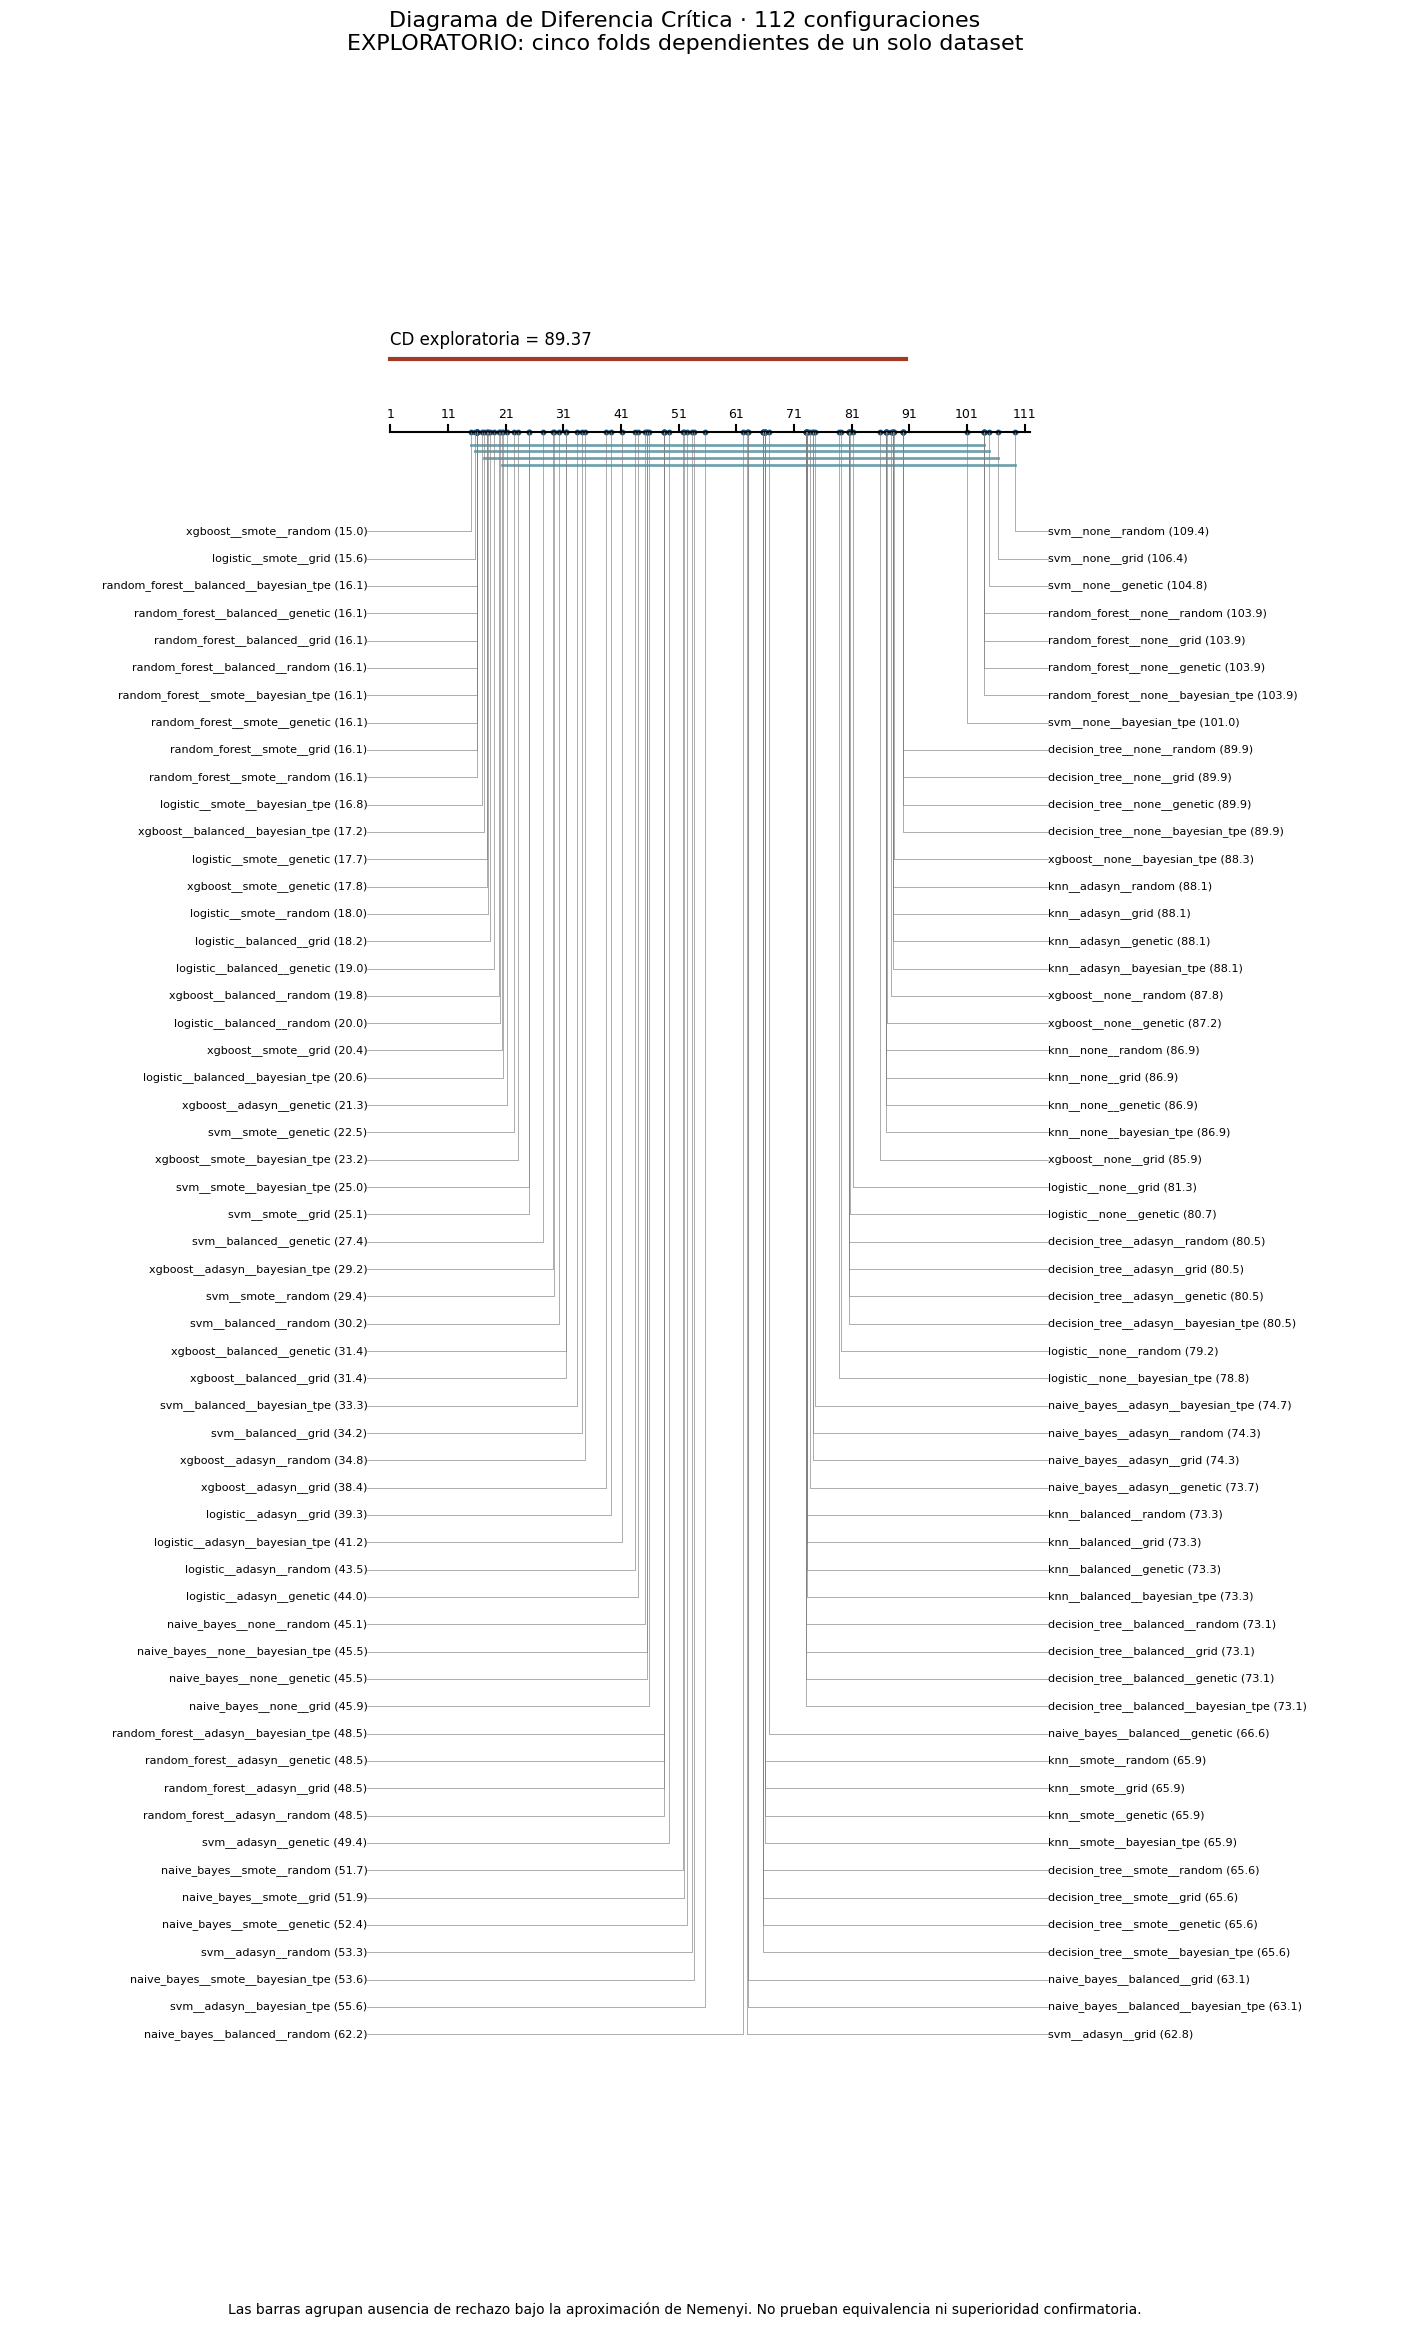

In [49]:
names=RANGOS_MEDIOS.index.tolist(); ranks=RANGOS_MEDIOS.to_numpy(); cd=CD
# Ventanas maximales de rangos cuyo diámetro no supera CD. Cada par dentro
# de una barra tiene p>=.05; pertenecer a una barra no acredita equivalencia.
groups=[]
for i in range(k):
    j=int(np.searchsorted(ranks,ranks[i]+cd,side='right')-1)
    if j>i and not any(a<=i and b>=j for a,b in groups): groups.append((i,j))
groups=[(a,b) for a,b in groups if not any(c<=a and d>=b and (c,d)!=(a,b) for c,d in groups)]
fig,ax=plt.subplots(figsize=(18,24))
ax.plot([1,k],[0,0],color='black')
for tick in range(1,k+1,10):
    ax.plot([tick,tick],[0,.2],color='black'); ax.text(tick,.4,str(tick),ha='center',fontsize=9)
ax.plot([1,1+cd],[2,2],lw=3,color='#a13b26'); ax.text(1,2.4,f'CD exploratoria = {cd:.2f}',fontsize=12)
for j,(a,b) in enumerate(groups): ax.plot([ranks[a],ranks[b]],[-.35-j*.18]*2,lw=2,color='#387b8d',alpha=.7)
offset=2+len(groups)*.18
half=(k+1)//2
for i,(name,rank) in enumerate(zip(names,ranks)):
    left=i<half; row=i if left else k-1-i; y=-offset-row*.75
    end=-3 if left else k+3
    ax.plot([rank,rank,end],[0,y,y],lw=.45,color='gray')
    ax.scatter([rank],[0],s=10,color='#1c4f74')
    ax.text(end,y,f'{name} ({rank:.1f})',ha='right' if left else 'left',va='center',fontsize=8)
ax.set(xlim=(-65,k+65),ylim=(-offset-half*.75-1,5)); ax.axis('off')
fig.suptitle('Diagrama de Diferencia Crítica · 112 configuraciones\nEXPLORATORIO: cinco folds dependientes de un solo dataset',fontsize=16)
fig.text(.5,.02,'Las barras agrupan ausencia de rechazo bajo la aproximación de Nemenyi. No prueban equivalencia ni superioridad confirmatoria.',ha='center',fontsize=10)
plt.show(); plt.close(fig)

**Interpretación.** La CD es grande respecto del rango posible, por lo que solo separaciones extremas aparecen bajo el umbral nominal. Las mejores configuraciones quedan conectadas con muchas alternativas. Las barras no prueban igualdad y los 31 pares nominales no justifican afirmaciones confirmatorias con folds dependientes. Se conserva el universo completo de 112 configuraciones en el diagrama.

In [50]:
def cliff_delta(a, b):
    """Delta de Cliff: P(A>B) - P(A<B) sobre todos los pares; no supone normalidad."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float(np.sign(a[:, None] - b[None, :]).mean())

def magnitud_cliff(d):
    """Umbrales de Romano et al. (2006): 0.147, 0.33 y 0.474."""
    d = abs(d)
    return 'despreciable' if d < .147 else 'pequeño' if d < .33 else 'mediano' if d < .474 else 'grande'

def efecto_pareado(a, b):
    """d_z de Cohen y correlación biserial de rangos de Wilcoxon para diferencias emparejadas."""
    d = np.asarray(a, float) - np.asarray(b, float)
    dz = d.mean()/d.std(ddof=1) if d.std(ddof=1) > 0 else np.nan
    nz = d[d != 0]
    if len(nz) == 0:
        return dz, 0.0
    rangos = pd.Series(np.abs(nz)).rank().to_numpy()
    return float(dz), float((rangos[nz > 0].sum() - rangos[nz < 0].sum())/rangos.sum())

finalistas=json.loads((ESTADISTICA/'fase6_control.json').read_text(encoding='utf-8'))['finalists']
efectos=[]
for a,b in combinations([r['experiment_id'] for r in finalistas],2):
    delta=MATRIZ[a]-MATRIZ[b]
    fa=UNIDADES[UNIDADES.experiment_id==a].sort_values(['replicate','outer_fold']).f1_positive.to_numpy()
    fb=UNIDADES[UNIDADES.experiment_id==b].sort_values(['replicate','outer_fold']).f1_positive.to_numpy()
    dz,rb=efecto_pareado(fa,fb)
    efectos.append({'a':a,'b':b,'mean_delta_f1':delta.mean(),'sd_delta_f1':delta.std(ddof=1),
                    'folds_a_higher':int((delta>0).sum()),'cliff_5_folds':cliff_delta(MATRIZ[a],MATRIZ[b]),
                    'cliff_15_unidades':cliff_delta(fa,fb),'magnitud':magnitud_cliff(cliff_delta(fa,fb)),
                    'd_z_15':dz,'rank_biserial_15':rb})
tabla(pd.DataFrame(efectos))

a,b,mean_delta_f1,sd_delta_f1,folds_a_higher,cliff_5_folds,cliff_15_unidades,magnitud,d_z_15,rank_biserial_15
random_forest__smote__bayesian_tpe,xgboost__smote__random,0.000431,0.011252,2,-0.120000,-0.057778,despreciable,0.052423,0.100000
random_forest__smote__bayesian_tpe,logistic__smote__grid,0.004467,0.015267,3,0.120000,0.102222,despreciable,0.305408,0.366667
xgboost__smote__random,logistic__smote__grid,0.004037,0.013711,2,0.040000,0.093333,despreciable,0.231756,0.100000


**Interpretación.** Las diferencias de F1 se calculan emparejando folds, no tratando los resultados como muestras independientes. Entre Random Forest–SMOTE y XGBoost–SMOTE–Random la diferencia media es de 0.0005 y el δ de Cliff sobre las 15 unidades (3 semillas × 5 folds) es −0.06: despreciable y, además, con signo contrario al de la media. Frente a la logística, ambos ensambles tienen δ ≈ 0.10 y $d_z$ entre 0.23 y 0.31, también por debajo del umbral de un efecto pequeño. Dicho de otra forma: si se toma un fold y una semilla al azar de cada modelo, casi da igual cuál de los tres finalistas se elija. Con cinco folds, el δ calculado solo sobre la realización principal salta en pasos de 0.04, así que el de 15 unidades es la lectura más estable.

#### Tamaño del efecto en el resto de comparaciones

Los finalistas no son la única comparación del capítulo. Las tres tablas siguientes ponen magnitud a lo que antes se reportaba solo como diferencia o como p-valor: los 31 pares que Nemenyi marcó como nominalmente distintos, el efecto de cada técnica de balanceo dentro de su familia y la ventaja de los optimizadores frente a Grid a igual presupuesto.

In [51]:
pares_nominales=[(a,b) for a,b in combinations(NEMENYI.columns,2) if NEMENYI.loc[a,b]<.05]
EF_NEM=pd.DataFrame([{'a':a,'b':b,'p_nemenyi':NEMENYI.loc[a,b],'delta_f1_medio':MATRIZ[a].mean()-MATRIZ[b].mean(),
                      'cliff':cliff_delta(MATRIZ[a],MATRIZ[b])} for a,b in pares_nominales])
EF_NEM['magnitud']=EF_NEM.cliff.map(magnitud_cliff)
tabla(EF_NEM.groupby('magnitud').agg(pares=('cliff','size'),cliff_min=('cliff','min'),cliff_max=('cliff','max'),
      delta_f1_min=('delta_f1_medio','min'),delta_f1_max=('delta_f1_medio','max')).reset_index())

magnitud,pares,cliff_min,cliff_max,delta_f1_min,delta_f1_max
grande,31,1.000000,1.000000,0.062890,0.075585


**Interpretación.** Los 31 pares nominalmente significativos tienen δ de Cliff igual a 1: en los cinco folds, la configuración de mejor rango supera a la otra sin excepción. Todos enfrentan a una configuración con balanceo de Random Forest, XGBoost o logística con una SVM sin balanceo, y la diferencia de F1 va de 0.063 a 0.076. Donde Nemenyi encuentra algo, el efecto no es sutil: son las distancias más extremas del universo de 112 configuraciones. La otra cara es que, con 112 tratamientos y 5 bloques, la prueba es tan conservadora que solo detecta efectos de ese tamaño.

model,ADASYN,Ponderación,SMOTE
knn,0.040000,0.440000,0.680000
naive_bayes,-0.340000,-0.300000,-0.070000
logistic,0.860000,0.900000,0.990000
decision_tree,0.280000,0.440000,0.360000
random_forest,1.000000,1.000000,1.000000
xgboost,0.910000,0.890000,0.935000
svm,0.895000,0.920000,0.955000


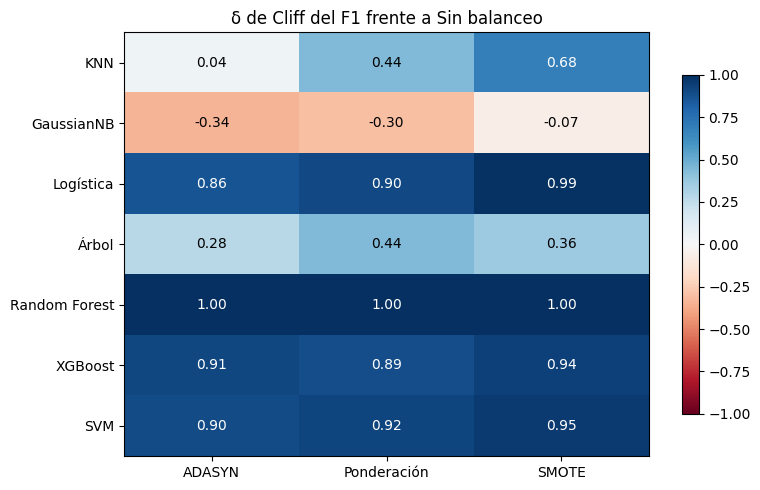

In [52]:
filas=[]
for model in MODELOS:
    base=PRINCIPAL[(PRINCIPAL.model==model)&(PRINCIPAL.balance=='none')].sort_values(['optimizer','outer_fold'])
    for balance in ['smote','adasyn','balanced']:
        g=PRINCIPAL[(PRINCIPAL.model==model)&(PRINCIPAL.balance==balance)].sort_values(['optimizer','outer_fold'])
        dz,rb=efecto_pareado(g.f1_positive,base.f1_positive)
        filas.append({'model':model,'balance':balance,'delta_f1':g.f1_positive.mean()-base.f1_positive.mean(),
                      'cliff':cliff_delta(g.f1_positive,base.f1_positive),'d_z':dz,'rank_biserial':rb})
EF_BAL=pd.DataFrame(filas); EF_BAL['magnitud']=EF_BAL.cliff.map(magnitud_cliff)
tabla(EF_BAL.pivot(index='model',columns='balance',values='cliff').loc[MODELOS].rename(columns=BALANCEOS).reset_index(),decimales=3)
fig,ax=plt.subplots(figsize=(8,5))
mapa=EF_BAL.pivot(index='model',columns='balance',values='cliff').loc[MODELOS]
im=ax.imshow(mapa,cmap='RdBu',vmin=-1,vmax=1,aspect='auto')
ax.set(xticks=range(3),xticklabels=[BALANCEOS[c] for c in mapa.columns],yticks=range(len(mapa)),yticklabels=[NOMBRES[m] for m in mapa.index],
       title='δ de Cliff del F1 frente a Sin balanceo')
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]): ax.text(j,i,f'{mapa.iloc[i,j]:.2f}',ha='center',va='center',fontsize=10,
                                           color='white' if abs(mapa.iloc[i,j])>.6 else 'black')
ax.tick_params(axis='x',labelsize=10)
fig.colorbar(im,ax=ax,shrink=.8); plt.tight_layout(); plt.show(); plt.close(fig)

**Interpretación.** Cada celda compara las 20 unidades de una técnica (4 optimizadores × 5 folds) con las 20 sin balanceo de la misma familia. El balanceo tiene efecto grande en Random Forest, XGBoost, SVM y logística con las tres técnicas (δ entre 0.86 y 1.0, $d_z$ entre 1.2 y 5.0): en esas familias corregir el desbalance no es un ajuste fino, cambia el resultado. En KNN solo SMOTE alcanza un efecto grande (δ = 0.68) y ADASYN es despreciable; en el árbol los efectos son pequeños o medianos. GaussianNB es la excepción: SMOTE no cambia nada (δ = −0.07) y ADASYN y la ponderación lo empeoran con efecto pequeño a mediano. Tiene sentido, porque GaussianNB ya incorpora la prevalencia en sus probabilidades a priori, e interpolar la clase minoritaria distorsiona las varianzas por clase que estima.

In [53]:
filas=[]
for evaluacion in [8,24]:
    for opt in ['random','bayesian_tpe','genetic']:
        s=comparacion[(comparacion.optimizer==opt)&(comparacion.evaluation==evaluacion)]
        dz,rb=efecto_pareado(s.best_inner_f1,s.best_inner_f1_grid)
        filas.append({'evaluaciones':evaluacion,'optimizer':OPTIMIZADORES[opt],'comparaciones':len(s),
                      'delta_f1_interno':(s.best_inner_f1-s.best_inner_f1_grid).mean(),
                      'cliff_no_pareado':cliff_delta(s.best_inner_f1,s.best_inner_f1_grid),'d_z_pareado':dz,'rank_biserial_pareado':rb})
EF_OPT=pd.DataFrame(filas); EF_OPT['magnitud_cliff']=EF_OPT.cliff_no_pareado.map(magnitud_cliff)
tabla(EF_OPT,decimales=3)

evaluaciones,optimizer,comparaciones,delta_f1_interno,cliff_no_pareado,d_z_pareado,rank_biserial_pareado,magnitud_cliff
8,Random,420,0.006559,0.063571,0.453390,0.381351,despreciable
8,TPE,420,0.006853,0.068724,0.471673,0.414986,despreciable
8,Genético,420,0.006322,0.055482,0.412353,0.316369,despreciable
24,Random,420,-0.000331,-0.008180,-0.198874,-0.273040,despreciable
24,TPE,420,0.000353,0.013815,0.253089,0.443427,despreciable
24,Genético,420,-0.000054,-0.000431,-0.035481,0.055383,despreciable


**Interpretación.** Aquí la elección del tamaño del efecto cambia la historia, y por eso se muestran los dos. Visto como distribuciones sin emparejar, el δ de Cliff de TPE, Random y Genético frente a Grid es despreciable tanto a 8 como a 24 evaluaciones (|δ| ≤ 0.07): los F1 internos de todas las búsquedas se solapan casi por completo, porque la variación entre familias y folds es mucho mayor que la que introduce el optimizador. Emparejando cada búsqueda con la de Grid en la misma familia, balanceo, semilla y fold, a 8 evaluaciones aparece una ventaja pequeña pero consistente ($d_z$ entre 0.41 y 0.47, biserial entre 0.32 y 0.41): con poco presupuesto, cualquier método que muestree el espacio encuentra antes un buen candidato que el orden fijo de la malla. A 24 evaluaciones la diferencia media cae por debajo de 0.0004 y los efectos pareados quedan mezclados ($d_z$ entre −0.20 y 0.25); TPE queda por encima de Grid en la mayoría de las búsquedas que no empatan, pero por diferencias del orden de $10^{-4}$. La ventaja de los optimizadores es real pero modesta, y vive en el régimen de presupuesto bajo.

#### Modelos finales y procedencia de las comparaciones dirigidas

Se congelaron las tres familias de mayor F1 medio externo, con desempate por identificador, antes de consultar el test histórico: Random Forest–SMOTE–TPE, XGBoost–SMOTE–Random y Logística–SMOTE–Grid. Los cuatro optimizadores de RF–SMOTE empataron; elegir TPE por identificador no implica una ventaja suya.

Para cada configuración se realizó una selección de parámetros con tres folds internos en todo desarrollo y 24 evaluaciones, seguida de un ajuste final. Son 219 ajustes adicionales ya guardados (3 × [24 × 3 + 1]). No se reutilizó el modelo de un fold externo por haber obtenido el mejor resultado. Los modelos finales quedaron persistidos antes de leer el test para esta comparación. Las celdas presentes solo recuperan sus registros.

In [54]:
finalistas=json.loads((ESTADISTICA/'fase6_control.json').read_text(encoding='utf-8'))['finalists']
filas=[]
for spec in finalistas:
    registro=json.loads((ANALISIS/'finalistas'/spec['experiment_id']/'complete.json').read_text(encoding='utf-8'))
    filas.append({'Configuración':spec['experiment_id'],'Parámetros finales':json.dumps(registro['params'],ensure_ascii=False),'F1 selección interna final':registro['search']['best_inner_f1']})
tabla(pd.DataFrame(filas))

Configuración,Parámetros finales,F1 selección interna final
random_forest__smote__bayesian_tpe,"{""n_estimators"": 100, ""max_depth"": 8, ""min_samples_leaf"": 5, ""max_features"": ""sqrt""}",0.636521
xgboost__smote__random,"{""n_estimators"": 100, ""max_depth"": 2, ""learning_rate"": 0.06821169686898654, ""subsample"": 0.941978817394868}",0.632496
logistic__smote__grid,"{""C"": 0.5336699231206307, ""penalty"": ""l1""}",0.631012


**Interpretación.** Estos parámetros pertenecen al ajuste final sobre desarrollo completo, no a una selección retrospectiva por el test. Su F1 de selección sigue siendo interno y no reemplaza el resultado externo medio. La búsqueda adicional no modifica ninguno de los resultados oficiales conservados.

In [55]:
PRED_TEST={spec['experiment_id']:leer_tabla('finalistas/'+spec['experiment_id']+'/test_predictions.csv') for spec in finalistas}
filas=[]
for eid,pred in PRED_TEST.items():
    filas.append({'experiment_id':eid,**metricas_predicciones(pred.y_true,pred.y_pred,pred.score,pred.probability)})
METRICAS_TEST=pd.DataFrame(filas)
tabla(METRICAS_TEST[['experiment_id']+METRICAS])

experiment_id,accuracy,precision_positive,recall_positive,f1_positive,roc_auc,brier,ece
random_forest__smote__bayesian_tpe,0.767921,0.546720,0.735294,0.627138,0.843836,0.153299,0.115525
xgboost__smote__random,0.768630,0.545802,0.764706,0.636971,0.842123,0.153878,0.112707
logistic__smote__grid,0.746629,0.514731,0.794118,0.624606,0.842468,0.166344,0.141529


**Interpretación.** En el test histórico, XGBoost obtuvo F1=0,6370, RF=0,6271 y Logística=0,6246; RF tuvo AUC=0,84384, frente a 0,84212 y 0,84247. El orden de F1 difiere del máximo externo de desarrollo y no se usa para seleccionar otro ganador. Logística detecta más abandonos (Recall≈0,7941), con menor Precision (≈0,5147). El test ya estaba expuesto: estos resultados son suplementarios, no confirmación externa nueva.

#### DeLong dirigido, corrección múltiple e incertidumbre

DeLong se aplicó únicamente a los scores de los tres modelos fijos sobre los mismos 1.409 clientes del test histórico. No se aplicó a predicciones OOF de modelos diferentes por fold. Se calcularon componentes U-estadísticos con aportación 0,5 de los empates, covarianza pareada, diferencia de AUC y estadístico normal z. Para esta aproximación no se atribuyen grados de libertad de una t.

Se predefinió la familia de tres pares y se aplicó Holm a sus p-valores. El cálculo condicional supone clientes IID; no demuestra ese supuesto ni elimina exposición histórica o selección previa. Su alcance es suplementario y exploratorio.

Los IC ya calculados utilizan 2.000 remuestreos pareados estratificados de clientes, conservando los mismos índices para todos los modelos. Son IC percentiles marginales del 95 %, condicionales a modelos y prevalencia, no simultáneos ni incertidumbre completa de entrenamiento. La asimetría bootstrap de métricas fue pequeña (|asimetría|<0,18); se mantuvo percentil en lugar de BCa. Las diferencias absolutas de AUC, F1 y Recall constituyen tamaños de efecto directamente interpretables en la escala de las métricas.

In [56]:
def delong_covariance(y,scores):
    """AUC y covarianza pareada de DeLong mediante componentes U-estadísticos."""
    y=np.asarray(y); scores=np.asarray(scores)
    assert scores.ndim==2 and scores.shape[1]==len(y) and np.isfinite(scores).all()
    m,n=int((y==1).sum()),int((y==0).sum()); assert min(m,n)>1
    v10=[]; v01=[]; auc=[]
    for s in scores:
        positive=s[y==1]; negative=s[y==0]
        concordance=(positive[:,None]>negative).astype(float)+.5*(positive[:,None]==negative)
        v10.append(concordance.mean(axis=1)); v01.append(concordance.mean(axis=0)); auc.append(concordance.mean())
    covariance=np.atleast_2d(np.cov(v10,ddof=1))/m+np.atleast_2d(np.cov(v01,ddof=1))/n
    return np.array(auc),covariance

def holm(pvalues):
    """Ajuste escalonado de Holm para la familia predefinida de tres pares."""
    p=np.asarray(pvalues); order=np.argsort(p); adjusted=np.empty(len(p))
    adjusted[order]=np.minimum(1,np.maximum.accumulate(p[order]*(len(p)-np.arange(len(p)))))
    return adjusted

In [57]:
names=list(PRED_TEST); y=PRED_TEST[names[0]].y_true.to_numpy()
for pred in PRED_TEST.values(): np.testing.assert_array_equal(pred.y_true,y)
auc,cov=delong_covariance(y,np.vstack([PRED_TEST[name].score for name in names]))
bootstrap=np.load(ESTADISTICA/'bootstrap_test_pareado.npz')
np.testing.assert_array_equal(bootstrap['names'],names)
samples=bootstrap['samples']; rows=[]
for i,j in combinations(range(len(names)),2):
    delta=auc[i]-auc[j]; se=np.sqrt(cov[i,i]+cov[j,j]-2*cov[i,j]); z=delta/se
    row={'a':names[i],'b':names[j],'delta_auc':delta,'z':z,'p_raw':float(2*norm.sf(abs(z)))}
    for q,metric in enumerate(['f1','recall','auc']):
        low,high=np.quantile(samples[:,i,q]-samples[:,j,q],[.025,.975])
        row[metric+'_bootstrap_low']=low; row[metric+'_bootstrap_high']=high
        if metric!='auc':
            field='f1_positive' if metric=='f1' else 'recall_positive'
            metrics=METRICAS_TEST.set_index('experiment_id')
            row['delta_'+metric]=metrics.loc[names[i],field]-metrics.loc[names[j],field]
    rows.append(row)
DELONG=pd.DataFrame(rows); DELONG['p_holm']=holm(DELONG.p_raw)
np.testing.assert_allclose(DELONG[['delta_auc','z','p_raw','p_holm']],leer_tabla('estadistica/delong_holm.csv')[['delta_auc','z','p_raw','p_holm']],atol=1e-12)
tabla(DELONG[['a','b','delta_auc','z','p_raw','p_holm','auc_bootstrap_low','auc_bootstrap_high']])

a,b,delta_auc,z,p_raw,p_holm,auc_bootstrap_low,auc_bootstrap_high
random_forest__smote__bayesian_tpe,xgboost__smote__random,0.001713,0.637623,5.237e-01,1.000e+00,-0.003375,0.006950
random_forest__smote__bayesian_tpe,logistic__smote__grid,0.001368,0.387848,6.981e-01,1.000e+00,-0.005478,0.008272
xgboost__smote__random,logistic__smote__grid,-0.000345,-0.099767,9.205e-01,1.000e+00,-0.007250,0.006560


**Interpretación.** Los tres p ajustados son 1,0 y los IC de diferencia AUC incluyen cero. No se detectan diferencias con este procedimiento; no se prueba equivalencia. Para RF–XGBoost, ΔAUC≈0,00171 e IC bootstrap≈[−0,00337; 0,00695] muestran que el cambio observado es pequeño e incierto. Holm controla la familia dirigida bajo sus supuestos, pero no corrige la exposición histórica del test ni la selección previa entre configuraciones.

In [58]:
tabla(DELONG[['a','b','delta_f1','f1_bootstrap_low','f1_bootstrap_high','delta_recall','recall_bootstrap_low','recall_bootstrap_high']])

a,b,delta_f1,f1_bootstrap_low,f1_bootstrap_high,delta_recall,recall_bootstrap_low,recall_bootstrap_high
random_forest__smote__bayesian_tpe,xgboost__smote__random,-0.009833,-0.025816,0.005699,-0.029412,-0.053476,-0.005348
random_forest__smote__bayesian_tpe,logistic__smote__grid,0.002532,-0.020274,0.024681,-0.058824,-0.090909,-0.026738
xgboost__smote__random,logistic__smote__grid,0.012365,-0.008470,0.031890,-0.029412,-0.058824,0.000000


**Interpretación.** RF–XGBoost tiene ΔF1≈−0,00983 con IC que incluye cero y ΔRecall≈−0,02941, cuyo IC condicional es negativo. Esto describe un intercambio de detección para modelos fijos; no constituye un contraste simultáneo confirmatorio sobre todas las métricas. Se muestran también efectos desfavorables, sin transformar significancia nominal o ausencia de rechazo en superioridad práctica.

In [59]:
def remuestreo_pareado(y,scores,labels,draws=2000):
    """Bootstrap estratificado: mismos clientes remuestreados para cada modelo."""
    rng=np.random.default_rng(np.random.SeedSequence([42,107]))
    pos=np.flatnonzero(y==1); neg=np.flatnonzero(y==0)
    samples=np.empty((draws,len(scores),3))
    for b in range(draws):
        ix=np.r_[rng.choice(pos,len(pos),replace=True),rng.choice(neg,len(neg),replace=True)]
        truth=y[ix]
        for j in range(len(scores)):
            lab=labels[j,ix]; tp=np.sum((lab==1)&(truth==1)); fp=np.sum((lab==1)&(truth==0))
            samples[b,j]=[2*tp/(len(pos)+tp+fp),tp/len(pos),roc_auc_score(truth,scores[j,ix])]
    return samples
# Se reutiliza samples del NPZ: no se vuelve a llamar a remuestreo_pareado.

In [60]:
intervalos=[]
for j,name in enumerate(names):
    for q,metric in enumerate(['f1','recall','auc']):
        low,high=np.quantile(samples[:,j,q],[.025,.975])
        intervalos.append({'experiment_id':name,'metric':metric,'low':low,'high':high,
                          'bootstrap_skewness':float(skew(samples[:,j,q])),'draws':len(samples)})
tabla(pd.DataFrame(intervalos))

experiment_id,metric,low,high,bootstrap_skewness,draws
random_forest__smote__bayesian_tpe,f1,0.596132,0.659794,0.020285,2000
random_forest__smote__bayesian_tpe,recall,0.692513,0.780749,0.023220,2000
random_forest__smote__bayesian_tpe,auc,0.821366,0.864374,-0.171813,2000
xgboost__smote__random,f1,0.605926,0.666667,-0.028509,2000
xgboost__smote__random,recall,0.724532,0.807487,0.013727,2000
xgboost__smote__random,auc,0.819737,0.861942,-0.178372,2000
logistic__smote__grid,f1,0.596734,0.653061,-0.013002,2000
logistic__smote__grid,recall,0.754011,0.831618,-0.086364,2000
logistic__smote__grid,auc,0.820224,0.862264,-0.155201,2000


**Interpretación.** Los intervalos cuantifican variación por remuestrear clientes del test manteniendo fijos los modelos. Sus anchuras recuerdan la incertidumbre que no muestran los valores puntuales; no incorporan variabilidad de selección o reentrenamiento. La asimetría observada respalda usar percentiles para este estimando, sin afirmar cobertura incondicional de todo el procedimiento experimental.

### 3.2 Interpretabilidad global y local: SHAP y LIME

Se explican el candidato RF–SMOTE y XGBoost–SMOTE–Random. La selección procede del ranking externo exploratorio y de la comparación dirigida; no se afirma que exista un ganador confirmado ni se ejecutan explicaciones sobre las 112 configuraciones.

SHAP. TreeSHAP interventional explica la probabilidad nativa positiva del modelo final. El fondo contiene 100 clientes reales de desarrollo elegidos con semilla 42; el análisis global incluye los 5.634 clientes de desarrollo. Se explica el modelo sobre datos reales, no sobre clientes sintéticos. Se verificó que referencia más suma de contribuciones reproduce la probabilidad con tolerancia 10⁻⁵. Las columnas one-hot se agregaron por variable para resumir importancia; su suma no equivale a recalcular Shapley para otro juego de variables agrupadas.

En RF se detectó un problema numérico de redondeo en la ruta interventional de SHAP 0.48.0. La copia de umbrales del explicador se representó mediante el mayor float32 menor o igual al umbral original; para entradas float32 conserva exactamente la comparación de scikit-learn. Se comprobó igualdad de probabilidades en desarrollo y test. No se modificó el modelo ni se corrigieron contribuciones a posteriori. Los bloques diagnósticos fallidos se conservaron separados de las explicaciones válidas.

Selección local. Para cada modelo se seleccionaron un acierto y un error del test con máxima confianza, con desempate por índice. Esta regla predefinida permite inspeccionar también errores seguros; los cuatro casos no representan la distribución completa de errores.

LIME. En las mismas observaciones y para la misma probabilidad nativa, se ajustó un sustituto local con 5.000 perturbaciones, diez variables explicativas y semillas 42, 43 y 44. Se reconstruyen las categorías originales antes de pasar perturbaciones por el Pipeline. Se guardan R² local ponderado, probabilidad aproximada y estabilidad de las cinco variables principales mediante Jaccard.

SHAP usa variables transformadas, incluida AvgChargePerMonth; LIME usa variables originales. Sus coeficientes no son numéricamente intercambiables. Ambos pueden romper dependencias entre servicios e importes durante perturbaciones; las atribuciones describen el modelo y no identifican causas del abandono. Se explica la salida nativa, no la rama sigmoid.

#### Random Forest: explicación global y casos locales

Las contribuciones se expresan en unidades de probabilidad respecto del fondo. El color del resumen representa el valor de la columna transformada; no cambia el signo de la contribución.

In [61]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import cloudpickle
import shap

def datos_explicacion(eid):
    """Transforma datos con el Pipeline ya ajustado; no llama fit."""
    folder=ANALISIS/'finalistas'/eid
    registro=json.loads((folder/'complete.json').read_text(encoding='utf-8'))
    assert hashlib.sha256((folder/'pipeline.pkl').read_bytes()).hexdigest()==registro['pipeline_hash']
    with (folder/'pipeline.pkl').open('rb') as file: pipeline=cloudpickle.load(file)
    saved=np.load(ANALISIS/'interpretabilidad'/eid/'shap_global.npz')
    raw=pd.read_csv(ROOT/'WA_Fn-UseC_-Telco-Customer-Churn.csv').loc[saved['row_ids']].drop(columns=['customerID','Churn'])
    z=pipeline.named_steps['prep'].transform(pipeline.named_steps['features'].transform(raw))
    return pipeline,raw,np.asarray(z),saved

def calcular_shap(pipeline,z,background_positions):
    """Procedimiento original; solo necesario si no se conservaran las atribuciones."""
    estimator=pipeline.named_steps['classifier'].estimator_
    if estimator.__class__.__name__=='RandomForestClassifier':
        z=z.astype(np.float32)
    explainer=shap.TreeExplainer(estimator,data=z[background_positions],
                               feature_perturbation='interventional',model_output='probability')
    if estimator.__class__.__name__=='RandomForestClassifier':
        t=explainer.model.thresholds; rounded=t.astype(np.float32)
        explainer.model.thresholds=np.where(rounded.astype(float)>t,np.nextafter(rounded,np.float32(-np.inf)),rounded).astype(float)
    values=np.asarray(explainer.shap_values(z,check_additivity=False))
    if values.ndim==3: values=values[:,:,1]
    return values,float(np.asarray(explainer.expected_value).reshape(-1)[-1])

def grafico_shap_global(eid):
    """Dibuja el resumen a partir de atribuciones y valores transformados reales."""
    pipeline,raw,z,saved=datos_explicacion(eid)
    values,base=saved['values'],float(saved['base'])
    assert values.shape==z.shape
    np.testing.assert_allclose(base+values.sum(axis=1),pipeline.predict_proba(raw)[:,1],atol=1e-5)
    shap.summary_plot(values,z,feature_names=saved['feature_names'],max_display=20,show=False,rng=np.random.default_rng(42))
    plt.title('SHAP global: probabilidad nativa de abandono')
    plt.tight_layout(); plt.show(); plt.close('all')

def grafico_shap_local(eid,row_id):
    """Genera waterfall desde contribuciones locales guardadas."""
    folder=ANALISIS/'interpretabilidad'/eid
    data=pd.read_csv(folder/f'shap_local_{row_id}.csv',float_precision='round_trip')
    base=float(np.load(folder/'shap_global.npz')['base'])
    shap.plots.waterfall(shap.Explanation(values=data.shap.to_numpy(),base_values=base,
                        data=data.value.to_numpy(),feature_names=data.feature.to_numpy()),max_display=12,show=False)
    plt.tight_layout(); plt.show(); plt.close('all')

def calcular_lime(pipeline,raw,observation,seed=42):
    """Procedimiento original de LIME; las explicaciones de la entrega ya existen."""
    from lime.lime_tabular import LimeTabularExplainer
    train=raw.copy(); obs=observation.copy()
    train['TotalCharges']=pd.to_numeric(train.TotalCharges,errors='coerce').fillna(0)
    obs['TotalCharges']=pd.to_numeric(obs.TotalCharges,errors='coerce').fillna(0)
    columns=list(train.columns); categories={}
    for i,c in enumerate(columns):
        if train[c].dtype=='object':
            labels=sorted(train[c].unique()); categories[i]=labels; mapping={v:j for j,v in enumerate(labels)}
            train[c]=train[c].map(mapping); obs[c]=obs[c].map(mapping)
    def predict(array):
        frame=pd.DataFrame(array,columns=columns)
        for i,labels in categories.items():
            indices=np.clip(np.rint(array[:,i]).astype(int),0,len(labels)-1)
            frame[columns[i]]=[labels[j] for j in indices]
        return pipeline.predict_proba(frame)
    explainer=LimeTabularExplainer(train.to_numpy(dtype=float),feature_names=columns,
        categorical_features=list(categories),categorical_names=categories,class_names=['permanece','abandono'],
        mode='classification',random_state=seed,discretize_continuous=True)
    return explainer.explain_instance(obs.iloc[0].to_numpy(dtype=float),predict,labels=(1,),num_features=10,num_samples=5000)

def grafico_lime(eid,row_id):
    """Traza los pesos del sustituto guardado, sin generar perturbaciones nuevas."""
    records=json.loads((ANALISIS/'interpretabilidad'/eid/'lime_resultados.json').read_text(encoding='utf-8'))
    exp=next(r for r in records if r['row_id']==row_id and r['seed']==42)
    labels,weights=zip(*reversed(exp['weights']))
    fig,ax=plt.subplots(figsize=(9,5))
    ax.barh(range(len(weights)),weights,color=['green' if w>0 else 'red' for w in weights])
    ax.set(yticks=range(len(labels)),yticklabels=labels,xlabel='Peso del sustituto local',title='LIME: clase abandono')
    fig.tight_layout(); plt.show(); plt.close(fig)

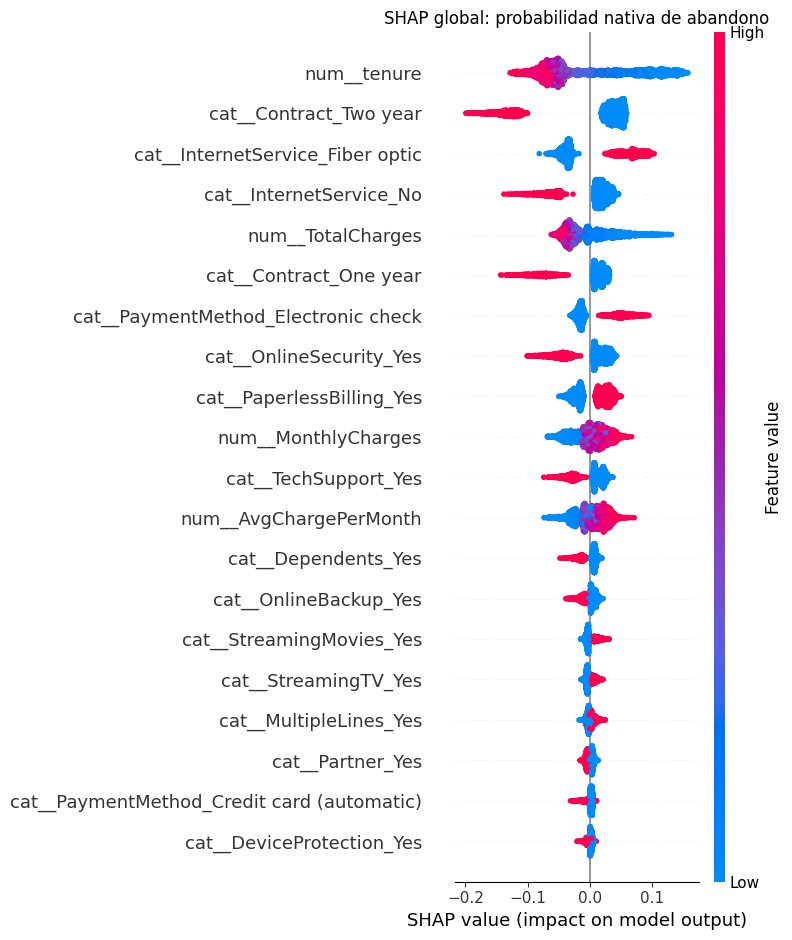

In [62]:
grafico_shap_global('random_forest__smote__bayesian_tpe')

**Interpretación.** Las mayores importancias medias absolutas agrupadas corresponden a Contract (0.0771), InternetService (0.0694), tenure (0.0675). El resumen muestra variación y signo por cliente; una importancia absoluta alta no determina por sí sola dirección causal. El error máximo de aditividad fue 1.36e-08, inferior a 10⁻⁵ en las 5.634 observaciones. Estas explicaciones caracterizan el modelo final ajustado, no una medida de generalización adicional.

Caso 4267: acierto de alta confianza. Clase observada=0; probabilidad nativa de abandono=0.0081. El identificador permite rastrear la observación sin volver a escoger un ejemplo.

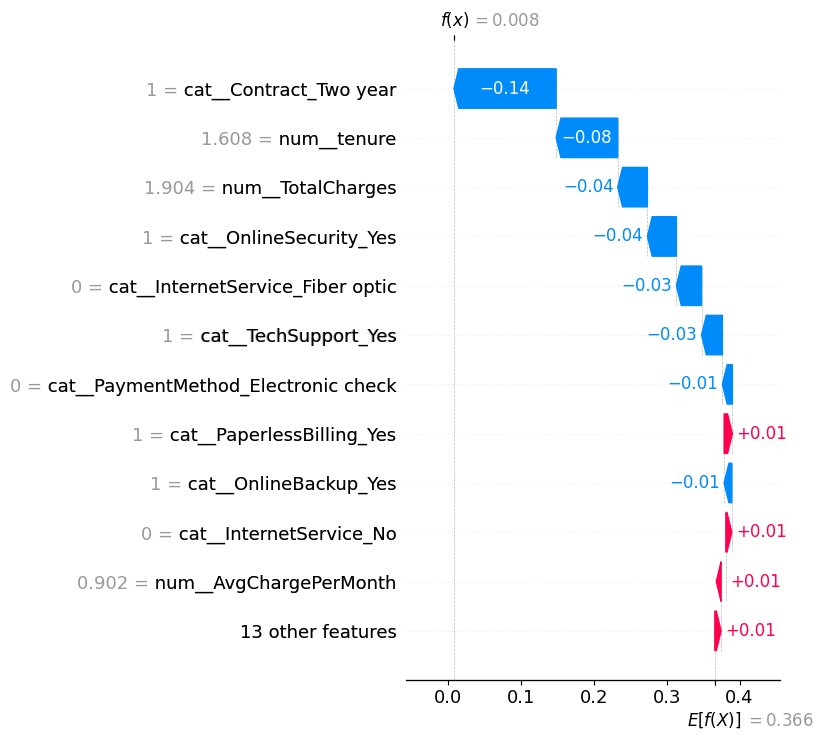

In [63]:
grafico_shap_local('random_forest__smote__bayesian_tpe', 4267)

Interpretación SHAP. Las dos contribuciones negativas de mayor magnitud son cat__Contract_Two year (-0.1402), num__tenure (-0.0845); reducen la probabilidad respecto del fondo. La etiqueta predicha de permanencia coincide con lo observado. El caso ilustra una decisión correcta, sin implicar que esas variables garanticen permanencia.

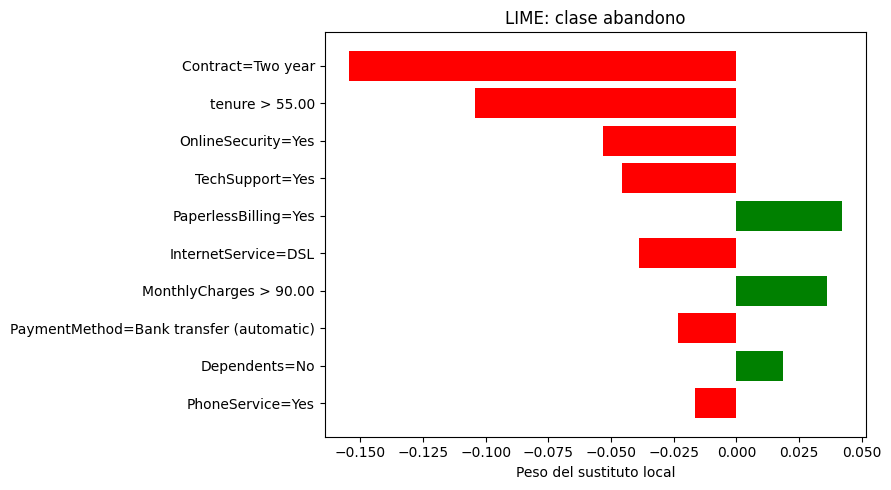

In [64]:
grafico_lime('random_forest__smote__bayesian_tpe', 4267)

Interpretación LIME. La figura corresponde a semilla 42; el sustituto local aproxima 0.0867 frente a la probabilidad real 0.0081, con R² ponderado=0.3992. Entre tres semillas, R² varió de 0.3992 a 0.4090; el Jaccard medio del top 5 fue 0.778 y el error absoluto local máximo 0.0920. La estabilidad de variables no garantiza fidelidad de probabilidad. LIME describe una aproximación local, mientras SHAP conserva aditividad; no se exige que sus pesos coincidan.

Caso 4386: error de alta confianza. Clase observada=1; probabilidad nativa de abandono=0.0153. El identificador permite rastrear la observación sin volver a escoger un ejemplo.

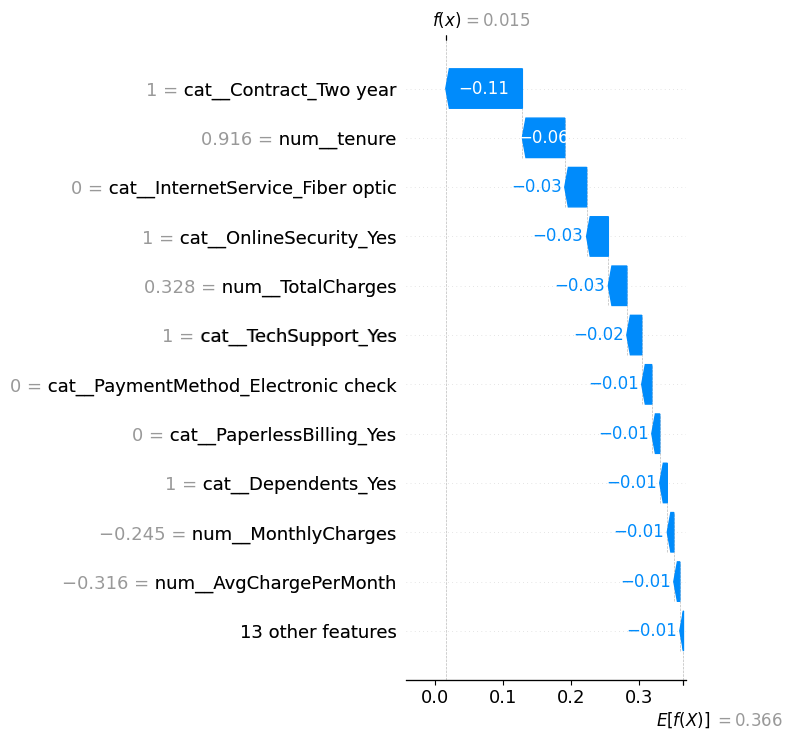

In [65]:
grafico_shap_local('random_forest__smote__bayesian_tpe', 4386)

Interpretación SHAP. Las dos contribuciones negativas de mayor magnitud son cat__Contract_Two year (-0.1130), num__tenure (-0.0626); reducen la probabilidad respecto del fondo. El cliente abandonó pese a recibir una probabilidad baja: es un falso negativo relevante para retención. Las atribuciones explican cómo se produjo la decisión equivocada; no justifican su corrección ni revelan por qué abandonó el cliente.

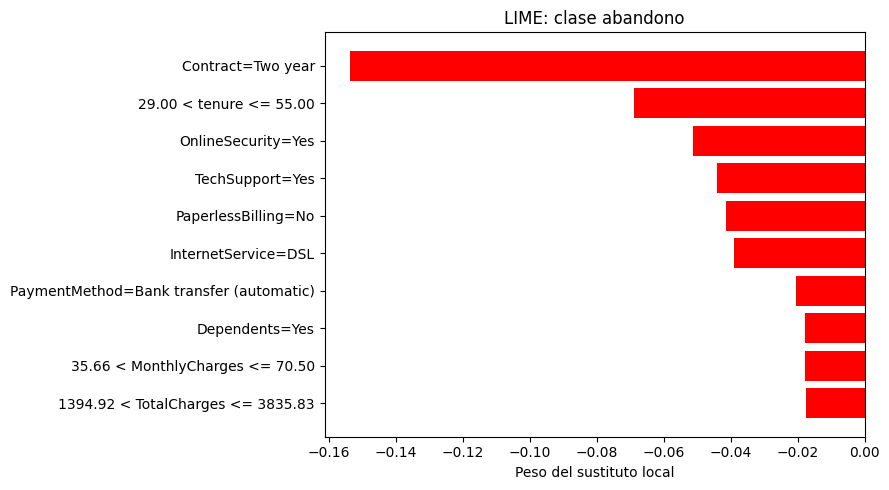

In [66]:
grafico_lime('random_forest__smote__bayesian_tpe', 4386)

Interpretación LIME. La figura corresponde a semilla 42; el sustituto local aproxima 0.0058 frente a la probabilidad real 0.0153, con R² ponderado=0.3384. Entre tres semillas, R² varió de 0.3329 a 0.3384; el Jaccard medio del top 5 fue 0.778 y el error absoluto local máximo 0.0140. La estabilidad de variables no garantiza fidelidad de probabilidad. LIME describe una aproximación local, mientras SHAP conserva aditividad; no se exige que sus pesos coincidan.

#### XGBoost: explicación global y casos locales

Las contribuciones se expresan en unidades de probabilidad respecto del fondo. El color del resumen representa el valor de la columna transformada; no cambia el signo de la contribución.

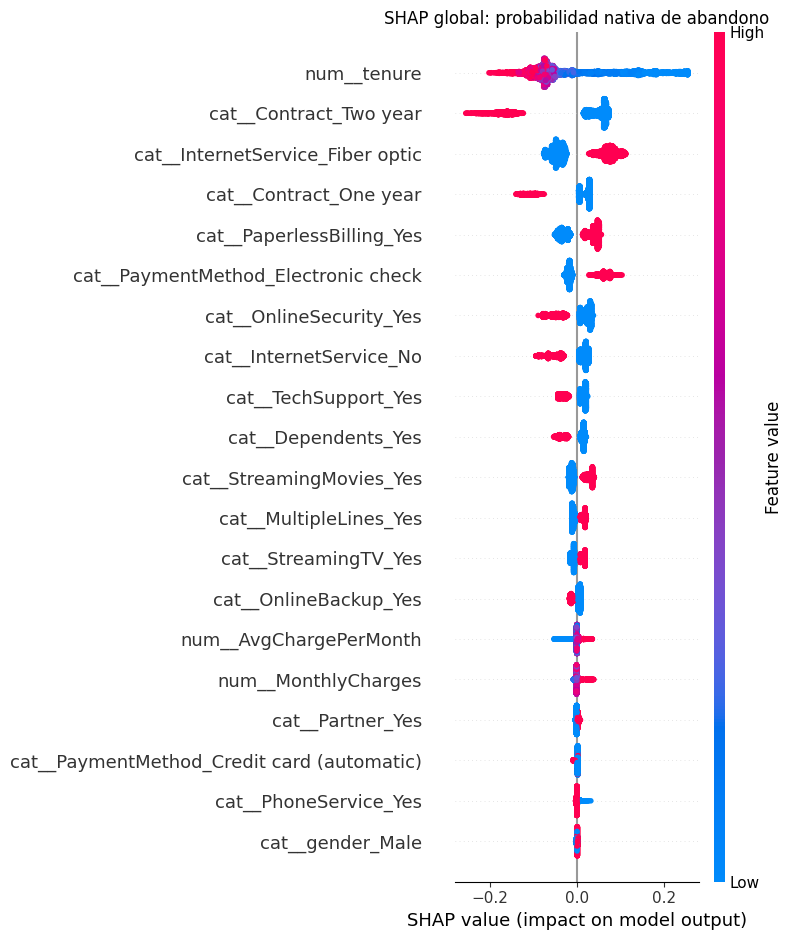

In [67]:
grafico_shap_global('xgboost__smote__random')

**Interpretación.** Las mayores importancias medias absolutas agrupadas corresponden a Contract (0.1051), tenure (0.0927), InternetService (0.0733). El resumen muestra variación y signo por cliente; una importancia absoluta alta no determina por sí sola dirección causal. El error máximo de aditividad fue 1.75e-07, inferior a 10⁻⁵ en las 5.634 observaciones. Estas explicaciones caracterizan el modelo final ajustado, no una medida de generalización adicional.

Caso 2221: acierto de alta confianza. Clase observada=0; probabilidad nativa de abandono=0.0116. El identificador permite rastrear la observación sin volver a escoger un ejemplo.

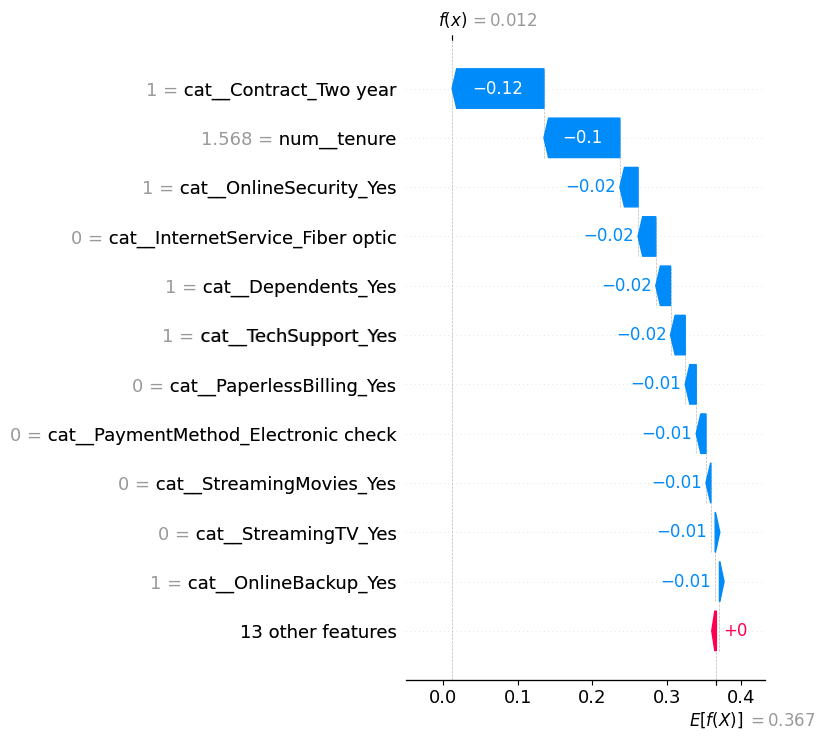

In [68]:
grafico_shap_local('xgboost__smote__random', 2221)

Interpretación SHAP. Las dos contribuciones negativas de mayor magnitud son cat__Contract_Two year (-0.1234), num__tenure (-0.1019); reducen la probabilidad respecto del fondo. La etiqueta predicha de permanencia coincide con lo observado. El caso ilustra una decisión correcta, sin implicar que esas variables garanticen permanencia.

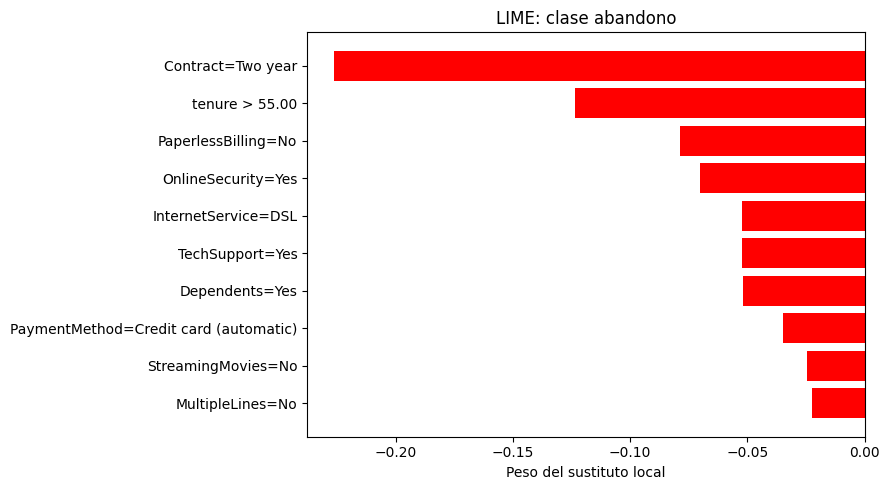

In [69]:
grafico_lime('xgboost__smote__random', 2221)

Interpretación LIME. La figura corresponde a semilla 42; el sustituto local aproxima -0.1815 frente a la probabilidad real 0.0116, con R² ponderado=0.4424. Entre tres semillas, R² varió de 0.4406 a 0.4474; el Jaccard medio del top 5 fue 1.000 y el error absoluto local máximo 0.2180. La estabilidad de variables no garantiza fidelidad de probabilidad. LIME describe una aproximación local, mientras SHAP conserva aditividad; no se exige que sus pesos coincidan.

Caso 4513: error de alta confianza. Clase observada=1; probabilidad nativa de abandono=0.0179. El identificador permite rastrear la observación sin volver a escoger un ejemplo.

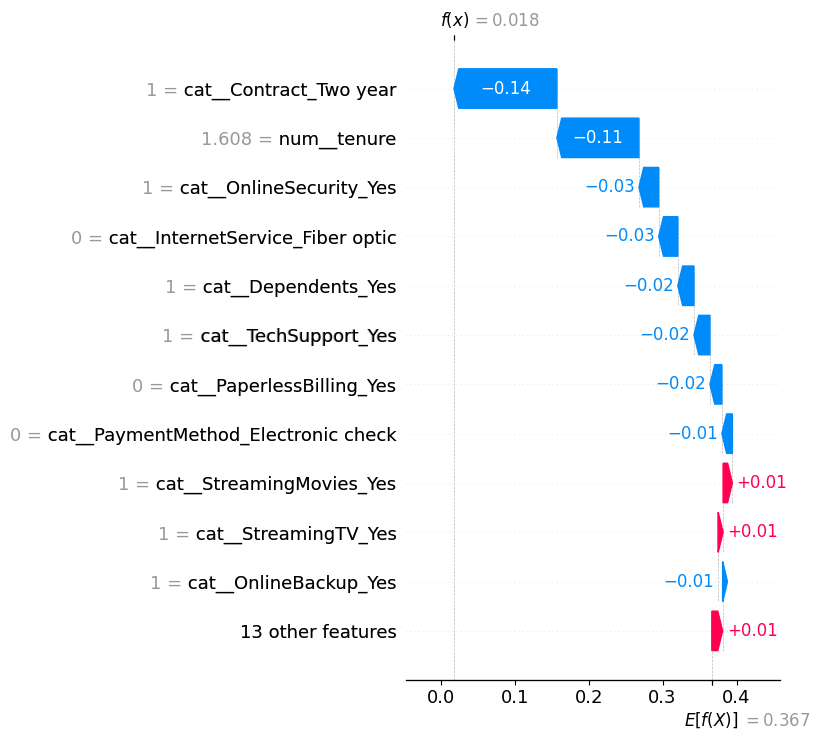

In [70]:
grafico_shap_local('xgboost__smote__random', 4513)

Interpretación SHAP. Las dos contribuciones negativas de mayor magnitud son cat__Contract_Two year (-0.1392), num__tenure (-0.1109); reducen la probabilidad respecto del fondo. El cliente abandonó pese a recibir una probabilidad baja: es un falso negativo relevante para retención. Las atribuciones explican cómo se produjo la decisión equivocada; no justifican su corrección ni revelan por qué abandonó el cliente.

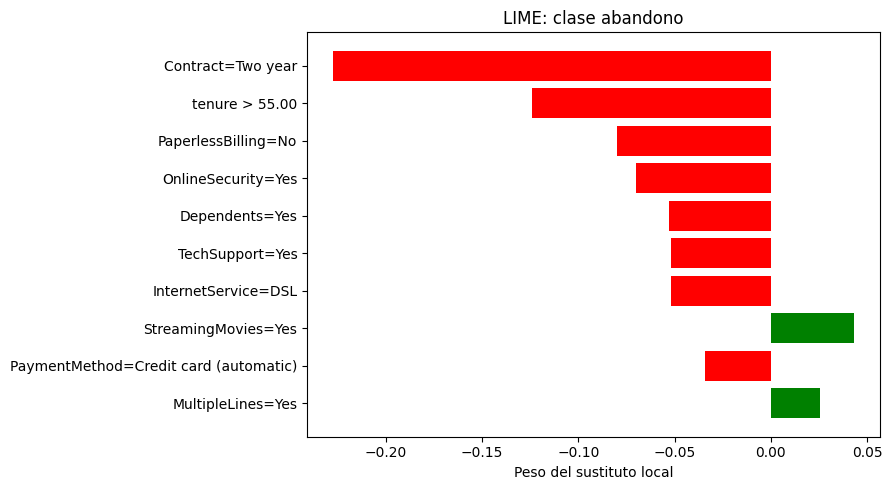

In [71]:
grafico_lime('xgboost__smote__random', 4513)

Interpretación LIME. La figura corresponde a semilla 42; el sustituto local aproxima -0.1141 frente a la probabilidad real 0.0179, con R² ponderado=0.4509. Entre tres semillas, R² varió de 0.4509 a 0.4577; el Jaccard medio del top 5 fue 0.778 y el error absoluto local máximo 0.1456. La estabilidad de variables no garantiza fidelidad de probabilidad. LIME describe una aproximación local, mientras SHAP conserva aditividad; no se exige que sus pesos coincidan.

### 3.3 Conclusiones sustentadas por los resultados

Resultado observado. Se completaron 112 configuraciones y 1.680 unidades externas. RF–SMOTE obtuvo F1=0,6384 ± 0,0227, Recall=0,7351, Precision=0,5646, Accuracy=0,7788 y AUC=0,8438 en la realización principal. XGBoost–SMOTE–Random alcanzó F1=0,6380 y la logística–SMOTE–Grid, 0,6340. Los cuatro optimizadores de RF–SMOTE empataron.

**Magnitud de las diferencias.** Entre los tres finalistas, todos los tamaños del efecto son despreciables (δ de Cliff entre −0,06 y 0,10 sobre 15 unidades): elegir uno u otro no cambia de forma apreciable el F1 esperado. Lo que sí cambia el resultado es el balanceo: SMOTE tiene efecto grande (δ ≥ 0,68) en cinco de las siete familias y solo GaussianNB no se beneficia de ninguna técnica. Los 31 pares que Nemenyi separa tienen δ = 1, es decir, son diferencias extremas; el resto no se puede separar con cinco folds. El Recall se acompañó de falsas alertas y no hay costos cuantificados para traducirlo en beneficio económico.

Conclusión sobre optimizadores. TPE, Genético y Random superan a Grid con 8 evaluaciones (efecto pareado pequeño, $d_z$≈0,45) pero no con 24, donde las diferencias son del orden de $10^{-4}$. Agotar el mismo dominio finito explica algunos empates. Successive Halving, añadido como optimización multifidelidad, alcanzó el mismo F1 externo que una búsqueda aleatoria completa en Random Forest y SVM con 3,7 y 7,1 veces menos tiempo, pero en XGBoost ahorró poco (1,6×) y eligió peor (−0,011 de F1), porque con pocos árboles el orden de los candidatos no anticipa el final.

Conclusión sobre eficiencia computacional. El costo se concentra en el núcleo de cada algoritmo, no en el Pipeline: 81 % del ajuste de SVM está en su solver y 84 % de la predicción de KNN en las distancias. SVM RBF escala como $n^{2}$, tal como predice la teoría, y sustituirlo por `LinearSVC` acelera 36 veces el entrenamiento y unas 900 la inferencia con una pérdida de F1 de 0,002. `hist` es 2,8 veces más rápido que el método exacto en XGBoost, y paralelizar da 2× en Random Forest y 1,8× en la validación cruzada. En KNN, con 24 dimensiones, los índices no aceleran y FAISS solo gana 1,36× en la consulta. No hubo GPU CUDA disponible para medir aceleración por GPU.

Conclusión sobre calibración y explicación. Platt e isotónica corrigen el sesgo que introduce el balanceo: la isotónica mejoró Brier y ECE frente a la probabilidad nativa en 84 de 96 configuraciones y Platt en 80. Entre ellas, la isotónica tuvo menor ECE en 74 de 112 configuraciones, con diferencias de Brier en la cuarta cifra decimal; conviene isotónica en GaussianNB y árboles, y Platt en SVM y KNN. SHAP identificó patrones relevantes para los modelos y permitió explicar falsos negativos seguros. LIME presentó diferencias de fidelidad entre casos; estabilidad de variables no basta para confiar en su aproximación probabilística. Ninguna explicación identifica efectos causales.

Alcance estadístico. Friedman/Nemenyi/CD permanecen exploratorios porque los folds no son bloques independientes. DeLong dirigido no detectó diferencias de AUC después de Holm; esto no prueba equivalencia. Los IC son condicionales a modelos y no incluyen selección o reentrenamiento. El test histórico estaba expuesto y es evidencia suplementaria.

RF–SMOTE se conserva como candidato operativo exploratorio, con XGBoost–SMOTE y la logística prácticamente intercambiables. Para el modelo propuesto quedan tres lecciones prácticas: balancear es lo que más pesa, la búsqueda puede ser más barata (Successive Halving en ensambles de árboles y SVM, presupuestos bajos con optimizadores secuenciales) y un modelo lineal bien calibrado compite con los no lineales en este problema. Una aplicación comercial requiere evaluación prospectiva independiente, costos de intervención explícitos y estabilidad temporal.